In [ ]:
# X-HIDS--1

from google.colab import drive
from pathlib import Path
import os
import sys
import platform
import torch
import pandas as pd
import numpy as np

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Define project directory
PROJECT_DIR = Path('/content/drive/MyDrive/X-HIDS')

# 3. Create project folders
folders = [
    'dataset',
    'notebooks',
    'models',
    'preprocessing',
    'results',
    'experiments',
    'logs',
    'dashboard',
    'reports',
    'diagrams',
    'backups'
]

for folder in folders:
    (PROJECT_DIR / folder).mkdir(
        parents=True,
        exist_ok=True
    )

# 4. Select available computing device
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# 5. Display environment information
print("=" * 55)
print("       X-HIDS PROJECT INITIALIZATION")
print("=" * 55)

print("Project directory:", PROJECT_DIR)
print("Python version:", sys.version)
print("Operating system:", platform.platform())
print("PyTorch version:", torch.__version__)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Selected device:", DEVICE)

if DEVICE == 'cuda':
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU unavailable. CPU fallback enabled.")

print("\nProject folders created successfully!")

# 6. Save environment information
environment_info = {
    "python_version": sys.version,
    "pytorch_version": torch.__version__,
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "device": DEVICE
}

import json

with open(PROJECT_DIR / 'experiments' /
          'environment_info.json', 'w') as file:
    json.dump(environment_info, file, indent=4)

print("\nEnvironment information saved to Google Drive.")
print("X-HIDS Phase 1 initialization completed.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
       X-HIDS PROJECT INITIALIZATION
Project directory: /content/drive/MyDrive/X-HIDS
Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Operating system: Linux-6.6.159+-x86_64-with-glibc2.39
PyTorch version: 2.14.1+cpu
Pandas version: 2.2.3
NumPy version: 2.4.6
Selected device: cpu
GPU unavailable. CPU fallback enabled.

Project folders created successfully!

Environment information saved to Google Drive.
X-HIDS Phase 1 initialization completed.


In [ ]:
#Dataset extraction
from pathlib import Path
import zipfile
import shutil

DATASET_DIR = Path(
    '/content/drive/MyDrive/X-HIDS/dataset'
)

ZIP_PATH = DATASET_DIR / 'GeneratedLabelledFlows.zip'

EXTRACT_DIR = DATASET_DIR / 'extracted'

# Verify ZIP file
if not ZIP_PATH.exists():
    raise FileNotFoundError(
        f"ZIP file not found: {ZIP_PATH}"
    )

print("ZIP file found:", ZIP_PATH.name)

# Create extraction folder
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

# Check ZIP integrity
with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:

    bad_file = zip_ref.testzip()

    if bad_file is not None:
        raise RuntimeError(
            f"Corrupted ZIP member: {bad_file}"
        )

    required_bytes = sum(
        item.file_size
        for item in zip_ref.infolist()
        if not item.is_dir()
    )

    free_bytes = shutil.disk_usage(
        str(EXTRACT_DIR)
    ).free

    print(
        "Uncompressed size (GB):",
        round(required_bytes / (1024**3), 2)
    )

    if required_bytes > free_bytes:
        raise RuntimeError(
            "Not enough available storage."
        )

    print("\nExtracting files...")
    zip_ref.extractall(EXTRACT_DIR)

# Find CSV files
csv_files = list(EXTRACT_DIR.rglob('*.csv'))

total_size = sum(
    f.stat().st_size for f in csv_files
)

print("\n========== EXTRACTION REPORT ==========")
print("Extraction successful!")
print("CSV files found:", len(csv_files))
print("Total CSV size (GB):",
      round(total_size / (1024**3), 2))

print("\nExtracted filenames:")

for file in sorted(csv_files):
    print(file.name)

print("\n=======================================")


ZIP file found: GeneratedLabelledFlows.zip
Uncompressed size (GB): 1.12

Extracting files...

========== EXTRACTION REPORT ==========
Extraction successful!
CSV files found: 8
Total CSV size (GB): 1.12

Extracted filenames:
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Friday-WorkingHours-Morning.pcap_ISCX.csv
Monday-WorkingHours.pcap_ISCX.csv
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Tuesday-WorkingHours.pcap_ISCX.csv
Wednesday-workingHours.pcap_ISCX.csv



In [ ]:
#Data chunking
from pathlib import Path
from collections import Counter
import pandas as pd
import json
import time

DATASET_DIR = Path(
    '/content/drive/MyDrive/X-HIDS/dataset/extracted'
)

csv_files = sorted(DATASET_DIR.rglob('*.csv'))

if len(csv_files) != 8:
    print("WARNING: Expected 8 CSV files.")
    print("Files found:", len(csv_files))

overall_labels = Counter()
file_reports = []
reference_columns = None

print("=" * 65)
print("X-HIDS: CIC-IDS2017 DATASET VALIDATION")
print("=" * 65)

for file_path in csv_files:

    print(f"\nProcessing: {file_path.name}")

    # Read only the column headers first
    header = pd.read_csv(
        file_path,
        nrows=0,
        encoding='utf-8',
        encoding_errors='replace'
    )

    columns = [
        str(col).strip()
        for col in header.columns
    ]

    # Check column consistency
    if reference_columns is None:
        reference_columns = columns
    elif set(columns) != set(reference_columns):
        print("WARNING: Column mismatch detected!")

    # Locate Label column
    label_candidates = [
        col for col in header.columns
        if str(col).strip().lower() == 'label'
    ]

    if len(label_candidates) != 1:
        raise ValueError(
            f"Could not identify one Label column in {file_path.name}"
        )

    label_column = label_candidates[0]

    file_labels = Counter()
    total_rows = 0

    # Read the file in manageable chunks
    for chunk in pd.read_csv(
        file_path,
        usecols=[label_column],
        chunksize=200_000,
        encoding='utf-8',
        encoding_errors='replace'
    ):

        labels = (
            chunk[label_column]
            .astype('string')
            .str.strip()
        )

        counts = labels.value_counts(dropna=False)

        for label, count in counts.items():
            file_labels[str(label)] += int(count)
            overall_labels[str(label)] += int(count)

        total_rows += len(chunk)

    file_reports.append({
        "filename": file_path.name,
        "rows": total_rows,
        "labels": dict(file_labels)
    })

    print("Rows:", f"{total_rows:,}")
    print("Labels:", dict(file_labels))

# Final summary
total_records = sum(
    report["rows"] for report in file_reports
)

print("\n" + "=" * 65)
print("FINAL DATASET SUMMARY")
print("=" * 65)

print("Total CSV files:", len(csv_files))
print("Total records:", f"{total_records:,}")
print("Unique labels:", len(overall_labels))

print("\nOVERALL ATTACK LABEL DISTRIBUTION:")

for label, count in overall_labels.most_common():
    percentage = (
        count / total_records * 100
        if total_records else 0
    )

    print(
        f"{label}: {count:,} records "
        f"({percentage:.2f}%)"
    )

# Save validation report
report = {
    "total_files": len(csv_files),
    "total_records": total_records,
    "unique_labels": len(overall_labels),
    "label_distribution": dict(overall_labels),
    "file_reports": file_reports
}

REPORT_PATH = (
    Path('/content/drive/MyDrive/X-HIDS/experiments')
    / 'dataset_validation_report.json'
)

with open(REPORT_PATH, 'w') as f:
    json.dump(report, f, indent=4)

print("\nValidation report saved to:")
print(REPORT_PATH)

print("\nDATASET CONTENT VALIDATION COMPLETED.")


X-HIDS: CIC-IDS2017 DATASET VALIDATION

Processing: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Rows: 225,745
Labels: {'DDoS': 128027, 'BENIGN': 97718}

Processing: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Rows: 286,467
Labels: {'PortScan': 158930, 'BENIGN': 127537}

Processing: Friday-WorkingHours-Morning.pcap_ISCX.csv
Rows: 191,033
Labels: {'BENIGN': 189067, 'Bot': 1966}

Processing: Monday-WorkingHours.pcap_ISCX.csv
Rows: 529,918
Labels: {'BENIGN': 529918}

Processing: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Rows: 288,602
Labels: {'BENIGN': 288566, 'Infiltration': 36}

Processing: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv


/tmp/ipykernel_1400/28859237.py:66: DtypeWarning: Columns (84) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(


Rows: 458,968
Labels: {'BENIGN': 168186, '<NA>': 288602, 'Web Attack � Brute Force': 1507, 'Web Attack � XSS': 652, 'Web Attack � Sql Injection': 21}

Processing: Tuesday-WorkingHours.pcap_ISCX.csv
Rows: 445,909
Labels: {'BENIGN': 432074, 'FTP-Patator': 7938, 'SSH-Patator': 5897}

Processing: Wednesday-workingHours.pcap_ISCX.csv
Rows: 692,703
Labels: {'DoS Hulk': 231073, 'BENIGN': 440031, 'DoS slowloris': 5796, 'DoS Slowhttptest': 5499, 'DoS GoldenEye': 10293, 'Heartbleed': 11}

FINAL DATASET SUMMARY
Total CSV files: 8
Total records: 3,119,345
Unique labels: 16

OVERALL ATTACK LABEL DISTRIBUTION:
BENIGN: 2,273,097 records (72.87%)
<NA>: 288,602 records (9.25%)
DoS Hulk: 231,073 records (7.41%)
PortScan: 158,930 records (5.09%)
DDoS: 128,027 records (4.10%)
DoS GoldenEye: 10,293 records (0.33%)
FTP-Patator: 7,938 records (0.25%)
SSH-Patator: 5,897 records (0.19%)
DoS slowloris: 5,796 records (0.19%)
DoS Slowhttptest: 5,499 records (0.18%)
Bot: 1,966 records (0.06%)
Web Attack � Brute Fo

In [ ]:
#Missing data filing
import pandas as pd
from pathlib import Path

EXTRACT_DIR = Path('/content/drive/MyDrive/X-HIDS/dataset/extracted')
TARGET_NAME = 'Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv'

# Dynamically search for the file to handle nested folders like 'TrafficLabelling '
found_files = list(EXTRACT_DIR.rglob(TARGET_NAME))
if not found_files:
    raise FileNotFoundError(f"Could not find '{TARGET_NAME}' anywhere inside {EXTRACT_DIR}")

FILE_PATH = found_files[0]

print("=" * 65)
print("THURSDAY WEB ATTACK FILE DIAGNOSTICS")
print(f"File located at: {FILE_PATH}")
print("=" * 65)

# 1. Inspect column names
header = pd.read_csv(
    FILE_PATH,
    nrows=0,
    encoding='utf-8',
    encoding_errors='replace'
)

print("\nTotal columns:", len(header.columns))

print("\nLast 15 column names:")

for i, col in enumerate(header.columns[-15:]):
    print(len(header.columns) - 15 + i, repr(col))

# 2. Identify the Label column
label_cols = [
    col for col in header.columns
    if str(col).strip().lower() == 'label'
]

print("\nDetected label columns:", label_cols)

if len(label_cols) != 1:
    raise ValueError("Label column is ambiguous.")

LABEL_COL = label_cols[0]

# 3. Inspect records with missing labels
missing_samples = []

for chunk in pd.read_csv(
    FILE_PATH,
    chunksize=50000,
    encoding='utf-8',
    encoding_errors='replace',
    low_memory=False
):

    missing = chunk[chunk[LABEL_COL].isna()]

    if not missing.empty:
        missing_samples.append(
            missing.iloc[:3]
        )

    if sum(len(x) for x in missing_samples) >= 10:
        break

if missing_samples:
    sample_df = pd.concat(
        missing_samples,
        ignore_index=True
    ).head(10)

    print("\nMissing-label sample records:")
    print(sample_df.iloc[:, -15:].to_string(index=False))
else:
    print("\nNo missing labels found in diagnostic scan.")

# 4. Inspect non-missing label values
print("\nLabel values and their exact representations:")

for value in (
    pd.read_csv(
        FILE_PATH,
        usecols=[LABEL_COL],
        encoding='utf-8',
        encoding_errors='replace',
        low_memory=False
    )[LABEL_COL]
    .dropna()
    .unique()
):
    print(repr(value))

print("\nDIAGNOSTIC COMPLETED.")

THURSDAY WEB ATTACK FILE DIAGNOSTICS
File located at: /content/drive/MyDrive/X-HIDS/dataset/extracted/TrafficLabelling /Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv

Total columns: 85

Last 15 column names:
70 ' Subflow Bwd Packets'
71 ' Subflow Bwd Bytes'
72 'Init_Win_bytes_forward'
73 ' Init_Win_bytes_backward'
74 ' act_data_pkt_fwd'
75 ' min_seg_size_forward'
76 'Active Mean'
77 ' Active Std'
78 ' Active Max'
79 ' Active Min'
80 'Idle Mean'
81 ' Idle Std'
82 ' Idle Max'
83 ' Idle Min'
84 ' Label'

Detected label columns: [' Label']

Missing-label sample records:
  Subflow Bwd Packets   Subflow Bwd Bytes  Init_Win_bytes_forward   Init_Win_bytes_backward   act_data_pkt_fwd   min_seg_size_forward  Active Mean   Active Std   Active Max   Active Min  Idle Mean   Idle Std   Idle Max   Idle Min  Label
                  NaN                 NaN                     NaN                       NaN                NaN                    NaN          NaN          NaN          NaN         

In [ ]:

# ============================================
# X-HIDS - EMPTY RECORD INVESTIGATION
# ============================================

import pandas as pd
from pathlib import Path

DATASET_DIR = Path(
    '/content/drive/MyDrive/X-HIDS/dataset/extracted'
)

# Locate the Thursday morning file
matches = list(DATASET_DIR.rglob(
    'Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv'
))

if not matches:
    raise FileNotFoundError("Thursday morning CSV not found.")

FILE_PATH = matches[0]

print("File:", FILE_PATH)
print("=" * 60)

total_rows = 0
fully_empty_rows = 0
label_missing_with_features = 0
valid_label_rows = 0

for chunk in pd.read_csv(
    FILE_PATH,
    chunksize=50000,
    low_memory=False,
    encoding='utf-8',
    encoding_errors='replace'
):

    # Normalize column names
    chunk.columns = chunk.columns.astype(str).str.strip()

    total_rows += len(chunk)

    # Rows where all 85 columns are missing
    empty_mask = chunk.isna().all(axis=1)

    fully_empty_rows += int(empty_mask.sum())

    # Rows with missing labels but some actual feature data
    missing_label = chunk['Label'].isna()

    partial_mask = missing_label & (~empty_mask)

    label_missing_with_features += int(partial_mask.sum())

    # Rows with available labels
    valid_label_rows += int(chunk['Label'].notna().sum())

print("\nINVESTIGATION RESULTS")
print("=" * 60)

print("Total rows:", f"{total_rows:,}")
print("Completely empty rows:", f"{fully_empty_rows:,}")
print(
    "Missing label but features present:",
    f"{label_missing_with_features:,}"
)
print("Rows with valid labels:", f"{valid_label_rows:,}")

print("\nVERIFICATION:")

if fully_empty_rows == 288602:
    print("All 288,602 suspicious rows are completely empty.")
elif fully_empty_rows > 0:
    print("Some completely empty rows were found.")
else:
    print("No completely empty rows found.")

print("\nInvestigation completed.")


File: /content/drive/MyDrive/X-HIDS/dataset/extracted/TrafficLabelling /Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv

INVESTIGATION RESULTS
Total rows: 458,968
Completely empty rows: 288,602
Missing label but features present: 0
Rows with valid labels: 170,366

VERIFICATION:
All 288,602 suspicious rows are completely empty.

Investigation completed.


In [ ]:

import pandas as pd
import json
from pathlib import Path

BASE = Path("/content/drive/MyDrive/X-HIDS/dataset")
SOURCE = BASE / "extracted"
OUTPUT = BASE / "cleaned"

OUTPUT.mkdir(parents=True, exist_ok=True)

csv_files = list(SOURCE.rglob("*.csv"))

cleaning_summary = []

for file_path in csv_files:
    print(f"\nProcessing: {file_path.name}")

    output_path = OUTPUT / file_path.name

    total_rows = 0
    removed_rows = 0
    saved_rows = 0

    first_chunk = True

    for chunk in pd.read_csv(
        file_path,
        chunksize=50000,
        low_memory=False,
        encoding="utf-8",
        encoding_errors="replace"
    ):

        total_rows += len(chunk)

        # Standardize column names
        chunk.columns = (
            chunk.columns.astype(str)
            .str.strip()
        )

        # Remove completely empty rows
        empty_mask = chunk.isna().all(axis=1)

        removed_rows += int(empty_mask.sum())

        chunk = chunk.loc[~empty_mask].copy()

        if "Label" not in chunk.columns:
            raise ValueError(
                f"Label column not found in {file_path.name}"
            )

        # Remove accidental whitespace from label values
        chunk["Label"] = chunk["Label"].astype("string").str.strip()

        # Preserve original label and create canonical label
        chunk["Label_Raw"] = chunk["Label"]

        chunk["Label_Clean"] = (
            chunk["Label"]
            .str.replace("�", "-", regex=False)
            .str.replace(r"\s+", " ", regex=True)
            .str.strip()
        )

        chunk.to_csv(
            output_path,
            mode="w" if first_chunk else "a",
            header=first_chunk,
            index=False
        )

        saved_rows += len(chunk)
        first_chunk = False

    cleaning_summary.append({
        "file": file_path.name,
        "original_rows": total_rows,
        "empty_rows_removed": removed_rows,
        "cleaned_rows": saved_rows
    })

    print("Original rows:", total_rows)
    print("Empty rows removed:", removed_rows)
    print("Cleaned rows:", saved_rows)

# Save cleaning report
report_path = BASE / "cleaning_summary.json"

with open(report_path, "w") as f:
    json.dump(cleaning_summary, f, indent=4)

print("\n===================================")
print("DATASET CLEANING COMPLETED")
print("===================================")
print("Cleaned dataset folder:", OUTPUT)
print("Cleaning report:", report_path)

print("\nTotal original rows:",
      sum(x["original_rows"] for x in cleaning_summary))

print("Total empty rows removed:",
      sum(x["empty_rows_removed"] for x in cleaning_summary))

print("Total cleaned rows:",
      sum(x["cleaned_rows"] for x in cleaning_summary))



Processing: Wednesday-workingHours.pcap_ISCX.csv
Original rows: 692703
Empty rows removed: 0
Cleaned rows: 692703

Processing: Tuesday-WorkingHours.pcap_ISCX.csv
Original rows: 445909
Empty rows removed: 0
Cleaned rows: 445909

Processing: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Original rows: 458968
Empty rows removed: 288602
Cleaned rows: 170366

Processing: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Original rows: 288602
Empty rows removed: 0
Cleaned rows: 288602

Processing: Monday-WorkingHours.pcap_ISCX.csv
Original rows: 529918
Empty rows removed: 0
Cleaned rows: 529918

Processing: Friday-WorkingHours-Morning.pcap_ISCX.csv
Original rows: 191033
Empty rows removed: 0
Cleaned rows: 191033

Processing: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Original rows: 225745
Empty rows removed: 0
Cleaned rows: 225745

Processing: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Original rows: 286467
Empty rows removed: 0
Cleaned rows: 286467

DATAS

In [ ]:
#data quality check
import pandas as pd
import numpy as np
import json
from pathlib import Path
from collections import Counter

DATA_DIR = Path("/content/drive/MyDrive/X-HIDS/dataset/cleaned")
REPORT_DIR = Path("/content/drive/MyDrive/X-HIDS/experiments")

REPORT_DIR.mkdir(parents=True, exist_ok=True)

csv_files = list(DATA_DIR.glob("*.csv"))

total_rows = 0
total_missing_cells = 0
total_infinite_values = 0

missing_counts = Counter()
infinite_counts = Counter()
non_numeric_counts = Counter()
label_counts = Counter()
column_names = set()

print("Starting data quality audit...\n")

for file_path in csv_files:

    print("Auditing:", file_path.name)

    for chunk in pd.read_csv(
        file_path,
        chunksize=50000,
        low_memory=False
    ):

        total_rows += len(chunk)
        column_names.update(chunk.columns)

        # Missing values
        missing = chunk.isna().sum()

        for col, count in missing.items():
            missing_counts[col] += int(count)

        total_missing_cells += int(missing.sum())

        # Check numerical values for infinity
        for col in chunk.columns:

            if col in ["Label", "Label_Raw", "Label_Clean"]:
                continue

            numeric = pd.to_numeric(chunk[col], errors="coerce")

            infinite_mask = np.isinf(
                numeric.to_numpy(dtype="float64", na_value=np.nan)
            )

            inf_count = int(infinite_mask.sum())

            if inf_count:
                infinite_counts[col] += inf_count
                total_infinite_values += inf_count

            # Count non-numeric values separately
            original_non_null = chunk[col].notna()
            failed_conversion = numeric.isna() & original_non_null

            non_numeric_counts[col] += int(
                failed_conversion.sum()
            )

        # Label distribution
        labels = chunk["Label_Clean"].fillna("MISSING_LABEL")
        label_counts.update(labels.value_counts().to_dict())

print("\n======================================")
print("DATA QUALITY AUDIT COMPLETED")
print("======================================")

print("Total records inspected:", total_rows)
print("Total columns:", len(column_names))
print("Total missing cells:", total_missing_cells)
print("Total infinite values:", total_infinite_values)

print("\nTop columns with missing values:")
for col, count in missing_counts.most_common(15):
    if count > 0:
        print(f"{col}: {count}")

print("\nColumns containing infinite values:")
if infinite_counts:
    for col, count in infinite_counts.items():
        print(f"{col}: {count}")
else:
    print("None detected")

print("\nColumns with non-numeric values:")
for col, count in non_numeric_counts.most_common(15):
    if count > 0:
        print(f"{col}: {count}")

print("\nAttack label distribution:")
for label, count in label_counts.most_common():
    print(f"{label}: {count}")

# Save audit report
report = {
    "total_rows": total_rows,
    "total_columns": len(column_names),
    "total_missing_cells": total_missing_cells,
    "total_infinite_values": total_infinite_values,
    "missing_by_column": dict(missing_counts),
    "infinite_by_column": dict(infinite_counts),
    "non_numeric_by_column": dict(non_numeric_counts),
    "label_distribution": dict(label_counts)
}

report_path = REPORT_DIR / "data_quality_audit.json"

with open(report_path, "w") as f:
    json.dump(report, f, indent=4)

print("\nAudit report saved to:", report_path)


Starting data quality audit...

Auditing: Wednesday-workingHours.pcap_ISCX.csv
Auditing: Tuesday-WorkingHours.pcap_ISCX.csv
Auditing: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Auditing: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Auditing: Monday-WorkingHours.pcap_ISCX.csv
Auditing: Friday-WorkingHours-Morning.pcap_ISCX.csv
Auditing: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Auditing: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv

DATA QUALITY AUDIT COMPLETED
Total records inspected: 2830743
Total columns: 87
Total missing cells: 1358
Total infinite values: 4376

Top columns with missing values:
Flow Bytes/s: 1358

Columns containing infinite values:
Flow Bytes/s: 1509
Flow Packets/s: 2867

Columns with non-numeric values:
Flow ID: 2830743
Source IP: 2830743
Destination IP: 2830743
Timestamp: 2830743

Attack label distribution:
BENIGN: 2273097
DoS Hulk: 231073
PortScan: 158930
DDoS: 128027
DoS GoldenEye: 10293
FTP-Patator: 7938
SSH-Patator: 58

In [ ]:
#dataset structure inspection

import pandas as pd
from pathlib import Path

DATA_DIR = Path("/content/drive/MyDrive/X-HIDS/dataset/cleaned")

sample_file = next(DATA_DIR.glob("*.csv"))

df = pd.read_csv(
    sample_file,
    nrows=5,
    low_memory=False
)

print("SAMPLE FILE:", sample_file.name)
print("\nTOTAL COLUMNS:", len(df.columns))

print("\nALL COLUMN NAMES:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

print("\nCOLUMN DATA TYPES:")
print(df.dtypes.to_string())

print("\nSAMPLE RECORDS:")
print(df.head(3).to_string())

print("\nLABEL COLUMN CHECK:")
print("Label_Raw exists:", "Label_Raw" in df.columns)
print("Label_Clean exists:", "Label_Clean" in df.columns)


SAMPLE FILE: Wednesday-workingHours.pcap_ISCX.csv

TOTAL COLUMNS: 87

ALL COLUMN NAMES:
1. Flow ID
2. Source IP
3. Source Port
4. Destination IP
5. Destination Port
6. Protocol
7. Timestamp
8. Flow Duration
9. Total Fwd Packets
10. Total Backward Packets
11. Total Length of Fwd Packets
12. Total Length of Bwd Packets
13. Fwd Packet Length Max
14. Fwd Packet Length Min
15. Fwd Packet Length Mean
16. Fwd Packet Length Std
17. Bwd Packet Length Max
18. Bwd Packet Length Min
19. Bwd Packet Length Mean
20. Bwd Packet Length Std
21. Flow Bytes/s
22. Flow Packets/s
23. Flow IAT Mean
24. Flow IAT Std
25. Flow IAT Max
26. Flow IAT Min
27. Fwd IAT Total
28. Fwd IAT Mean
29. Fwd IAT Std
30. Fwd IAT Max
31. Fwd IAT Min
32. Bwd IAT Total
33. Bwd IAT Mean
34. Bwd IAT Std
35. Bwd IAT Max
36. Bwd IAT Min
37. Fwd PSH Flags
38. Bwd PSH Flags
39. Fwd URG Flags
40. Bwd URG Flags
41. Fwd Header Length
42. Bwd Header Length
43. Fwd Packets/s
44. Bwd Packets/s
45. Min Packet Length
46. Max Packet Length
47. 

In [ ]:
#Duplicate features/record

import pandas as pd
from pathlib import Path

DATA_DIR = Path("/content/drive/MyDrive/X-HIDS/dataset/cleaned")

total_checked = 0
header_columns_identical = True
duplicate_rows_within_chunks = 0

for file_path in DATA_DIR.glob("*.csv"):

    print("\nChecking:", file_path.name)

    for chunk in pd.read_csv(
        file_path,
        chunksize=50000,
        low_memory=False
    ):

        total_checked += len(chunk)

        # Verify whether the two header-length columns are identical
        if (
            "Fwd Header Length" in chunk.columns
            and "Fwd Header Length.1" in chunk.columns
        ):
            if not chunk["Fwd Header Length"].equals(
                chunk["Fwd Header Length.1"]
            ):
                header_columns_identical = False

        # Count duplicate rows within each chunk
        duplicate_rows_within_chunks += int(
            chunk.duplicated().sum()
        )

print("\n======================================")
print("DUPLICATE FEATURE AUDIT")
print("======================================")

print("Total records inspected:", total_checked)

print(
    "Fwd Header Length columns identical:",
    header_columns_identical
)

print(
    "Duplicate rows found within individual chunks:",
    duplicate_rows_within_chunks
)



Checking: Wednesday-workingHours.pcap_ISCX.csv

Checking: Tuesday-WorkingHours.pcap_ISCX.csv

Checking: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv

Checking: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv

Checking: Monday-WorkingHours.pcap_ISCX.csv

Checking: Friday-WorkingHours-Morning.pcap_ISCX.csv

Checking: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv

Checking: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv

DUPLICATE FEATURE AUDIT
Total records inspected: 2830743
Fwd Header Length columns identical: True
Duplicate rows found within individual chunks: 203


In [ ]:
#feature finalisation
import pandas as pd
import json
from pathlib import Path

DATA_DIR = Path("/content/drive/MyDrive/X-HIDS/dataset/cleaned")
OUTPUT_DIR = Path("/content/drive/MyDrive/X-HIDS/preprocessing")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

sample_file = next(DATA_DIR.glob("*.csv"))

df = pd.read_csv(sample_file, nrows=10, low_memory=False)

excluded_columns = [
    "Flow ID",
    "Source IP",
    "Destination IP",
    "Timestamp",
    "Label",
    "Label_Raw",
    "Label_Clean",
    "Fwd Header Length.1"
]

target_column = "Label_Clean"

feature_columns = [
    col for col in df.columns
    if col not in excluded_columns
]

configuration = {
    "target_column": target_column,
    "feature_columns": feature_columns,
    "excluded_columns": excluded_columns,
    "number_of_features": len(feature_columns),
    "number_of_excluded_columns": len(excluded_columns)
}

print("TARGET:", target_column)
print("\nNUMBER OF FEATURES:", len(feature_columns))

print("\nSELECTED FEATURES:")
for i, col in enumerate(feature_columns, start=1):
    print(f"{i}. {col}")

print("\nEXCLUDED COLUMNS:")
for col in excluded_columns:
    print("-", col)

# Save feature configuration
config_path = OUTPUT_DIR / "feature_configuration.json"

with open(config_path, "w") as f:
    json.dump(configuration, f, indent=4)

print("\nFeature configuration saved:")
print(config_path)

assert len(feature_columns) == 79
assert target_column in df.columns
assert all(col in df.columns for col in excluded_columns)


TARGET: Label_Clean

NUMBER OF FEATURES: 79

SELECTED FEATURES:
1. Source Port
2. Destination Port
3. Protocol
4. Flow Duration
5. Total Fwd Packets
6. Total Backward Packets
7. Total Length of Fwd Packets
8. Total Length of Bwd Packets
9. Fwd Packet Length Max
10. Fwd Packet Length Min
11. Fwd Packet Length Mean
12. Fwd Packet Length Std
13. Bwd Packet Length Max
14. Bwd Packet Length Min
15. Bwd Packet Length Mean
16. Bwd Packet Length Std
17. Flow Bytes/s
18. Flow Packets/s
19. Flow IAT Mean
20. Flow IAT Std
21. Flow IAT Max
22. Flow IAT Min
23. Fwd IAT Total
24. Fwd IAT Mean
25. Fwd IAT Std
26. Fwd IAT Max
27. Fwd IAT Min
28. Bwd IAT Total
29. Bwd IAT Mean
30. Bwd IAT Std
31. Bwd IAT Max
32. Bwd IAT Min
33. Fwd PSH Flags
34. Bwd PSH Flags
35. Fwd URG Flags
36. Bwd URG Flags
37. Fwd Header Length
38. Bwd Header Length
39. Fwd Packets/s
40. Bwd Packets/s
41. Min Packet Length
42. Max Packet Length
43. Packet Length Mean
44. Packet Length Std
45. Packet Length Variance
46. FIN Flag Co

In [ ]:
#numerical features

import pandas as pd
import numpy as np
import json
from pathlib import Path

DATA_DIR = Path("/content/drive/MyDrive/X-HIDS/dataset/cleaned")
CONFIG_PATH = Path("/content/drive/MyDrive/X-HIDS/preprocessing/feature_configuration.json")
REPORT_DIR = Path("/content/drive/MyDrive/X-HIDS/experiments")

with open(CONFIG_PATH, "r") as f:
    config = json.load(f)

features = config["feature_columns"]

stats = {
    col: {
        "count": 0,
        "missing": 0,
        "infinite": 0,
        "non_numeric": 0,
        "negative": 0,
        "min": None,
        "max": None
    }
    for col in features
}

print("Starting numerical feature validation...\n")

for file_path in DATA_DIR.glob("*.csv"):

    print("Validating:", file_path.name)

    for chunk in pd.read_csv(
        file_path,
        chunksize=50000,
        low_memory=False
    ):

        for col in features:

            original = chunk[col]

            numeric = pd.to_numeric(
                original,
                errors="coerce"
            )

            s = stats[col]

            s["missing"] += int(original.isna().sum())

            s["non_numeric"] += int(
                (original.notna() & numeric.isna()).sum()
            )

            values = numeric.to_numpy(
                dtype="float64",
                na_value=np.nan
            )

            infinite_mask = np.isinf(values)
            finite_mask = np.isfinite(values)

            s["infinite"] += int(infinite_mask.sum())

            finite_values = values[finite_mask]

            if len(finite_values) > 0:

                s["count"] += len(finite_values)

                chunk_min = float(finite_values.min())
                chunk_max = float(finite_values.max())

                if s["min"] is None or chunk_min < s["min"]:
                    s["min"] = chunk_min

                if s["max"] is None or chunk_max > s["max"]:
                    s["max"] = chunk_max

                s["negative"] += int(
                    (finite_values < 0).sum()
                )

print("\n======================================")
print("NUMERICAL FEATURE VALIDATION RESULTS")
print("======================================")

for col, s in stats.items():

    print(f"\nFeature: {col}")
    print("Finite values:", s["count"])
    print("Missing:", s["missing"])
    print("Infinite:", s["infinite"])
    print("Non-numeric:", s["non_numeric"])
    print("Negative:", s["negative"])
    print("Minimum:", s["min"])
    print("Maximum:", s["max"])

constant_features = [
    col for col, s in stats.items()
    if s["count"] > 0 and s["min"] == s["max"]
]

print("\n======================================")
print("FINAL SUMMARY")
print("======================================")

print("Total selected features:", len(features))
print("Constant features:", constant_features)

print(
    "Features with missing values:",
    [c for c, s in stats.items() if s["missing"] > 0]
)

print(
    "Features with infinite values:",
    [c for c, s in stats.items() if s["infinite"] > 0]
)

print(
    "Features with non-numeric values:",
    [c for c, s in stats.items() if s["non_numeric"] > 0]
)

report_path = REPORT_DIR / "numerical_feature_validation.json"

with open(report_path, "w") as f:
    json.dump({
        "feature_statistics": stats,
        "constant_features": constant_features
    }, f, indent=4)

print("\nReport saved:", report_path)
print("\nFEATURE VALIDATION COMPLETED.")


Starting numerical feature validation...

Validating: Wednesday-workingHours.pcap_ISCX.csv
Validating: Tuesday-WorkingHours.pcap_ISCX.csv
Validating: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Validating: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Validating: Monday-WorkingHours.pcap_ISCX.csv
Validating: Friday-WorkingHours-Morning.pcap_ISCX.csv
Validating: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Validating: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv

NUMERICAL FEATURE VALIDATION RESULTS

Feature: Source Port
Finite values: 2830743
Missing: 0
Infinite: 0
Non-numeric: 0
Negative: 0
Minimum: 0.0
Maximum: 65535.0

Feature: Destination Port
Finite values: 2830743
Missing: 0
Infinite: 0
Non-numeric: 0
Negative: 0
Minimum: 0.0
Maximum: 65535.0

Feature: Protocol
Finite values: 2830743
Missing: 0
Infinite: 0
Non-numeric: 0
Negative: 0
Minimum: 0.0
Maximum: 17.0

Feature: Flow Duration
Finite values: 2830743
Missing: 0
Infinite: 0
Non-numeric: 0


In [ ]:
#negative values

import pandas as pd
import numpy as np
from pathlib import Path
from collections import defaultdict

DATA_DIR = Path("/content/drive/MyDrive/X-HIDS/dataset/cleaned")

check_features = [
    "Flow Duration",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Flow IAT Mean",
    "Flow IAT Max",
    "Flow IAT Min",
    "Fwd IAT Min",
    "Fwd Header Length",
    "Bwd Header Length",
    "Init_Win_bytes_forward",
    "Init_Win_bytes_backward",
    "min_seg_size_forward"
]

negative_counts = defaultdict(int)
minimum_values = {}
sample_records = defaultdict(list)

print("Investigating negative feature values...\n")

for file_path in DATA_DIR.glob("*.csv"):

    print("Checking:", file_path.name)

    for chunk in pd.read_csv(
        file_path,
        chunksize=50000,
        low_memory=False
    ):

        for col in check_features:

            values = pd.to_numeric(
                chunk[col],
                errors="coerce"
            )

            negative_mask = values < 0
            count = int(negative_mask.sum())

            negative_counts[col] += count

            if count > 0:

                current_min = float(values[negative_mask].min())

                if (
                    col not in minimum_values
                    or current_min < minimum_values[col]
                ):
                    minimum_values[col] = current_min

                if len(sample_records[col]) < 5:

                    selected = chunk.loc[
                        negative_mask,
                        [col, "Label_Clean"]
                    ].head(5 - len(sample_records[col]))

                    sample_records[col].extend(
                        selected.to_dict("records")
                    )

print("\n======================================")
print("NEGATIVE VALUE INVESTIGATION")
print("======================================")

for col in check_features:

    print(f"\nFeature: {col}")
    print("Negative count:", negative_counts[col])

    if col in minimum_values:
        print("Minimum negative value:", minimum_values[col])
        print("Example records:")

        for record in sample_records[col]:
            print(record)

print("\nINVESTIGATION COMPLETED.")


Investigating negative feature values...

Checking: Wednesday-workingHours.pcap_ISCX.csv
Checking: Tuesday-WorkingHours.pcap_ISCX.csv
Checking: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Checking: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Checking: Monday-WorkingHours.pcap_ISCX.csv
Checking: Friday-WorkingHours-Morning.pcap_ISCX.csv
Checking: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Checking: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv

NEGATIVE VALUE INVESTIGATION

Feature: Flow Duration
Negative count: 115
Minimum negative value: -13.0
Example records:
{'Flow Duration': -1, 'Label_Clean': 'BENIGN'}
{'Flow Duration': -1, 'Label_Clean': 'BENIGN'}
{'Flow Duration': -1, 'Label_Clean': 'BENIGN'}
{'Flow Duration': -1, 'Label_Clean': 'BENIGN'}
{'Flow Duration': -1, 'Label_Clean': 'BENIGN'}

Feature: Flow Bytes/s
Negative count: 85
Minimum negative value: -261000000.0
Example records:
{'Flow Bytes/s': -12000000.0, 'Label_Clean': 'BENIGN'}
{'Flow

In [ ]:
#datacleaning policy
import os
import json
from datetime import datetime

BASE_DIR = "/content/drive/MyDrive/X-HIDS"

# Negative values that will be treated as invalid
# and converted to NaN during preprocessing.
NEGATIVE_TO_MISSING = [
    "Flow Duration",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Flow IAT Mean",
    "Flow IAT Max",
    "Flow IAT Min",
    "Fwd IAT Min",
    "Fwd Header Length",
    "Bwd Header Length",
    "min_seg_size_forward"
]

# Preserve -1 because it is used as a special
# unavailable/unknown indicator in these features.
PRESERVE_NEGATIVE_SENTINEL = [
    "Init_Win_bytes_forward",
    "Init_Win_bytes_backward"
]

# Features identified as constant during the audit.
CONSTANT_FEATURES_TO_REMOVE = [
    "Bwd PSH Flags",
    "Bwd URG Flags",
    "Fwd Avg Bytes/Bulk",
    "Fwd Avg Packets/Bulk",
    "Fwd Avg Bulk Rate",
    "Bwd Avg Bytes/Bulk",
    "Bwd Avg Packets/Bulk",
    "Bwd Avg Bulk Rate"
]

policy = {
    "project": "X-HIDS",
    "target_column": "Label_Clean",
    "original_selected_features": 79,
    "constant_features_to_remove": CONSTANT_FEATURES_TO_REMOVE,
    "expected_remaining_features": 71,
    "negative_to_missing": NEGATIVE_TO_MISSING,
    "preserve_negative_sentinel": PRESERVE_NEGATIVE_SENTINEL,
    "infinity_handling": "Replace positive and negative infinity with NaN",
    "missing_value_handling": (
        "Use median imputation fitted only on the training data"
    ),
    "source_files_modified": False,
    "created_at": datetime.now().isoformat()
}

output_path = os.path.join(
    BASE_DIR, "preprocessing", "data_cleaning_policy.json"
)

with open(output_path, "w") as f:
    json.dump(policy, f, indent=4)

print("DATA-CLEANING POLICY SAVED SUCCESSFULLY")
print("---------------------------------------")
print("Invalid-negative features:", len(NEGATIVE_TO_MISSING))
print("Preserved sentinel features:", len(PRESERVE_NEGATIVE_SENTINEL))
print("Constant features to remove:", len(CONSTANT_FEATURES_TO_REMOVE))
print("Expected final feature count:", 71)
print("Original cleaned CSV files modified: No")
print("Saved at:", output_path)


DATA-CLEANING POLICY SAVED SUCCESSFULLY
---------------------------------------
Invalid-negative features: 10
Preserved sentinel features: 2
Constant features to remove: 8
Expected final feature count: 71
Original cleaned CSV files modified: No
Saved at: /content/drive/MyDrive/X-HIDS/preprocessing/data_cleaning_policy.json


In [ ]:
#final feature config
import os
import json
import pandas as pd
from datetime import datetime

BASE_DIR = "/content/drive/MyDrive/X-HIDS"

CLEANED_DIR = os.path.join(BASE_DIR, "dataset", "cleaned")
OUTPUT_DIR = os.path.join(BASE_DIR, "preprocessing")

# Read column names from an actual cleaned dataset
csv_files = [
    f for f in os.listdir(CLEANED_DIR)
    if f.lower().endswith(".csv")
]

if not csv_files:
    raise FileNotFoundError("No cleaned CSV files found.")

sample_path = os.path.join(CLEANED_DIR, csv_files[0])
columns = pd.read_csv(sample_path, nrows=0).columns.tolist()

# Columns that must not be used as model features
excluded_columns = [
    "Flow ID",
    "Source IP",
    "Destination IP",
    "Timestamp",
    "Label",
    "Label_Raw",
    "Label_Clean",
    "Fwd Header Length.1"
]

# Constant features identified in the data audit
constant_features = [
    "Bwd PSH Flags",
    "Bwd URG Flags",
    "Fwd Avg Bytes/Bulk",
    "Fwd Avg Packets/Bulk",
    "Fwd Avg Bulk Rate",
    "Bwd Avg Bytes/Bulk",
    "Bwd Avg Packets/Bulk",
    "Bwd Avg Bulk Rate"
]

# Build final feature list
final_features = [
    col for col in columns
    if col not in excluded_columns
    and col not in constant_features
]

# Validate configuration
print("Final feature count:", len(final_features))

if len(final_features) != 71:
    raise ValueError(
        f"Expected 71 features, but found {len(final_features)}. "
        "Stop here and share the output."
    )

if "Label_Clean" not in columns:
    raise ValueError("Target column Label_Clean is missing.")

configuration = {
    "project": "X-HIDS",
    "target_column": "Label_Clean",
    "feature_count": len(final_features),
    "features": final_features,
    "excluded_metadata_and_label_columns": excluded_columns,
    "excluded_constant_features": constant_features,
    "source_dataset": "CIC-IDS2017 cleaned CSV collection",
    "created_at": datetime.now().isoformat()
}

output_path = os.path.join(
    OUTPUT_DIR, "final_feature_configuration.json"
)

with open(output_path, "w") as f:
    json.dump(configuration, f, indent=4)

print("\nFINAL FEATURE CONFIGURATION SAVED")
print("---------------------------------")
for i, feature in enumerate(final_features, start=1):
    print(f"{i:02d}. {feature}")

print("\nTarget column:", configuration["target_column"])
print("Total final features:", len(final_features))
print("Saved at:", output_path)


Final feature count: 71

FINAL FEATURE CONFIGURATION SAVED
---------------------------------
01. Source Port
02. Destination Port
03. Protocol
04. Flow Duration
05. Total Fwd Packets
06. Total Backward Packets
07. Total Length of Fwd Packets
08. Total Length of Bwd Packets
09. Fwd Packet Length Max
10. Fwd Packet Length Min
11. Fwd Packet Length Mean
12. Fwd Packet Length Std
13. Bwd Packet Length Max
14. Bwd Packet Length Min
15. Bwd Packet Length Mean
16. Bwd Packet Length Std
17. Flow Bytes/s
18. Flow Packets/s
19. Flow IAT Mean
20. Flow IAT Std
21. Flow IAT Max
22. Flow IAT Min
23. Fwd IAT Total
24. Fwd IAT Mean
25. Fwd IAT Std
26. Fwd IAT Max
27. Fwd IAT Min
28. Bwd IAT Total
29. Bwd IAT Mean
30. Bwd IAT Std
31. Bwd IAT Max
32. Bwd IAT Min
33. Fwd PSH Flags
34. Fwd URG Flags
35. Fwd Header Length
36. Bwd Header Length
37. Fwd Packets/s
38. Bwd Packets/s
39. Min Packet Length
40. Max Packet Length
41. Packet Length Mean
42. Packet Length Std
43. Packet Length Variance
44. FIN Flag 

In [ ]:

!pip -q install pyarrow
print("Parquet support installed successfully.")


Parquet support installed successfully.


In [ ]:

import os
import json
import glob
import pandas as pd
import numpy as np
from datetime import datetime

BASE_DIR = "/content/drive/MyDrive/X-HIDS"
CLEANED_DIR = os.path.join(BASE_DIR, "dataset", "cleaned")
OUTPUT_DIR = os.path.join(BASE_DIR, "dataset", "model_ready_v1")

CHUNK_SIZE = 50000

# Load final feature configuration
config_path = os.path.join(
    BASE_DIR, "preprocessing", "final_feature_configuration.json"
)

with open(config_path, "r") as f:
    config = json.load(f)

FEATURES = config["features"]
TARGET = config["target_column"]

# Load cleaning policy
policy_path = os.path.join(
    BASE_DIR, "preprocessing", "data_cleaning_policy.json"
)

with open(policy_path, "r") as f:
    policy = json.load(f)

NEGATIVE_TO_MISSING = policy["negative_to_missing"]
PRESERVE_SENTINELS = policy["preserve_negative_sentinel"]

# Prevent accidental overwriting of an earlier dataset
if os.path.exists(OUTPUT_DIR) and os.listdir(OUTPUT_DIR):
    raise FileExistsError(
        "Output folder already contains files. "
        "Rename it or choose a new output folder before proceeding."
    )

os.makedirs(OUTPUT_DIR, exist_ok=True)

csv_files = sorted(glob.glob(
    os.path.join(CLEANED_DIR, "*.csv")
))

# Also include CSVs inside subdirectories
csv_files += sorted(glob.glob(
    os.path.join(CLEANED_DIR, "**", "*.csv"),
    recursive=True
))

csv_files = sorted(set(csv_files))

if not csv_files:
    raise FileNotFoundError("No cleaned CSV files found.")

total_rows = 0
removed_rows = 0
part_number = 0
label_counts = {}

print("Starting model-ready dataset preparation...\n")

for csv_path in csv_files:
    print("Processing:", os.path.basename(csv_path))

    for chunk in pd.read_csv(
        csv_path,
        usecols=FEATURES + [TARGET],
        chunksize=CHUNK_SIZE,
        low_memory=True
    ):
        original_count = len(chunk)

        # Clean target labels
        chunk[TARGET] = chunk[TARGET].astype("string").str.strip()
        chunk = chunk.dropna(subset=[TARGET])
        chunk = chunk[chunk[TARGET] != ""]

        # Convert all model features to numeric float32
        for col in FEATURES:
            chunk[col] = pd.to_numeric(
                chunk[col], errors="coerce"
            ).astype("float32")

        # Replace positive and negative infinity
        chunk[FEATURES] = chunk[FEATURES].replace(
            [np.inf, -np.inf], np.nan
        )

        # Replace invalid negative values with missing values
        # The two initial-window sentinel features are excluded.
        for col in NEGATIVE_TO_MISSING:
            chunk.loc[chunk[col] < 0, col] = np.nan

        # Preserve -1 in the two initial-window features
        # Other negative values in these columns are not expected.
        for col in PRESERVE_SENTINELS:
            chunk.loc[chunk[col] < -1, col] = np.nan

        # Save class counts
        counts = chunk[TARGET].value_counts()
        for label, count in counts.items():
            label_counts[str(label)] = (
                label_counts.get(str(label), 0) + int(count)
            )

        # Save each processed chunk separately
        output_path = os.path.join(
            OUTPUT_DIR, f"part_{part_number:04d}.parquet"
        )

        chunk.to_parquet(
            output_path,
            index=False,
            compression="snappy"
        )

        total_rows += len(chunk)
        removed_rows += original_count - len(chunk)
        part_number += 1

    print("Completed:", os.path.basename(csv_path))

# Save preparation summary
summary = {
    "project": "X-HIDS",
    "created_at": datetime.now().isoformat(),
    "source_files": len(csv_files),
    "feature_count": len(FEATURES),
    "target_column": TARGET,
    "total_model_ready_rows": total_rows,
    "rows_removed_for_invalid_target": removed_rows,
    "parquet_parts": part_number,
    "storage_format": "Parquet with Snappy compression",
    "feature_dtype": "float32",
    "label_distribution": label_counts,
    "output_directory": OUTPUT_DIR
}

summary_path = os.path.join(
    BASE_DIR, "experiments", "model_ready_dataset_summary.json"
)

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=4)

print("\n====================================")
print("MODEL-READY DATASET PREPARATION DONE")
print("====================================")
print("Total rows:", f"{total_rows:,}")
print("Features:", len(FEATURES))
print("Target:", TARGET)
print("Parquet parts:", part_number)
print("Rows removed:", f"{removed_rows:,}")
print("Output:", OUTPUT_DIR)
print("Summary:", summary_path)
print("\nClass distribution:")
for label, count in sorted(
    label_counts.items(), key=lambda x: x[1], reverse=True
):
    print(f"{label}: {count:,}")


Starting model-ready dataset preparation...

Processing: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Completed: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Processing: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Completed: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Processing: Friday-WorkingHours-Morning.pcap_ISCX.csv
Completed: Friday-WorkingHours-Morning.pcap_ISCX.csv
Processing: Monday-WorkingHours.pcap_ISCX.csv
Completed: Monday-WorkingHours.pcap_ISCX.csv
Processing: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Completed: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Processing: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Completed: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Processing: Tuesday-WorkingHours.pcap_ISCX.csv
Completed: Tuesday-WorkingHours.pcap_ISCX.csv
Processing: Wednesday-workingHours.pcap_ISCX.csv
Completed: Wednesday-workingHours.pcap_ISCX.csv

MODEL-READY DATASET PREPARATION DONE
Tot

In [ ]:

import os
import glob
import json
import numpy as np
import pandas as pd
from collections import Counter

BASE_DIR = "/content/drive/MyDrive/X-HIDS"
DATA_DIR = os.path.join(BASE_DIR, "dataset", "model_ready_v1")

with open(
    os.path.join(BASE_DIR, "preprocessing",
                 "final_feature_configuration.json")
) as f:
    config = json.load(f)

FEATURES = config["features"]
TARGET = config["target_column"]

parquet_files = sorted(
    glob.glob(os.path.join(DATA_DIR, "*.parquet"))
)

if len(parquet_files) != 59:
    print("Warning: Expected 59 files, found:", len(parquet_files))

total_rows = 0
missing_counts = Counter()
infinite_counts = Counter()
label_counts = Counter()
sentinel_counts = Counter()
invalid_negative_counts = Counter()

print("Auditing Parquet dataset...\n")

for file_path in parquet_files:
    df = pd.read_parquet(file_path)

    expected_columns = set(FEATURES + [TARGET])
    if set(df.columns) != expected_columns:
        raise ValueError(
            f"Unexpected columns in {os.path.basename(file_path)}"
        )

    total_rows += len(df)

    for col in FEATURES:
        values = df[col].to_numpy(dtype=np.float64)

        missing_counts[col] += int(df[col].isna().sum())
        infinite_counts[col] += int(np.isinf(values).sum())

    label_counts.update(
        df[TARGET].value_counts().to_dict()
    )

    for col in ["Init_Win_bytes_forward",
                "Init_Win_bytes_backward"]:
        sentinel_counts[col] += int((df[col] == -1).sum())

    # Check whether invalid negatives remain
    policy_path = os.path.join(
        BASE_DIR, "preprocessing", "data_cleaning_policy.json"
    )
    with open(policy_path) as f:
        policy = json.load(f)

    for col in policy["negative_to_missing"]:
        invalid_negative_counts[col] += int(
            (df[col] < 0).sum()
        )

print("====================================")
print("FINAL DATASET INTEGRITY AUDIT")
print("====================================")
print("Parquet files:", len(parquet_files))
print("Total rows:", f"{total_rows:,}")
print("Features:", len(FEATURES))
print("Columns including target:", len(FEATURES) + 1)

print("\nMissing values:")
missing_total = sum(missing_counts.values())
print("Total missing feature cells:", f"{missing_total:,}")

for col, count in missing_counts.items():
    if count:
        print(f"{col}: {count:,}")

print("\nInfinite values:")
infinite_total = sum(infinite_counts.values())
print("Total infinite values:", f"{infinite_total:,}")

print("\nRemaining invalid negative values:")
negative_total = sum(invalid_negative_counts.values())
print("Total:", f"{negative_total:,}")

for col, count in invalid_negative_counts.items():
    if count:
        print(f"{col}: {count:,}")

print("\nPreserved -1 sentinel counts:")
for col, count in sentinel_counts.items():
    print(f"{col}: {count:,}")

print("\nClass distribution:")
for label, count in label_counts.most_common():
    print(f"{label}: {count:,}")

# Save audit report
audit = {
    "parquet_files": len(parquet_files),
    "total_rows": total_rows,
    "feature_count": len(FEATURES),
    "missing_feature_cells": missing_total,
    "missing_by_feature": dict(missing_counts),
    "infinite_feature_cells": infinite_total,
    "remaining_invalid_negative_values": negative_total,
    "invalid_negative_by_feature": dict(invalid_negative_counts),
    "preserved_sentinel_counts": dict(sentinel_counts),
    "class_distribution": dict(label_counts)
}

audit_path = os.path.join(
    BASE_DIR, "experiments",
    "model_ready_integrity_audit.json"
)

with open(audit_path, "w") as f:
    json.dump(audit, f, indent=4)

print("\nAudit saved at:", audit_path)

if infinite_total == 0 and negative_total == 0:
    print("\nSUCCESS: No infinite or invalid negative values remain.")
else:
    print("\nREVIEW REQUIRED: Check the values reported above.")


Auditing Parquet dataset...

FINAL DATASET INTEGRITY AUDIT
Parquet files: 59
Total rows: 2,830,743
Features: 71
Columns including target: 72

Missing values:
Total missing feature cells: 9,279
Flow Duration: 115
Flow Bytes/s: 2,952
Flow Packets/s: 2,982
Flow IAT Mean: 115
Flow IAT Max: 115
Flow IAT Min: 2,891
Fwd IAT Min: 17
Fwd Header Length: 35
Bwd Header Length: 22
min_seg_size_forward: 35

Infinite values:
Total infinite values: 0

Remaining invalid negative values:
Total: 0

Preserved -1 sentinel counts:
Init_Win_bytes_forward: 1,001,189
Init_Win_bytes_backward: 1,441,552

Class distribution:
BENIGN: 2,273,097
DoS Hulk: 231,073
PortScan: 158,930
DDoS: 128,027
DoS GoldenEye: 10,293
FTP-Patator: 7,938
SSH-Patator: 5,897
DoS slowloris: 5,796
DoS Slowhttptest: 5,499
Bot: 1,966
Web Attack - Brute Force: 1,507
Web Attack - XSS: 652
Infiltration: 36
Web Attack - Sql Injection: 21
Heartbleed: 11

Audit saved at: /content/drive/MyDrive/X-HIDS/experiments/model_ready_integrity_audit.json

S

In [ ]:

import os
import glob
import json
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

BASE_DIR = "/content/drive/MyDrive/X-HIDS"
DATA_DIR = os.path.join(BASE_DIR, "dataset", "model_ready_v1")
OUTPUT_DIR = os.path.join(BASE_DIR, "experiments")

SEED = 42
TARGET = "Label_Clean"

# Load expected class distribution
summary_path = os.path.join(
    OUTPUT_DIR, "model_ready_dataset_summary.json"
)

with open(summary_path, "r") as f:
    summary = json.load(f)

expected_rows = summary["total_model_ready_rows"]
classes = sorted(summary["label_distribution"].keys())

parquet_files = sorted(
    glob.glob(os.path.join(DATA_DIR, "*.parquet"))
)

if not parquet_files:
    raise FileNotFoundError("No Parquet files found.")

# Store only compact integer class codes in RAM
class_to_code = {
    label: index for index, label in enumerate(classes)
}

y_codes = np.empty(expected_rows, dtype=np.int8)

position = 0

print("Reading labels from Parquet files...")

for file_path in parquet_files:
    labels = pd.read_parquet(
        file_path, columns=[TARGET]
    )[TARGET].astype(str)

    codes = labels.map(class_to_code).to_numpy(dtype=np.int8)

    if np.any(codes < 0):
        raise ValueError("Unknown class label encountered.")

    end_position = position + len(codes)
    y_codes[position:end_position] = codes
    position = end_position

if position != expected_rows:
    raise ValueError(
        f"Row count mismatch: expected {expected_rows}, got {position}"
    )

print("Labels loaded:", f"{position:,}")
print("Number of classes:", len(classes))

# Global row indices refer to sorted Parquet file order
all_indices = np.arange(expected_rows, dtype=np.int32)

# 70% train, 30% temporary
train_idx, temp_idx = train_test_split(
    all_indices,
    test_size=0.30,
    random_state=SEED,
    stratify=y_codes
)

# Divide temporary set equally into 15% validation and 15% test
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=y_codes[temp_idx]
)

# Sort indices for efficient sequential processing later
train_idx.sort()
val_idx.sort()
test_idx.sort()

# Verify that every row belongs to exactly one split
if (
    len(train_idx) + len(val_idx) + len(test_idx)
    != expected_rows
):
    raise ValueError("Split size verification failed.")

if (
    np.intersect1d(train_idx, val_idx).size
    or np.intersect1d(train_idx, test_idx).size
    or np.intersect1d(val_idx, test_idx).size
):
    raise ValueError("Data leakage: overlapping split indices.")

# Save reproducible split indices
split_path = os.path.join(
    OUTPUT_DIR, "stratified_split_indices.npz"
)

np.savez_compressed(
    split_path,
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx
)

# Calculate class counts per split
split_summary = {}

for split_name, indices in [
    ("train", train_idx),
    ("validation", val_idx),
    ("test", test_idx)
]:
    counts = np.bincount(
        y_codes[indices], minlength=len(classes)
    )

    split_summary[split_name] = {
        classes[i]: int(counts[i])
        for i in range(len(classes))
    }

# Save experiment metadata
metadata = {
    "random_seed": SEED,
    "strategy": "Stratified random row-level split",
    "train_percentage": 70,
    "validation_percentage": 15,
    "test_percentage": 15,
    "total_rows": expected_rows,
    "train_rows": len(train_idx),
    "validation_rows": len(val_idx),
    "test_rows": len(test_idx),
    "classes": classes,
    "class_distribution": split_summary,
    "parquet_files_order": [
        os.path.basename(p) for p in parquet_files
    ],
    "indices_file": split_path
}

metadata_path = os.path.join(
    OUTPUT_DIR, "split_metadata.json"
)

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print("\n====================================")
print("STRATIFIED SPLIT CREATED SUCCESSFULLY")
print("====================================")
print("Training:", f"{len(train_idx):,}",
      f"({len(train_idx)/expected_rows*100:.2f}%)")
print("Validation:", f"{len(val_idx):,}",
      f"({len(val_idx)/expected_rows*100:.2f}%)")
print("Testing:", f"{len(test_idx):,}",
      f"({len(test_idx)/expected_rows*100:.2f}%)")

print("\nClass distribution by split:")
for split_name, counts in split_summary.items():
    print(f"\n{split_name.upper()}")
    for label, count in counts.items():
        print(f"{label}: {count:,}")

print("\nSaved indices:", split_path)
print("Saved metadata:", metadata_path)


Reading labels from Parquet files...
Labels loaded: 2,830,743
Number of classes: 15

STRATIFIED SPLIT CREATED SUCCESSFULLY
Training: 1,981,520 (70.00%)
Validation: 424,611 (15.00%)
Testing: 424,612 (15.00%)

Class distribution by split:

TRAIN
BENIGN: 1,591,168
Bot: 1,376
DDoS: 89,619
DoS GoldenEye: 7,205
DoS Hulk: 161,751
DoS Slowhttptest: 3,849
DoS slowloris: 4,057
FTP-Patator: 5,557
Heartbleed: 8
Infiltration: 25
PortScan: 111,251
SSH-Patator: 4,128
Web Attack - Brute Force: 1,055
Web Attack - Sql Injection: 15
Web Attack - XSS: 456

VALIDATION
BENIGN: 340,964
Bot: 295
DDoS: 19,204
DoS GoldenEye: 1,544
DoS Hulk: 34,661
DoS Slowhttptest: 825
DoS slowloris: 870
FTP-Patator: 1,190
Heartbleed: 2
Infiltration: 6
PortScan: 23,839
SSH-Patator: 884
Web Attack - Brute Force: 226
Web Attack - Sql Injection: 3
Web Attack - XSS: 98

TEST
BENIGN: 340,965
Bot: 295
DDoS: 19,204
DoS GoldenEye: 1,544
DoS Hulk: 34,661
DoS Slowhttptest: 825
DoS slowloris: 869
FTP-Patator: 1,191
Heartbleed: 1
Infiltrat

In [ ]:

import os
import glob
import json
import numpy as np
import pandas as pd
from collections import Counter

BASE_DIR = "/content/drive/MyDrive/X-HIDS"

SOURCE_DIR = os.path.join(
    BASE_DIR, "dataset", "model_ready_v1"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR, "dataset", "splits"
)

SPLIT_INDEX_PATH = os.path.join(
    BASE_DIR, "experiments", "stratified_split_indices.npz"
)

METADATA_PATH = os.path.join(
    BASE_DIR, "experiments", "split_metadata.json"
)

# Prevent overwriting existing split datasets
if os.path.exists(OUTPUT_DIR) and os.listdir(OUTPUT_DIR):
    raise FileExistsError(
        "Split output folder already contains files. "
        "Do not overwrite existing splits."
    )

# Create output directories
for name in ["train", "validation", "test"]:
    os.makedirs(os.path.join(OUTPUT_DIR, name), exist_ok=True)

# Load split indices and metadata
indices = np.load(SPLIT_INDEX_PATH)

train_idx = indices["train_idx"]
val_idx = indices["val_idx"]
test_idx = indices["test_idx"]

with open(METADATA_PATH, "r") as f:
    metadata = json.load(f)

# Verify source file ordering matches split creation
source_files = sorted(
    glob.glob(os.path.join(SOURCE_DIR, "*.parquet"))
)

expected_files = metadata["parquet_files_order"]

if [os.path.basename(p) for p in source_files] != expected_files:
    raise ValueError(
        "Parquet file ordering differs from the original split. "
        "Stop to prevent incorrect row assignments."
    )

split_indices = {
    "train": train_idx,
    "validation": val_idx,
    "test": test_idx
}

split_rows = Counter()
split_labels = {
    "train": Counter(),
    "validation": Counter(),
    "test": Counter()
}

global_offset = 0

print("Creating physical dataset splits...\n")

for part_number, file_path in enumerate(source_files):

    df = pd.read_parquet(file_path)
    rows_in_file = len(df)

    file_start = global_offset
    file_end = global_offset + rows_in_file

    # Find the indices belonging to this source file
    for split_name, global_indices in split_indices.items():

        left = np.searchsorted(
            global_indices, file_start, side="left"
        )

        right = np.searchsorted(
            global_indices, file_end, side="left"
        )

        local_positions = (
            global_indices[left:right] - file_start
        )

        if len(local_positions) == 0:
            continue

        selected = df.iloc[local_positions].copy()

        # Preserve original global row identity for traceability
        selected.insert(
            0,
            "_row_id",
            global_indices[left:right]
        )

        # Save class counts
        split_labels[split_name].update(
            selected["Label_Clean"].value_counts().to_dict()
        )

        output_path = os.path.join(
            OUTPUT_DIR,
            split_name,
            f"part_{part_number:04d}.parquet"
        )

        selected.to_parquet(
            output_path,
            index=False,
            compression="snappy"
        )

        split_rows[split_name] += len(selected)

    global_offset = file_end

    print(
        f"Processed {part_number + 1}/{len(source_files)}: "
        f"{os.path.basename(file_path)}"
    )

# Final verification
expected_counts = {
    "train": len(train_idx),
    "validation": len(val_idx),
    "test": len(test_idx)
}

for split_name in expected_counts:
    if split_rows[split_name] != expected_counts[split_name]:
        raise ValueError(
            f"{split_name} count mismatch: "
            f"{split_rows[split_name]} vs "
            f"{expected_counts[split_name]}"
        )

if global_offset != metadata["total_rows"]:
    raise ValueError("Total source row count mismatch.")

# Save split creation report
report = {
    "total_source_rows": global_offset,
    "split_counts": dict(split_rows),
    "class_counts": {
        name: dict(counts)
        for name, counts in split_labels.items()
    },
    "split_directories": {
        name: os.path.join(OUTPUT_DIR, name)
        for name in split_indices
    },
    "row_identity_column": "_row_id",
    "verified": True
}

report_path = os.path.join(
    BASE_DIR,
    "experiments",
    "physical_split_creation_report.json"
)

with open(report_path, "w") as f:
    json.dump(report, f, indent=4)

print("\n====================================")
print("PHYSICAL DATASET SPLITS CREATED")
print("====================================")

for name in ["train", "validation", "test"]:
    folder = os.path.join(OUTPUT_DIR, name)
    count_files = len(glob.glob(os.path.join(folder, "*.parquet")))

    print(f"\n{name.upper()}")
    print("Records:", f"{split_rows[name]:,}")
    print("Parquet files:", count_files)

print("\nTotal records:", f"{global_offset:,}")
print("Verification: PASSED")
print("Report:", report_path)


Creating physical dataset splits...

Processed 1/59: part_0000.parquet
Processed 2/59: part_0001.parquet
Processed 3/59: part_0002.parquet
Processed 4/59: part_0003.parquet
Processed 5/59: part_0004.parquet
Processed 6/59: part_0005.parquet
Processed 7/59: part_0006.parquet
Processed 8/59: part_0007.parquet
Processed 9/59: part_0008.parquet
Processed 10/59: part_0009.parquet
Processed 11/59: part_0010.parquet
Processed 12/59: part_0011.parquet
Processed 13/59: part_0012.parquet
Processed 14/59: part_0013.parquet
Processed 15/59: part_0014.parquet
Processed 16/59: part_0015.parquet
Processed 17/59: part_0016.parquet
Processed 18/59: part_0017.parquet
Processed 19/59: part_0018.parquet
Processed 20/59: part_0019.parquet
Processed 21/59: part_0020.parquet
Processed 22/59: part_0021.parquet
Processed 23/59: part_0022.parquet
Processed 24/59: part_0023.parquet
Processed 25/59: part_0024.parquet
Processed 26/59: part_0025.parquet
Processed 27/59: part_0026.parquet
Processed 28/59: part_0027.

In [ ]:
#required libraries

!pip -q install scikit-learn pyarrow joblib xgboost shap

import os
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

BASE_DIR = "/content/drive/MyDrive/X-HIDS"

print("Required libraries imported successfully.")
print("Preprocessing environment ready.")


Required libraries imported successfully.
Preprocessing environment ready.


In [ ]:

import glob

SPLIT_DIR = os.path.join(BASE_DIR, "dataset", "splits")

for split_name in ["train", "validation", "test"]:
    folder = os.path.join(SPLIT_DIR, split_name)
    files = sorted(glob.glob(os.path.join(folder, "*.parquet")))

    if len(files) != 59:
        raise ValueError(f"Unexpected file count in {split_name}")

    sample = pd.read_parquet(files[0])

    print(f"\n{split_name.upper()}")
    print("Files:", len(files))
    print("Sample rows:", len(sample))
    print("Columns:", len(sample.columns))
    print("Features:", len(sample.columns) - 2)

    assert "_row_id" in sample.columns
    assert "Label_Clean" in sample.columns

print("\nSPLIT VERIFICATION PASSED")



TRAIN
Files: 59
Sample rows: 35058
Columns: 73
Features: 71

VALIDATION
Files: 59
Sample rows: 7354
Columns: 73
Features: 71

TEST
Files: 59
Sample rows: 7588
Columns: 73
Features: 71

SPLIT VERIFICATION PASSED


In [ ]:

!pip -q install duckdb

import os
import glob
import json
import joblib
import duckdb
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler

BASE_DIR = "/content/drive/MyDrive/X-HIDS"

TRAIN_DIR = os.path.join(BASE_DIR, "dataset", "splits", "train")
PREPROCESS_DIR = os.path.join(BASE_DIR, "preprocessing")

with open(os.path.join(
    PREPROCESS_DIR, "final_feature_configuration.json"
)) as f:
    FEATURES = json.load(f)["features"]

train_files = sorted(
    glob.glob(os.path.join(TRAIN_DIR, "*.parquet"))
)

if len(train_files) != 59:
    raise ValueError("Expected 59 training Parquet files.")

BATCH_SIZE = 10000

# ----------------------------------------
# STEP 1: Calculate exact training medians
# ----------------------------------------

print("STEP 1: Calculating exact training medians...")

connection = duckdb.connect()

# Pass the training Parquet file paths directly.
# All calculations use training data only.
quoted_paths = "[" + ",".join(
    "'" + p.replace("'", "''") + "'"
    for p in train_files
) + "]"

feature_expressions = []

for col in FEATURES:
    safe_col = '"' + col.replace('"', '""') + '"'
    feature_expressions.append(
        f"quantile_cont({safe_col}, 0.5) AS {safe_col}"
    )

query = f"""
SELECT {", ".join(feature_expressions)}
FROM read_parquet({quoted_paths})
"""

median_df = connection.execute(query).fetchdf()

medians = median_df.iloc[0].to_numpy(dtype=np.float64)

if len(medians) != len(FEATURES):
    raise ValueError("Median calculation failed.")

if not np.all(np.isfinite(medians)):
    raise ValueError("Some features have invalid median statistics.")

median_path = os.path.join(
    PREPROCESS_DIR, "training_feature_medians.joblib"
)

joblib.dump(
    {"features": FEATURES, "medians": medians},
    median_path
)

print("Exact training medians calculated.")
print("Number of features:", len(FEATURES))

connection.close()

# ----------------------------------------
# STEP 2: Fit scaler incrementally
# ----------------------------------------

print("\nSTEP 2: Fitting StandardScaler...")

scaler = StandardScaler()

for file_number, file_path in enumerate(train_files, start=1):

    df = pd.read_parquet(file_path, columns=FEATURES)
    X = df.to_numpy(dtype=np.float32)

    for start in range(0, len(X), BATCH_SIZE):
        batch = X[start:start+BATCH_SIZE].copy()

        # Replace missing values using training medians
        missing_rows, missing_cols = np.where(
            np.isnan(batch)
        )

        if len(missing_rows):
            batch[missing_rows, missing_cols] = (
                medians[missing_cols].astype(np.float32)
            )

        if not np.isfinite(batch).all():
            raise ValueError("Non-finite values detected.")

        scaler.partial_fit(batch)

    print(f"Scaler processed {file_number}/{len(train_files)}")

    del df, X

# ----------------------------------------
# STEP 3: Save scaler
# ----------------------------------------

scaler_path = os.path.join(
    PREPROCESS_DIR, "standard_scaler.joblib"
)

joblib.dump(scaler, scaler_path)

# ----------------------------------------
# STEP 4: Save metadata
# ----------------------------------------

metadata = {
    "imputation": "Exact median",
    "scaling": "StandardScaler",
    "fit_data": "Training split only",
    "features": len(FEATURES),
    "training_files": len(train_files),
    "batch_size": BATCH_SIZE,
    "median_file": median_path,
    "scaler_file": scaler_path
}

metadata_path = os.path.join(
    PREPROCESS_DIR, "preprocessing_metadata.json"
)

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print("\n====================================")
print("PREPROCESSING FIT COMPLETED")
print("====================================")
print("Features:", len(FEATURES))
print("Training files:", len(train_files))
print("Median file:", median_path)
print("Scaler file:", scaler_path)
print("Metadata:", metadata_path)

print("\nFirst 10 training medians:")
for name, value in zip(FEATURES[:10], medians[:10]):
    print(f"{name}: {value}")

print("\nFirst 10 scaler means:")
for name, value in zip(FEATURES[:10], scaler.mean_[:10]):
    print(f"{name}: {value}")

print("\nFirst 10 scaler standard deviations:")
for name, value in zip(FEATURES[:10], scaler.scale_[:10]):
    print(f"{name}: {value}")


STEP 1: Calculating exact training medians...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Exact training medians calculated.
Number of features: 71

STEP 2: Fitting StandardScaler...
Scaler processed 1/59
Scaler processed 2/59
Scaler processed 3/59
Scaler processed 4/59
Scaler processed 5/59
Scaler processed 6/59
Scaler processed 7/59
Scaler processed 8/59
Scaler processed 9/59
Scaler processed 10/59
Scaler processed 11/59
Scaler processed 12/59
Scaler processed 13/59
Scaler processed 14/59
Scaler processed 15/59
Scaler processed 16/59
Scaler processed 17/59
Scaler processed 18/59
Scaler processed 19/59
Scaler processed 20/59
Scaler processed 21/59
Scaler processed 22/59
Scaler processed 23/59
Scaler processed 24/59
Scaler processed 25/59
Scaler processed 26/59
Scaler processed 27/59
Scaler processed 28/59
Scaler processed 29/59
Scaler processed 30/59
Scaler processed 31/59
Scaler processed 32/59
Scaler processed 33/59
Scaler processed 34/59
Scaler processed 35/59
Scaler processed 36/59
Scaler processed 37/59
Scaler processed 38/59
Scaler processed 39/59
Scaler processed 40

In [ ]:

import os
import glob
import json
import joblib
import numpy as np
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/X-HIDS"

SPLIT_DIR = os.path.join(BASE_DIR, "dataset", "splits")
OUTPUT_BASE = os.path.join(BASE_DIR, "dataset", "processed")

PREPROCESS_DIR = os.path.join(BASE_DIR, "preprocessing")

BATCH_SIZE = 10000

# Load fitted preprocessing objects
median_data = joblib.load(
    os.path.join(PREPROCESS_DIR, "training_feature_medians.joblib")
)

FEATURES = median_data["features"]
MEDIANS = np.asarray(median_data["medians"], dtype=np.float32)

scaler = joblib.load(
    os.path.join(PREPROCESS_DIR, "standard_scaler.joblib")
)

TARGET = "Label_Clean"
ID_COL = "_row_id"

# Validate fitted objects
if len(FEATURES) != 71:
    raise ValueError("Expected 71 features.")

if len(MEDIANS) != len(FEATURES):
    raise ValueError("Median configuration mismatch.")

if scaler.n_features_in_ != len(FEATURES):
    raise ValueError("Scaler feature count mismatch.")

# Create separate output locations
IMPUTED_BASE = os.path.join(OUTPUT_BASE, "imputed_unscaled")
SCALED_BASE = os.path.join(OUTPUT_BASE, "imputed_scaled")

for split_name in ["train", "validation", "test"]:
    for base in [IMPUTED_BASE, SCALED_BASE]:
        folder = os.path.join(base, split_name)

        if os.path.exists(folder) and os.listdir(folder):
            raise FileExistsError(
                f"Output folder already contains files: {folder}"
            )

        os.makedirs(folder, exist_ok=True)

# Process each split
total_processed = {
    "train": 0,
    "validation": 0,
    "test": 0
}

print("Starting dataset transformation...\n")

for split_name in ["train", "validation", "test"]:

    source_folder = os.path.join(SPLIT_DIR, split_name)

    source_files = sorted(
        glob.glob(os.path.join(source_folder, "*.parquet"))
    )

    print(f"\nProcessing {split_name.upper()}...")

    for file_number, source_path in enumerate(source_files):

        df = pd.read_parquet(source_path)

        # Preserve labels and original row identity
        labels = df[TARGET].reset_index(drop=True)
        row_ids = df[ID_COL].reset_index(drop=True)

        X = df[FEATURES].to_numpy(dtype=np.float32)

        # Transform in smaller batches
        for start in range(0, len(X), BATCH_SIZE):

            end = min(start + BATCH_SIZE, len(X))

            batch = X[start:end].copy()

            # Replace missing values using training medians
            missing_rows, missing_cols = np.where(np.isnan(batch))

            if len(missing_rows):
                batch[missing_rows, missing_cols] = (
                    MEDIANS[missing_cols]
                )

            if not np.isfinite(batch).all():
                raise ValueError(
                    f"Non-finite values in {source_path}"
                )

            # Create unscaled and scaled versions
            X_unscaled = batch
            X_scaled = scaler.transform(batch).astype(np.float32)

            output_df = pd.DataFrame(
                X_unscaled, columns=FEATURES
            )
            output_df.insert(0, ID_COL, row_ids.iloc[start:end].values)
            output_df[TARGET] = labels.iloc[start:end].values

            scaled_df = pd.DataFrame(
                X_scaled, columns=FEATURES
            )
            scaled_df.insert(0, ID_COL, row_ids.iloc[start:end].values)
            scaled_df[TARGET] = labels.iloc[start:end].values

            # Save unscaled dataset
            unscaled_path = os.path.join(
                IMPUTED_BASE,
                split_name,
                f"part_{file_number:04d}_{start:06d}.parquet"
            )

            output_df.to_parquet(
                unscaled_path,
                index=False,
                compression="snappy"
            )

            # Save scaled dataset
            scaled_path = os.path.join(
                SCALED_BASE,
                split_name,
                f"part_{file_number:04d}_{start:06d}.parquet"
            )

            scaled_df.to_parquet(
                scaled_path,
                index=False,
                compression="snappy"
            )

            total_processed[split_name] += len(batch)

        del df, X

        if (file_number + 1) % 10 == 0:
            print(
                f"Processed {file_number + 1}/{len(source_files)} "
                f"source files"
            )

    print(
        f"{split_name.upper()} completed: "
        f"{total_processed[split_name]:,} records"
    )

# Save transformation summary
summary = {
    "project": "X-HIDS",
    "feature_count": len(FEATURES),
    "target": TARGET,
    "imputation": "Training median",
    "scaling": "StandardScaler fitted on training data",
    "processed_records": total_processed,
    "unscaled_directory": IMPUTED_BASE,
    "scaled_directory": SCALED_BASE,
    "models_using_unscaled": ["Random Forest", "XGBoost"],
    "models_using_scaled": ["Isolation Forest", "Autoencoder"]
}

summary_path = os.path.join(
    BASE_DIR, "experiments",
    "transformation_summary.json"
)

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=4)

print("\n====================================")
print("DATASET TRANSFORMATION COMPLETED")
print("====================================")

for name, count in total_processed.items():
    print(f"{name}: {count:,}")

print("\nTotal:", f"{sum(total_processed.values()):,}")
print("Summary:", summary_path)
print("Unscaled data:", IMPUTED_BASE)
print("Scaled data:", SCALED_BASE)


Starting dataset transformation...


Processing TRAIN...
Processed 10/59 source files
Processed 20/59 source files
Processed 30/59 source files
Processed 40/59 source files
Processed 50/59 source files
TRAIN completed: 1,981,520 records

Processing VALIDATION...
Processed 10/59 source files
Processed 20/59 source files
Processed 30/59 source files
Processed 40/59 source files
Processed 50/59 source files
VALIDATION completed: 424,611 records

Processing TEST...
Processed 10/59 source files
Processed 20/59 source files
Processed 30/59 source files
Processed 40/59 source files
Processed 50/59 source files
TEST completed: 424,612 records

DATASET TRANSFORMATION COMPLETED
train: 1,981,520
validation: 424,611
test: 424,612

Total: 2,830,743
Summary: /content/drive/MyDrive/X-HIDS/experiments/transformation_summary.json
Unscaled data: /content/drive/MyDrive/X-HIDS/dataset/processed/imputed_unscaled
Scaled data: /content/drive/MyDrive/X-HIDS/dataset/processed/imputed_scaled


In [ ]:

import os
import glob
import json
import numpy as np
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/X-HIDS"

UNSCALED_BASE = os.path.join(
    BASE_DIR, "dataset", "processed", "imputed_unscaled"
)
SCALED_BASE = os.path.join(
    BASE_DIR, "dataset", "processed", "imputed_scaled"
)

with open(os.path.join(
    BASE_DIR, "preprocessing", "final_feature_configuration.json"
)) as f:
    FEATURES = json.load(f)["features"]

TARGET = "Label_Clean"
ID_COL = "_row_id"

EXPECTED = {
    "train": 1981520,
    "validation": 424611,
    "test": 424612
}

print("STARTING PHASE 5.3 INTEGRITY VERIFICATION")

all_passed = True
results = {}

for split in ["train", "validation", "test"]:

    print(f"\n{'='*45}")
    print(f"VERIFYING {split.upper()}")
    print(f"{'='*45}")

    unscaled_files = sorted(glob.glob(
        os.path.join(UNSCALED_BASE, split, "*.parquet")
    ))

    scaled_files = sorted(glob.glob(
        os.path.join(SCALED_BASE, split, "*.parquet")
    ))

    if not unscaled_files or len(unscaled_files) != len(scaled_files):
        raise ValueError(f"File count mismatch in {split}")

    unscaled_names = [os.path.basename(p) for p in unscaled_files]
    scaled_names = [os.path.basename(p) for p in scaled_files]

    if unscaled_names != scaled_names:
        raise ValueError(f"Filename mismatch in {split}")

    total_rows = 0
    missing_cells = 0
    infinite_cells = 0
    label_counts = {}

    scaled_sum = np.zeros(len(FEATURES), dtype=np.float64)
    scaled_sq_sum = np.zeros(len(FEATURES), dtype=np.float64)

    for u_path, s_path in zip(unscaled_files, scaled_files):

        u_df = pd.read_parquet(u_path)
        s_df = pd.read_parquet(s_path)

        if len(u_df) != len(s_df):
            raise ValueError("Row count mismatch between versions.")

        if not np.array_equal(
            u_df[ID_COL].to_numpy(),
            s_df[ID_COL].to_numpy()
        ):
            raise ValueError("Row ID mismatch between versions.")

        if not np.array_equal(
            u_df[TARGET].astype(str).to_numpy(),
            s_df[TARGET].astype(str).to_numpy()
        ):
            raise ValueError("Label mismatch between versions.")

        if list(u_df[FEATURES].columns) != FEATURES:
            raise ValueError("Unscaled feature order mismatch.")

        if list(s_df[FEATURES].columns) != FEATURES:
            raise ValueError("Scaled feature order mismatch.")

        Xu = u_df[FEATURES].to_numpy(dtype=np.float64)
        Xs = s_df[FEATURES].to_numpy(dtype=np.float64)

        missing_cells += int(np.isnan(Xu).sum())
        infinite_cells += int(np.isinf(Xu).sum())
        infinite_cells += int(np.isinf(Xs).sum())

        if not np.isfinite(Xu).all():
            raise ValueError("Invalid values in unscaled dataset.")

        if not np.isfinite(Xs).all():
            raise ValueError("Invalid values in scaled dataset.")

        if split == "train":
            scaled_sum += Xs.sum(axis=0)
            scaled_sq_sum += np.square(Xs).sum(axis=0)

        counts = u_df[TARGET].value_counts()
        for label, count in counts.items():
            label_counts[str(label)] = (
                label_counts.get(str(label), 0) + int(count)
            )

        total_rows += len(u_df)

    if total_rows != EXPECTED[split]:
        raise ValueError(
            f"Expected {EXPECTED[split]} rows, found {total_rows}"
        )

    print("Unscaled files:", len(unscaled_files))
    print("Scaled files:", len(scaled_files))
    print("Records:", f"{total_rows:,}")
    print("Features:", len(FEATURES))
    print("Missing cells:", missing_cells)
    print("Infinite cells:", infinite_cells)
    print("Number of classes:", len(label_counts))

    if missing_cells != 0 or infinite_cells != 0:
        all_passed = False

    results[split] = {
        "records": total_rows,
        "features": len(FEATURES),
        "classes": len(label_counts),
        "missing_cells": missing_cells,
        "infinite_cells": infinite_cells,
        "label_distribution": label_counts
    }

    if split == "train":
        means = scaled_sum / total_rows
        variances = scaled_sq_sum / total_rows - means**2
        stds = np.sqrt(np.maximum(variances, 0))

        print("\nTRAINING SCALED FEATURE CHECK")
        print("Mean of feature means:", round(float(means.mean()), 6))
        print("Maximum absolute feature mean:", round(float(np.abs(means).max()), 6))
        print("Minimum feature standard deviation:", round(float(stds.min()), 6))
        print("Maximum feature standard deviation:", round(float(stds.max()), 6))

        if np.any(np.abs(means) > 0.02):
            all_passed = False
            print("WARNING: Some scaled feature means differ from zero.")

        if np.any(np.abs(stds - 1) > 0.02):
            all_passed = False
            print("WARNING: Some scaled feature standard deviations differ from one.")

summary_path = os.path.join(
    BASE_DIR, "experiments",
    "processed_dataset_integrity.json"
)

with open(summary_path, "w") as f:
    json.dump(results, f, indent=4)

print("\n" + "="*45)

if all_passed:
    print("ALL PROCESSED DATASET CHECKS PASSED")
else:
    print("SOME CHECKS NEED INVESTIGATION")

print("="*45)
print("Verification report:", summary_path)


STARTING PHASE 5.3 INTEGRITY VERIFICATION

VERIFYING TRAIN
Unscaled files: 227
Scaled files: 227
Records: 1,981,520
Features: 71
Missing cells: 0
Infinite cells: 0
Number of classes: 15

TRAINING SCALED FEATURE CHECK
Mean of feature means: -0.0
Maximum absolute feature mean: 0.0
Minimum feature standard deviation: 1.0
Maximum feature standard deviation: 1.0

VERIFYING VALIDATION
Unscaled files: 59
Scaled files: 59
Records: 424,611
Features: 71
Missing cells: 0
Infinite cells: 0
Number of classes: 15

VERIFYING TEST
Unscaled files: 59
Scaled files: 59
Records: 424,612
Features: 71
Missing cells: 0
Infinite cells: 0
Number of classes: 15

ALL PROCESSED DATASET CHECKS PASSED
Verification report: /content/drive/MyDrive/X-HIDS/experiments/processed_dataset_integrity.json


In [ ]:

import os
import glob
import json
import numpy as np
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/X-HIDS"
DATA_DIR = os.path.join(BASE_DIR, "dataset", "processed", "imputed_unscaled")
OUTPUT_DIR = os.path.join(BASE_DIR, "experiments", "model_samples")

os.makedirs(OUTPUT_DIR, exist_ok=True)

SEED = 42
TARGET = "Label_Clean"

# Per-class sampling limits
TRAIN_QUOTAS = {
    "BENIGN": 50000,
    "DoS Hulk": 20000,
    "PortScan": 20000,
    "DDoS": 20000
}

VALIDATION_QUOTAS = {
    "BENIGN": 10000,
    "DoS Hulk": 5000,
    "PortScan": 5000,
    "DDoS": 5000
}

def create_stratified_sample(split, quotas, default_quota):

    folder = os.path.join(DATA_DIR, split)
    files = sorted(glob.glob(os.path.join(folder, "*.parquet")))

    print(f"\nReading {split} class counts...")

    # First pass: count records per class
    class_counts = {}

    for path in files:
        labels = pd.read_parquet(path, columns=[TARGET])[TARGET]
        counts = labels.value_counts()

        for label, count in counts.items():
            class_counts[label] = (
                class_counts.get(label, 0) + int(count)
            )

    # Determine quota for each class
    final_quotas = {}

    for label, count in class_counts.items():
        requested = quotas.get(label, default_quota)
        final_quotas[label] = min(int(count), int(requested))

    print("Number of classes:", len(class_counts))
    print("Target sample size:", sum(final_quotas.values()))

    # Second pass: take proportional samples from each file
    collected = []

    for file_number, path in enumerate(files, start=1):

        df = pd.read_parquet(path)

        for label, group in df.groupby(TARGET, sort=False):

            total_class_records = class_counts[label]
            target_count = final_quotas[label]

            take = int(np.ceil(
                target_count * len(group) / total_class_records
            ))

            if take > 0:
                selected = group.sample(
                    n=min(take, len(group)),
                    random_state=SEED + file_number
                )
                collected.append(selected)

        if file_number % 30 == 0:
            print(f"Processed {file_number}/{len(files)} files")

        del df

    sample = pd.concat(collected, ignore_index=True)

    # Enforce exact per-class quotas
    final_parts = []

    for label, group in sample.groupby(TARGET, sort=False):
        quota = final_quotas[label]

        final_parts.append(
            group.sample(
                n=min(quota, len(group)),
                random_state=SEED
            )
        )

    sample = pd.concat(final_parts, ignore_index=True)

    # Shuffle the final sample
    sample = sample.sample(
        frac=1,
        random_state=SEED
    ).reset_index(drop=True)

    output_path = os.path.join(
        OUTPUT_DIR,
        f"{split}_sample.parquet"
    )

    sample.to_parquet(
        output_path,
        index=False,
        compression="snappy"
    )

    print(f"\n{split.upper()} SAMPLE CREATED")
    print("Records:", f"{len(sample):,}")
    print("Classes:", sample[TARGET].nunique())
    print("Saved:", output_path)
    print("\nClass distribution:")
    print(sample[TARGET].value_counts().to_string())

    return {
        "records": len(sample),
        "classes": int(sample[TARGET].nunique()),
        "path": output_path,
        "class_distribution": {
            str(k): int(v)
            for k, v in sample[TARGET].value_counts().items()
        }
    }

train_result = create_stratified_sample(
    "train", TRAIN_QUOTAS, default_quota=1000
)

validation_result = create_stratified_sample(
    "validation", VALIDATION_QUOTAS, default_quota=500
)

summary = {
    "random_seed": SEED,
    "sampling_method": "Proportional per-file stratified sampling",
    "training": train_result,
    "validation": validation_result
}

summary_path = os.path.join(
    BASE_DIR, "experiments", "model_sample_summary.json"
)

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=4)

print("\n====================================")
print("MODEL-DEVELOPMENT SAMPLES CREATED")
print("====================================")
print("Training records:", train_result["records"])
print("Validation records:", validation_result["records"])
print("Summary:", summary_path)



Reading train class counts...
Number of classes: 15
Target sample size: 117504
Processed 30/227 files
Processed 60/227 files
Processed 90/227 files
Processed 120/227 files
Processed 150/227 files
Processed 180/227 files
Processed 210/227 files

TRAIN SAMPLE CREATED
Records: 117,504
Classes: 15
Saved: /content/drive/MyDrive/X-HIDS/experiments/model_samples/train_sample.parquet

Class distribution:
Label_Clean
BENIGN                        50000
PortScan                      20000
DDoS                          20000
DoS Hulk                      20000
SSH-Patator                    1000
FTP-Patator                    1000
Web Attack - Brute Force       1000
DoS GoldenEye                  1000
DoS Slowhttptest               1000
Bot                            1000
DoS slowloris                  1000
Web Attack - XSS                456
Infiltration                     25
Web Attack - Sql Injection       15
Heartbleed                        8

Reading validation class counts...
Number of c

In [ ]:

import os
import json
import time
import joblib
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

BASE_DIR = "/content/drive/MyDrive/X-HIDS"
SAMPLE_DIR = os.path.join(BASE_DIR, "experiments", "model_samples")
MODEL_DIR = os.path.join(BASE_DIR, "models")
RESULT_DIR = os.path.join(BASE_DIR, "results")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

TARGET = "Label_Clean"
ID_COL = "_row_id"

# Load samples
print("Loading training and validation samples...")

train_df = pd.read_parquet(
    os.path.join(SAMPLE_DIR, "train_sample.parquet")
)

val_df = pd.read_parquet(
    os.path.join(SAMPLE_DIR, "validation_sample.parquet")
)

with open(os.path.join(
    BASE_DIR, "preprocessing", "final_feature_configuration.json"
)) as f:
    FEATURES = json.load(f)["features"]

X_train = train_df[FEATURES]
y_train = train_df[TARGET]

X_val = val_df[FEATURES]
y_val = val_df[TARGET]

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Number of classes:", y_train.nunique())

# Configure Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="sqrt",
    bootstrap=True,
    max_samples=0.8,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Train
print("\n====================================")
print("RANDOM FOREST TRAINING STARTED")
print("====================================")

start_time = time.time()

rf_model.fit(X_train, y_train)

training_time = time.time() - start_time

print("\nTraining completed.")
print("Training time:", round(training_time, 2), "seconds")

# Predict validation data
print("\nGenerating validation predictions...")

start_time = time.time()

y_pred = rf_model.predict(X_val)

inference_time = time.time() - start_time

# Calculate metrics
metrics = {
    "model": "Random Forest",
    "training_records": int(len(X_train)),
    "validation_records": int(len(X_val)),
    "features": int(len(FEATURES)),
    "classes": int(y_train.nunique()),
    "accuracy": float(accuracy_score(y_val, y_pred)),
    "precision_macro": float(
        precision_score(y_val, y_pred, average="macro", zero_division=0)
    ),
    "recall_macro": float(
        recall_score(y_val, y_pred, average="macro", zero_division=0)
    ),
    "f1_macro": float(
        f1_score(y_val, y_pred, average="macro", zero_division=0)
    ),
    "f1_weighted": float(
        f1_score(y_val, y_pred, average="weighted", zero_division=0)
    ),
    "balanced_accuracy": float(
        balanced_accuracy_score(y_val, y_pred)
    ),
    "training_time_seconds": float(training_time),
    "validation_inference_time_seconds": float(inference_time)
}

print("\n====================================")
print("RANDOM FOREST VALIDATION RESULTS")
print("====================================")

for key, value in metrics.items():
    if isinstance(value, float):
        print(f"{key}: {value:.6f}")
    else:
        print(f"{key}: {value}")

# Detailed classification report
report = classification_report(
    y_val,
    y_pred,
    labels=rf_model.classes_,
    zero_division=0,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

print("\nCLASSIFICATION REPORT")
print(report_df.round(4).to_string())

# Confusion matrix
cm = confusion_matrix(
    y_val,
    y_pred,
    labels=rf_model.classes_
)

cm_df = pd.DataFrame(
    cm,
    index=rf_model.classes_,
    columns=rf_model.classes_
)

# Feature importance
importance_df = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": rf_model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

print("\nTOP 15 IMPORTANT FEATURES")
print(importance_df.head(15).to_string(index=False))

# Save model and results
model_path = os.path.join(
    MODEL_DIR, "random_forest_baseline.joblib"
)

joblib.dump(rf_model, model_path, compress=3)

with open(os.path.join(
    RESULT_DIR, "random_forest_metrics.json"
), "w") as f:
    json.dump(metrics, f, indent=4)

report_df.to_csv(
    os.path.join(RESULT_DIR, "random_forest_classification_report.csv")
)

cm_df.to_csv(
    os.path.join(RESULT_DIR, "random_forest_confusion_matrix.csv")
)

importance_df.to_csv(
    os.path.join(RESULT_DIR, "random_forest_feature_importance.csv"),
    index=False
)

print("\n====================================")
print("RANDOM FOREST BASELINE SAVED")
print("====================================")
print("Model:", model_path)
print("Metrics:", os.path.join(RESULT_DIR, "random_forest_metrics.json"))
print("Classification report saved.")
print("Confusion matrix saved.")
print("Feature importance saved.")


Loading training and validation samples...
Training shape: (117504, 71)
Validation shape: (28130, 71)
Number of classes: 15

RANDOM FOREST TRAINING STARTED


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:   22.1s
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:   39.2s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.2s



Training completed.
Training time: 39.91 seconds

Generating validation predictions...


[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:    0.3s finished



RANDOM FOREST VALIDATION RESULTS
model: Random Forest
training_records: 117504
validation_records: 28130
features: 71
classes: 15
accuracy: 0.996125
precision_macro: 0.971776
recall_macro: 0.908950
f1_macro: 0.926770
f1_weighted: 0.996131
balanced_accuracy: 0.908950
training_time_seconds: 39.906426
validation_inference_time_seconds: 0.346442

CLASSIFICATION REPORT
                            precision  recall  f1-score     support
BENIGN                         0.9973  0.9975    0.9974  10000.0000
Bot                            0.9671  0.9966    0.9816    295.0000
DDoS                           0.9998  0.9984    0.9991   5000.0000
DoS GoldenEye                  0.9960  0.9940    0.9950    500.0000
DoS Hulk                       0.9980  0.9992    0.9986   5000.0000
DoS Slowhttptest               0.9980  0.9860    0.9920    500.0000
DoS slowloris                  0.9940  0.9940    0.9940    500.0000
FTP-Patator                    1.0000  1.0000    1.0000    500.0000
Heartbleed          

In [ ]:

import os
import json
import time
import joblib
import numpy as np
import pandas as pd
import xgboost as xgb

from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

BASE_DIR = "/content/drive/MyDrive/X-HIDS"
SAMPLE_DIR = os.path.join(BASE_DIR, "experiments", "model_samples")
MODEL_DIR = os.path.join(BASE_DIR, "models")
RESULT_DIR = os.path.join(BASE_DIR, "results")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

TARGET = "Label_Clean"

print("XGBoost version:", xgb.__version__)

# Load samples
print("\nLoading training and validation samples...")

train_df = pd.read_parquet(
    os.path.join(SAMPLE_DIR, "train_sample.parquet")
)

val_df = pd.read_parquet(
    os.path.join(SAMPLE_DIR, "validation_sample.parquet")
)

with open(os.path.join(
    BASE_DIR, "preprocessing", "final_feature_configuration.json"
)) as f:
    FEATURES = json.load(f)["features"]

X_train = train_df[FEATURES].to_numpy(dtype=np.float32)
X_val = val_df[FEATURES].to_numpy(dtype=np.float32)

y_train_text = train_df[TARGET].astype(str)
y_val_text = val_df[TARGET].astype(str)

# Encode class labels
label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(y_train_text)
y_val = label_encoder.transform(y_val_text)

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Classes:", len(label_encoder.classes_))

# Calculate balanced sample weights
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

print("\nClass-balanced sample weights calculated.")

# Configure XGBoost
xgb_model = xgb.XGBClassifier(
    objective="multi:softprob",
    num_class=len(label_encoder.classes_),
    n_estimators=200,
    max_depth=8,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=2,
    reg_lambda=1.0,
    tree_method="hist",
    eval_metric="mlogloss",
    n_jobs=2,
    random_state=42,
    verbosity=1
)

# Train
print("\n====================================")
print("XGBOOST TRAINING STARTED")
print("====================================")

start_time = time.time()

xgb_model.fit(
    X_train,
    y_train,
    sample_weight=sample_weights,
    verbose=True
)

training_time = time.time() - start_time

print("\nXGBoost training completed.")
print("Training time:", round(training_time, 2), "seconds")

# Predict validation data
print("\nGenerating validation predictions...")

start_time = time.time()

y_pred_encoded = xgb_model.predict(X_val)

inference_time = time.time() - start_time

# Convert predictions back to original class names
y_pred = label_encoder.inverse_transform(
    y_pred_encoded.astype(int)
)

y_true = y_val_text.to_numpy()

# Calculate metrics
metrics = {
    "model": "XGBoost",
    "xgboost_version": xgb.__version__,
    "training_records": int(len(X_train)),
    "validation_records": int(len(X_val)),
    "features": int(len(FEATURES)),
    "classes": int(len(label_encoder.classes_)),
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "precision_macro": float(
        precision_score(y_true, y_pred, average="macro", zero_division=0)
    ),
    "recall_macro": float(
        recall_score(y_true, y_pred, average="macro", zero_division=0)
    ),
    "f1_macro": float(
        f1_score(y_true, y_pred, average="macro", zero_division=0)
    ),
    "f1_weighted": float(
        f1_score(y_true, y_pred, average="weighted", zero_division=0)
    ),
    "balanced_accuracy": float(
        balanced_accuracy_score(y_true, y_pred)
    ),
    "training_time_seconds": float(training_time),
    "validation_inference_time_seconds": float(inference_time)
}

print("\n====================================")
print("XGBOOST VALIDATION RESULTS")
print("====================================")

for key, value in metrics.items():
    if isinstance(value, float):
        print(f"{key}: {value:.6f}")
    else:
        print(f"{key}: {value}")

# Detailed classification report
report = classification_report(
    y_true,
    y_pred,
    labels=label_encoder.classes_,
    zero_division=0,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

print("\nCLASSIFICATION REPORT")
print(report_df.round(4).to_string())

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=label_encoder.classes_
)

cm_df = pd.DataFrame(
    cm,
    index=label_encoder.classes_,
    columns=label_encoder.classes_
)

# Feature importance
importance_df = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": xgb_model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

print("\nTOP 15 IMPORTANT FEATURES")
print(importance_df.head(15).to_string(index=False))

# Save model and label encoder together
model_bundle = {
    "model": xgb_model,
    "label_encoder": label_encoder,
    "features": FEATURES
}

model_path = os.path.join(
    MODEL_DIR, "xgboost_baseline.joblib"
)

joblib.dump(model_bundle, model_path, compress=3)

with open(os.path.join(
    RESULT_DIR, "xgboost_metrics.json"
), "w") as f:
    json.dump(metrics, f, indent=4)

report_df.to_csv(
    os.path.join(RESULT_DIR, "xgboost_classification_report.csv")
)

cm_df.to_csv(
    os.path.join(RESULT_DIR, "xgboost_confusion_matrix.csv")
)

importance_df.to_csv(
    os.path.join(RESULT_DIR, "xgboost_feature_importance.csv"),
    index=False
)

print("\n====================================")
print("XGBOOST BASELINE SAVED")
print("====================================")
print("Model:", model_path)
print("Metrics saved.")
print("Classification report saved.")
print("Confusion matrix saved.")
print("Feature importance saved.")


XGBoost version: 3.4.1

Loading training and validation samples...
Training shape: (117504, 71)
Validation shape: (28130, 71)
Classes: 15

Class-balanced sample weights calculated.

XGBOOST TRAINING STARTED

XGBoost training completed.
Training time: 106.81 seconds

Generating validation predictions...

XGBOOST VALIDATION RESULTS
model: XGBoost
xgboost_version: 3.4.1
training_records: 117504
validation_records: 28130
features: 71
classes: 15
accuracy: 0.997369
precision_macro: 0.957872
recall_macro: 0.979791
f1_macro: 0.967221
f1_weighted: 0.997409
balanced_accuracy: 0.979791
training_time_seconds: 106.813289
validation_inference_time_seconds: 1.428304

CLASSIFICATION REPORT
                            precision  recall  f1-score     support
BENIGN                         0.9993  0.9983    0.9988  10000.0000
Bot                            0.9801  1.0000    0.9899    295.0000
DDoS                           0.9998  0.9996    0.9997   5000.0000
DoS GoldenEye                  0.9960  1.000

In [ ]:

import os
import json
import time
import joblib
import numpy as np
import pandas as pd

from sklearn.ensemble import IsolationForest
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

BASE_DIR = "/content/drive/MyDrive/X-HIDS"
SAMPLE_DIR = os.path.join(BASE_DIR, "experiments", "model_samples")
PREPROCESS_DIR = os.path.join(BASE_DIR, "preprocessing")
MODEL_DIR = os.path.join(BASE_DIR, "models")
RESULT_DIR = os.path.join(BASE_DIR, "results")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

TARGET = "Label_Clean"
SEED = 42

# Load feature configuration and fitted scaler
with open(os.path.join(
    PREPROCESS_DIR, "final_feature_configuration.json"
)) as f:
    FEATURES = json.load(f)["features"]

scaler = joblib.load(
    os.path.join(PREPROCESS_DIR, "standard_scaler.joblib")
)

# Load samples
print("Loading training and validation samples...")

train_df = pd.read_parquet(
    os.path.join(SAMPLE_DIR, "train_sample.parquet")
)

val_df = pd.read_parquet(
    os.path.join(SAMPLE_DIR, "validation_sample.parquet")
)

# Use BENIGN training traffic only
benign_df = train_df[
    train_df[TARGET] == "BENIGN"
].copy()

if len(benign_df) < 1000:
    raise ValueError("Insufficient BENIGN training records.")

X_benign = benign_df[FEATURES].to_numpy(dtype=np.float32)

# Scale using the already fitted training scaler
X_benign_scaled = scaler.transform(X_benign).astype(np.float32)

# Separate normal fitting data and normal threshold calibration data
X_fit, X_calibration = train_test_split(
    X_benign_scaled,
    test_size=0.20,
    random_state=SEED
)

print("BENIGN training records:", len(X_benign))
print("Isolation Forest fitting records:", len(X_fit))
print("Threshold calibration records:", len(X_calibration))

# Configure Isolation Forest
iso_model = IsolationForest(
    n_estimators=200,
    max_samples="auto",
    contamination="auto",
    max_features=1.0,
    bootstrap=False,
    n_jobs=2,
    random_state=SEED,
    verbose=0
)

print("\n====================================")
print("ISOLATION FOREST TRAINING STARTED")
print("====================================")

start_time = time.time()

iso_model.fit(X_fit)

training_time = time.time() - start_time

print("Training completed.")
print("Training time:", round(training_time, 2), "seconds")

# Calibrate threshold using held-out BENIGN training records
print("\nCalibrating anomaly threshold...")

calibration_scores = iso_model.score_samples(X_calibration)

# Lower Isolation Forest scores indicate more anomalous observations.
# The 1st percentile targets approximately 1% false positives
# on the separate BENIGN calibration sample.
threshold = float(np.percentile(calibration_scores, 1.0))

print("Anomaly threshold:", threshold)

calibration_fpr = float(
    np.mean(calibration_scores < threshold)
)

print(
    "Calibration false-positive rate:",
    round(calibration_fpr * 100, 4), "%"
)

# Prepare validation data
X_val = val_df[FEATURES].to_numpy(dtype=np.float32)
X_val_scaled = scaler.transform(X_val).astype(np.float32)

y_val_binary = (
    val_df[TARGET].astype(str) != "BENIGN"
).astype(int).to_numpy()

# Generate anomaly scores
print("\nScoring validation traffic...")

start_time = time.time()

validation_scores = iso_model.score_samples(X_val_scaled)

inference_time = time.time() - start_time

# 1 = anomaly, 0 = normal
y_pred_binary = (
    validation_scores < threshold
).astype(int)

# Binary metrics
metrics = {
    "model": "Isolation Forest",
    "training_data": "BENIGN only",
    "fitting_records": int(len(X_fit)),
    "calibration_records": int(len(X_calibration)),
    "validation_records": int(len(X_val)),
    "features": int(len(FEATURES)),
    "threshold_percentile": 1.0,
    "anomaly_threshold": threshold,
    "calibration_false_positive_rate": calibration_fpr,
    "validation_accuracy": float(
        accuracy_score(y_val_binary, y_pred_binary)
    ),
    "validation_precision": float(
        precision_score(y_val_binary, y_pred_binary, zero_division=0)
    ),
    "validation_recall": float(
        recall_score(y_val_binary, y_pred_binary, zero_division=0)
    ),
    "validation_f1": float(
        f1_score(y_val_binary, y_pred_binary, zero_division=0)
    ),
    "training_time_seconds": float(training_time),
    "validation_inference_time_seconds": float(inference_time),
    "validation_false_positive_rate": float(
        np.mean(y_pred_binary[y_val_binary == 0])
    ),
    "validation_attack_detection_rate": float(
        np.mean(y_pred_binary[y_val_binary == 1])
    )
}

print("\n====================================")
print("ISOLATION FOREST VALIDATION RESULTS")
print("====================================")

for key, value in metrics.items():
    if isinstance(value, float):
        print(f"{key}: {value:.6f}")
    else:
        print(f"{key}: {value}")

# Per-attack detection rate
print("\nPER-CLASS ANOMALY DETECTION")

per_class_results = []

for label in sorted(val_df[TARGET].unique()):

    mask = val_df[TARGET].astype(str).to_numpy() == label

    actual = y_val_binary[mask]
    predicted = y_pred_binary[mask]

    detection_rate = float(predicted.mean())

    per_class_results.append({
        "class": label,
        "records": int(mask.sum()),
        "anomalies_detected": int(predicted.sum()),
        "detection_rate": detection_rate
    })

per_class_df = pd.DataFrame(per_class_results)

print(per_class_df.to_string(index=False))

# Binary confusion matrix
cm = confusion_matrix(
    y_val_binary,
    y_pred_binary,
    labels=[0, 1]
)

cm_df = pd.DataFrame(
    cm,
    index=["Actual BENIGN", "Actual Attack"],
    columns=["Predicted BENIGN", "Predicted Attack"]
)

print("\nBINARY CONFUSION MATRIX")
print(cm_df.to_string())

# Save model and threshold
model_bundle = {
    "model": iso_model,
    "threshold": threshold,
    "features": FEATURES,
    "threshold_method": "1st percentile of held-out BENIGN training scores",
    "scaler_path": os.path.join(
        PREPROCESS_DIR, "standard_scaler.joblib"
    )
}

model_path = os.path.join(
    MODEL_DIR, "isolation_forest_baseline.joblib"
)

joblib.dump(model_bundle, model_path, compress=3)

with open(os.path.join(
    RESULT_DIR, "isolation_forest_metrics.json"
), "w") as f:
    json.dump(metrics, f, indent=4)

per_class_df.to_csv(
    os.path.join(
        RESULT_DIR, "isolation_forest_per_class_detection.csv"
    ),
    index=False
)

cm_df.to_csv(
    os.path.join(
        RESULT_DIR, "isolation_forest_confusion_matrix.csv"
    )
)

print("\n====================================")
print("ISOLATION FOREST BASELINE SAVED")
print("====================================")
print("Model:", model_path)
print("Metrics saved.")
print("Per-class detection report saved.")
print("Confusion matrix saved.")


Loading training and validation samples...
BENIGN training records: 50000
Isolation Forest fitting records: 40000
Threshold calibration records: 10000

ISOLATION FOREST TRAINING STARTED
Training completed.
Training time: 1.14 seconds

Calibrating anomaly threshold...
Anomaly threshold: -0.6282147243193423
Calibration false-positive rate: 1.0 %

Scoring validation traffic...

ISOLATION FOREST VALIDATION RESULTS
model: Isolation Forest
training_data: BENIGN only
fitting_records: 40000
calibration_records: 10000
validation_records: 28130
features: 71
threshold_percentile: 1.000000
anomaly_threshold: -0.628215
calibration_false_positive_rate: 0.010000
validation_accuracy: 0.406968
validation_precision: 0.932497
validation_recall: 0.086100
validation_f1: 0.157645
training_time_seconds: 1.142638
validation_inference_time_seconds: 0.974786
validation_false_positive_rate: 0.011300
validation_attack_detection_rate: 0.086100

PER-CLASS ANOMALY DETECTION
                     class  records  anoma

In [ ]:

import os
import json
import time
import random
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# --------------------------------------------------
# 1. CONFIGURATION
# --------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/X-HIDS"
SAMPLE_DIR = os.path.join(BASE_DIR, "experiments", "model_samples")
PREPROCESS_DIR = os.path.join(BASE_DIR, "preprocessing")
MODEL_DIR = os.path.join(BASE_DIR, "models")
RESULT_DIR = os.path.join(BASE_DIR, "results")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

SEED = 42
TARGET = "Label_Clean"
EPOCHS = 20
BATCH_SIZE = 512
LEARNING_RATE = 0.001

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# CPU execution for the current Colab runtime
DEVICE = torch.device("cpu")
torch.set_num_threads(2)

print("PyTorch version:", torch.__version__)
print("Device:", DEVICE)

# --------------------------------------------------
# 2. LOAD FEATURES AND SCALER
# --------------------------------------------------

with open(os.path.join(
    PREPROCESS_DIR, "final_feature_configuration.json"
)) as f:
    FEATURES = json.load(f)["features"]

scaler = joblib.load(
    os.path.join(PREPROCESS_DIR, "standard_scaler.joblib")
)

# --------------------------------------------------
# 3. LOAD BENIGN TRAINING RECORDS
# --------------------------------------------------

print("\nLoading training and validation samples...")

train_df = pd.read_parquet(
    os.path.join(SAMPLE_DIR, "train_sample.parquet")
)

val_df = pd.read_parquet(
    os.path.join(SAMPLE_DIR, "validation_sample.parquet")
)

benign_df = train_df[
    train_df[TARGET] == "BENIGN"
].copy()

X_benign = benign_df[FEATURES].to_numpy(dtype=np.float32)

X_benign_scaled = scaler.transform(
    X_benign
).astype(np.float32)

X_fit, X_calibration = train_test_split(
    X_benign_scaled,
    test_size=0.20,
    random_state=SEED
)

print("BENIGN records:", len(X_benign))
print("Autoencoder fitting records:", len(X_fit))
print("Threshold calibration records:", len(X_calibration))
print("Features:", len(FEATURES))

# --------------------------------------------------
# 4. CREATE AUTOENCODER
# --------------------------------------------------

class Autoencoder(nn.Module):

    def __init__(self, input_dim):

        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU()
        )

        self.decoder = nn.Sequential(
            nn.Linear(16, 32),
            nn.ReLU(),
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, input_dim)
        )

    def forward(self, x):

        encoded = self.encoder(x)
        reconstructed = self.decoder(encoded)

        return reconstructed


autoencoder = Autoencoder(
    input_dim=len(FEATURES)
).to(DEVICE)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    autoencoder.parameters(),
    lr=LEARNING_RATE
)

# --------------------------------------------------
# 5. PREPARE TRAINING DATA
# --------------------------------------------------

train_tensor = torch.tensor(
    X_fit,
    dtype=torch.float32
)

train_dataset = TensorDataset(train_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

# --------------------------------------------------
# 6. TRAIN AUTOENCODER
# --------------------------------------------------

print("\n====================================")
print("AUTOENCODER TRAINING STARTED")
print("====================================")

start_time = time.time()

history = []

for epoch in range(EPOCHS):

    autoencoder.train()

    total_loss = 0.0
    total_records = 0

    for (batch,) in train_loader:

        batch = batch.to(DEVICE)

        optimizer.zero_grad()

        reconstructed = autoencoder(batch)

        loss = criterion(reconstructed, batch)

        loss.backward()

        optimizer.step()

        total_loss += loss.item() * len(batch)
        total_records += len(batch)

    epoch_loss = total_loss / total_records
    history.append(epoch_loss)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"- Reconstruction Loss: {epoch_loss:.6f}"
    )

training_time = time.time() - start_time

print("\nTraining completed.")
print("Training time:", round(training_time, 2), "seconds")

# --------------------------------------------------
# 7. RECONSTRUCTION ERROR FUNCTION
# --------------------------------------------------

def calculate_reconstruction_errors(data, batch_size=1024):

    autoencoder.eval()

    errors = []

    dataset = TensorDataset(
        torch.tensor(data, dtype=torch.float32)
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False
    )

    with torch.no_grad():

        for (batch,) in loader:

            batch = batch.to(DEVICE)

            reconstructed = autoencoder(batch)

            batch_errors = torch.mean(
                (reconstructed - batch) ** 2,
                dim=1
            )

            errors.extend(
                batch_errors.cpu().numpy().tolist()
            )

    return np.asarray(errors, dtype=np.float64)


# --------------------------------------------------
# 8. CALIBRATE THRESHOLD
# --------------------------------------------------

print("\nCalibrating anomaly threshold...")

calibration_errors = calculate_reconstruction_errors(
    X_calibration
)

threshold = float(
    np.percentile(calibration_errors, 99)
)

calibration_fpr = float(
    np.mean(calibration_errors > threshold)
)

print("Anomaly threshold:", threshold)

print(
    "Calibration false-positive rate:",
    round(calibration_fpr * 100, 4), "%"
)

# --------------------------------------------------
# 9. VALIDATION EVALUATION
# --------------------------------------------------

print("\nScoring validation traffic...")

X_val = val_df[FEATURES].to_numpy(dtype=np.float32)

X_val_scaled = scaler.transform(
    X_val
).astype(np.float32)

y_val_binary = (
    val_df[TARGET].astype(str) != "BENIGN"
).astype(int).to_numpy()

start_time = time.time()

validation_errors = calculate_reconstruction_errors(
    X_val_scaled
)

inference_time = time.time() - start_time

y_pred_binary = (
    validation_errors > threshold
).astype(int)

metrics = {
    "model": "Autoencoder",
    "training_data": "BENIGN only",
    "architecture": "71-64-32-16-32-64-71",
    "fitting_records": int(len(X_fit)),
    "calibration_records": int(len(X_calibration)),
    "validation_records": int(len(X_val)),
    "features": int(len(FEATURES)),
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "threshold_percentile": 99.0,
    "anomaly_threshold": threshold,
    "calibration_false_positive_rate": calibration_fpr,
    "validation_accuracy": float(
        accuracy_score(y_val_binary, y_pred_binary)
    ),
    "validation_precision": float(
        precision_score(y_val_binary, y_pred_binary, zero_division=0)
    ),
    "validation_recall": float(
        recall_score(y_val_binary, y_pred_binary, zero_division=0)
    ),
    "validation_f1": float(
        f1_score(y_val_binary, y_pred_binary, zero_division=0)
    ),
    "validation_false_positive_rate": float(
        np.mean(y_pred_binary[y_val_binary == 0])
    ),
    "validation_attack_detection_rate": float(
        np.mean(y_pred_binary[y_val_binary == 1])
    ),
    "training_time_seconds": float(training_time),
    "validation_inference_time_seconds": float(inference_time),
    "final_training_loss": float(history[-1])
}

print("\n====================================")
print("AUTOENCODER VALIDATION RESULTS")
print("====================================")

for key, value in metrics.items():

    if isinstance(value, float):
        print(f"{key}: {value:.6f}")
    else:
        print(f"{key}: {value}")

# --------------------------------------------------
# 10. PER-CLASS DETECTION
# --------------------------------------------------

print("\nPER-CLASS ANOMALY DETECTION")

per_class_results = []

labels_array = val_df[TARGET].astype(str).to_numpy()

for label in sorted(np.unique(labels_array)):

    mask = labels_array == label

    actual = y_val_binary[mask]
    predicted = y_pred_binary[mask]

    per_class_results.append({
        "class": label,
        "records": int(mask.sum()),
        "anomalies_detected": int(predicted.sum()),
        "detection_rate": float(predicted.mean())
    })

per_class_df = pd.DataFrame(per_class_results)

print(per_class_df.to_string(index=False))

# --------------------------------------------------
# 11. CONFUSION MATRIX
# --------------------------------------------------

cm = confusion_matrix(
    y_val_binary,
    y_pred_binary,
    labels=[0, 1]
)

cm_df = pd.DataFrame(
    cm,
    index=["Actual BENIGN", "Actual Attack"],
    columns=["Predicted BENIGN", "Predicted Attack"]
)

print("\nCONFUSION MATRIX")
print(cm_df.to_string())

# --------------------------------------------------
# 12. SAVE MODEL AND RESULTS
# --------------------------------------------------

model_path = os.path.join(
    MODEL_DIR,
    "autoencoder_baseline.pth"
)

torch.save({
    "model_state_dict": autoencoder.state_dict(),
    "input_features": FEATURES,
    "architecture": "71-64-32-16-32-64-71",
    "threshold": threshold,
    "threshold_method": "99th percentile of held-out BENIGN training errors",
    "epochs": EPOCHS,
    "seed": SEED
}, model_path)

with open(os.path.join(
    RESULT_DIR, "autoencoder_metrics.json"
), "w") as f:
    json.dump(metrics, f, indent=4)

per_class_df.to_csv(
    os.path.join(
        RESULT_DIR, "autoencoder_per_class_detection.csv"
    ),
    index=False
)

cm_df.to_csv(
    os.path.join(
        RESULT_DIR, "autoencoder_confusion_matrix.csv"
    )
)

pd.DataFrame({
    "epoch": range(1, EPOCHS + 1),
    "reconstruction_loss": history
}).to_csv(
    os.path.join(
        RESULT_DIR, "autoencoder_training_history.csv"
    ),
    index=False
)

print("\n====================================")
print("AUTOENCODER BASELINE SAVED")
print("====================================")
print("Model:", model_path)
print("Metrics saved.")
print("Per-class detection saved.")
print("Confusion matrix saved.")
print("Training history saved.")


PyTorch version: 2.14.1+cpu
Device: cpu

Loading training and validation samples...
BENIGN records: 50000
Autoencoder fitting records: 40000
Threshold calibration records: 10000
Features: 71

AUTOENCODER TRAINING STARTED
Epoch [1/20] - Reconstruction Loss: 0.889523
Epoch [2/20] - Reconstruction Loss: 0.637670
Epoch [3/20] - Reconstruction Loss: 0.525377
Epoch [4/20] - Reconstruction Loss: 0.464063
Epoch [5/20] - Reconstruction Loss: 0.417009
Epoch [6/20] - Reconstruction Loss: 0.379413
Epoch [7/20] - Reconstruction Loss: 0.330462
Epoch [8/20] - Reconstruction Loss: 0.266225
Epoch [9/20] - Reconstruction Loss: 0.220715
Epoch [10/20] - Reconstruction Loss: 0.207062
Epoch [11/20] - Reconstruction Loss: 0.249063
Epoch [12/20] - Reconstruction Loss: 0.165398
Epoch [13/20] - Reconstruction Loss: 0.098365
Epoch [14/20] - Reconstruction Loss: 0.096962
Epoch [15/20] - Reconstruction Loss: 0.103614
Epoch [16/20] - Reconstruction Loss: 0.129573
Epoch [17/20] - Reconstruction Loss: 0.077209
Epoch 

In [ ]:

import os
import json
import joblib
import torch

BASE = "/content/drive/MyDrive/X-HIDS"

model_files = {
    "Random Forest": f"{BASE}/models/random_forest_baseline.joblib",
    "XGBoost": f"{BASE}/models/xgboost_baseline.joblib",
    "Isolation Forest": f"{BASE}/models/isolation_forest_baseline.joblib",
    "Autoencoder": f"{BASE}/models/autoencoder_baseline.pth"
}

print("=" * 60)
print("X-HIDS HYBRID MODEL INTEGRATION: ARTIFACT VERIFICATION")
print("=" * 60)

for name, path in model_files.items():
    print(f"\n{name}")
    print("-" * 45)

    if not os.path.exists(path):
        print("ERROR: Model file not found:", path)
        continue

    print("File found:", path)
    print("File size:", round(os.path.getsize(path) / (1024**2), 3), "MB")

    if name == "Autoencoder":
        checkpoint = torch.load(
            path,
            map_location="cpu",
            weights_only=False
        )

        print("Saved object type:", type(checkpoint).__name__)

        if isinstance(checkpoint, dict):
            print("Checkpoint keys:", list(checkpoint.keys()))

            for key, value in checkpoint.items():
                if isinstance(value, dict):
                    print(f"{key}: dictionary with {len(value)} entries")
                elif isinstance(value, torch.Tensor):
                    print(f"{key}: Tensor {tuple(value.shape)}")
                elif isinstance(value, (int, float, str, list, tuple)):
                    print(f"{key}: {str(value)[:200]}")
                else:
                    print(f"{key}: {type(value).__name__}")

    else:
        bundle = joblib.load(path)

        print("Saved object type:", type(bundle).__name__)

        if isinstance(bundle, dict):
            print("Bundle keys:", list(bundle.keys()))

            for key, value in bundle.items():
                if key in ["model", "classifier", "estimator"]:
                    print(f"{key}: {type(value).__name__}")

                elif key in ["features", "feature_names"]:
                    print(f"{key}: {len(value)} features")

                elif key in ["threshold", "anomaly_threshold"]:
                    print(f"{key}: {value}")

                elif key == "label_encoder":
                    print("Label encoder classes:", value.classes_)

                else:
                    print(f"{key}: {type(value).__name__}")

print("\n" + "=" * 60)
print("METRIC FILE VERIFICATION")
print("=" * 60)

for name in [
    "random_forest_metrics.json",
    "xgboost_metrics.json",
    "isolation_forest_metrics.json",
    "autoencoder_metrics.json"
]:
    path = f"{BASE}/results/{name}"
    print(name, "FOUND" if os.path.exists(path) else "NOT FOUND")

print("\nArtifact verification completed.")


X-HIDS HYBRID MODEL INTEGRATION: ARTIFACT VERIFICATION

Random Forest
---------------------------------------------
File found: /content/drive/MyDrive/X-HIDS/models/random_forest_baseline.joblib
File size: 4.26 MB
Saved object type: RandomForestClassifier

XGBoost
---------------------------------------------
File found: /content/drive/MyDrive/X-HIDS/models/xgboost_baseline.joblib
File size: 1.38 MB
Saved object type: dict
Bundle keys: ['model', 'label_encoder', 'features']
model: XGBClassifier
Label encoder classes: ['BENIGN' 'Bot' 'DDoS' 'DoS GoldenEye' 'DoS Hulk' 'DoS Slowhttptest'
 'DoS slowloris' 'FTP-Patator' 'Heartbleed' 'Infiltration' 'PortScan'
 'SSH-Patator' 'Web Attack - Brute Force' 'Web Attack - Sql Injection'
 'Web Attack - XSS']
features: 71 features

Isolation Forest
---------------------------------------------
File found: /content/drive/MyDrive/X-HIDS/models/isolation_forest_baseline.joblib
File size: 0.357 MB
Saved object type: dict
Bundle keys: ['model', 'threshold'

In [ ]:

import os
import joblib
import torch
import pandas as pd

BASE = "/content/drive/MyDrive/X-HIDS"

print("=" * 65)
print("X-HIDS: HYBRID INTEGRATION COMPATIBILITY CHECK")
print("=" * 65)

# 1. Load models
rf = joblib.load(f"{BASE}/models/random_forest_baseline.joblib")
xgb_bundle = joblib.load(f"{BASE}/models/xgboost_baseline.joblib")
if_bundle = joblib.load(f"{BASE}/models/isolation_forest_baseline.joblib")

ae_checkpoint = torch.load(
    f"{BASE}/models/autoencoder_baseline.pth",
    map_location="cpu",
    weights_only=False
)

# 2. Load validation sample
validation_path = (
    f"{BASE}/experiments/model_samples/validation_sample.parquet"
)
validation_df = pd.read_parquet(validation_path)

print("\nVALIDATION SAMPLE")
print("Shape:", validation_df.shape)
print("Target column present:", "Label_Clean" in validation_df.columns)

# 3. Compare feature configurations
rf_features = list(rf.feature_names_in_)
xgb_features = list(xgb_bundle["features"])
if_features = list(if_bundle["features"])
ae_features = list(ae_checkpoint["input_features"])

feature_sets = {
    "Random Forest": rf_features,
    "XGBoost": xgb_features,
    "Isolation Forest": if_features,
    "Autoencoder": ae_features
}

print("\nFEATURE COMPATIBILITY")
for name, features in feature_sets.items():
    print(f"{name}: {len(features)} features")
    print("First 5:", features[:5])
    print("Last 5:", features[-5:])

reference = xgb_features

for name, features in feature_sets.items():
    print(
        f"{name} order matches XGBoost:",
        features == reference
    )

# 4. Inspect Autoencoder layer dimensions
print("\nAUTOENCODER STATE DICTIONARY")
for key, value in ae_checkpoint["model_state_dict"].items():
    print(key, tuple(value.shape))

print("\nAUTOENCODER CONFIGURATION")
print("Architecture:", ae_checkpoint["architecture"])
print("Input features:", len(ae_features))
print("Threshold:", ae_checkpoint["threshold"])

# 5. Inspect available preprocessing data
print("\nPREPROCESSING FILES")

for filename in [
    "training_feature_medians.joblib",
    "standard_scaler.joblib",
    "preprocessing_metadata.json"
]:
    path = f"{BASE}/preprocessing/{filename}"
    print(filename, "FOUND" if os.path.exists(path) else "MISSING")

# 6. Confirm validation columns
missing = [f for f in reference if f not in validation_df.columns]

print("\nVALIDATION FEATURE CHECK")
print("Expected features:", len(reference))
print("Missing features:", missing)
print("Target classes:", validation_df["Label_Clean"].nunique())

print("\n" + "=" * 65)
print("COMPATIBILITY CHECK COMPLETED")
print("=" * 65)


X-HIDS: HYBRID INTEGRATION COMPATIBILITY CHECK

VALIDATION SAMPLE
Shape: (28130, 73)
Target column present: True

FEATURE COMPATIBILITY
Random Forest: 71 features
First 5: ['Source Port', 'Destination Port', 'Protocol', 'Flow Duration', 'Total Fwd Packets']
Last 5: ['Active Min', 'Idle Mean', 'Idle Std', 'Idle Max', 'Idle Min']
XGBoost: 71 features
First 5: ['Source Port', 'Destination Port', 'Protocol', 'Flow Duration', 'Total Fwd Packets']
Last 5: ['Active Min', 'Idle Mean', 'Idle Std', 'Idle Max', 'Idle Min']
Isolation Forest: 71 features
First 5: ['Source Port', 'Destination Port', 'Protocol', 'Flow Duration', 'Total Fwd Packets']
Last 5: ['Active Min', 'Idle Mean', 'Idle Std', 'Idle Max', 'Idle Min']
Autoencoder: 71 features
First 5: ['Source Port', 'Destination Port', 'Protocol', 'Flow Duration', 'Total Fwd Packets']
Last 5: ['Active Min', 'Idle Mean', 'Idle Std', 'Idle Max', 'Idle Min']
Random Forest order matches XGBoost: True
XGBoost order matches XGBoost: True
Isolation Fores

In [ ]:

import os
import json
import time
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

BASE = "/content/drive/MyDrive/X-HIDS"
DEVICE = torch.device("cpu")

os.makedirs(f"{BASE}/results", exist_ok=True)
os.makedirs(f"{BASE}/models", exist_ok=True)

print("=" * 65)
print("X-HIDS HYBRID INTRUSION DETECTION ENGINE")
print("=" * 65)

# --------------------------------------------------
# 1. LOAD ALL FOUR TRAINED MODELS
# --------------------------------------------------

print("\nLoading trained models...")

rf = joblib.load(f"{BASE}/models/random_forest_baseline.joblib")

xgb_bundle = joblib.load(f"{BASE}/models/xgboost_baseline.joblib")
xgb_model = xgb_bundle["model"]
label_encoder = xgb_bundle["label_encoder"]

if_bundle = joblib.load(f"{BASE}/models/isolation_forest_baseline.joblib")
if_model = if_bundle["model"]
if_threshold = float(if_bundle["threshold"])

# --------------------------------------------------
# 2. REBUILD THE SAVED AUTOENCODER ARCHITECTURE
# --------------------------------------------------

ae_checkpoint = torch.load(
    f"{BASE}/models/autoencoder_baseline.pth",
    map_location=DEVICE,
    weights_only=False
)

class Autoencoder(nn.Module):
    def __init__(self, input_features=71):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_features, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 16)
        )

        self.decoder = nn.Sequential(
            nn.Linear(16, 32),
            nn.ReLU(),
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, input_features)
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))


ae_model = Autoencoder(
    input_features=ae_checkpoint["input_features"].__len__()
).to(DEVICE)

ae_model.load_state_dict(ae_checkpoint["model_state_dict"])
ae_model.eval()

ae_threshold = float(ae_checkpoint["threshold"])

# --------------------------------------------------
# 3. LOAD PREPROCESSING COMPONENTS
# --------------------------------------------------

medians = joblib.load(
    f"{BASE}/preprocessing/training_feature_medians.joblib"
)

scaler = joblib.load(
    f"{BASE}/preprocessing/standard_scaler.joblib"
)

features = list(xgb_bundle["features"])

assert len(features) == 71
assert features == list(rf.feature_names_in_)
assert features == list(if_bundle["features"])
assert features == list(ae_checkpoint["input_features"])

print("All models loaded successfully.")
print("Common features:", len(features))

# --------------------------------------------------
# 4. LOAD VALIDATION DATA
# --------------------------------------------------

print("\nLoading validation data...")

validation_df = pd.read_parquet(
    f"{BASE}/experiments/model_samples/validation_sample.parquet"
)

X = validation_df[features].copy()
y_true = validation_df["Label_Clean"].astype(str).values

X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(medians)

if X.isna().any().any():
    raise ValueError("Missing values remain after training-median imputation.")

X = X.astype(np.float64)

X_unscaled = X
X_scaled = scaler.transform(X_unscaled)

print("Validation records:", len(X))
print("Feature count:", len(features))

# --------------------------------------------------
# 5. RANDOM FOREST PREDICTIONS
# --------------------------------------------------

print("\nGenerating Random Forest predictions...")

rf_probabilities = rf.predict_proba(X_unscaled)

def decode_class(value, classes):
    if isinstance(value, (int, np.integer)):
        if 0 <= int(value) < len(classes):
            return str(classes[int(value)])
    return str(value)

rf_classes = [
    decode_class(value, label_encoder.classes_)
    for value in rf.classes_
]

rf_attack_indices = [
    i for i, name in enumerate(rf_classes)
    if name != "BENIGN"
]

rf_attack_probability = rf_probabilities[
    :, rf_attack_indices
].sum(axis=1)

rf_predictions = [
    decode_class(value, label_encoder.classes_)
    for value in rf.predict(X_unscaled)
]

# --------------------------------------------------
# 6. XGBOOST PREDICTIONS
# --------------------------------------------------

print("Generating XGBoost predictions...")

xgb_probabilities = xgb_model.predict_proba(X_unscaled)

xgb_classes = list(label_encoder.classes_)

benign_index = xgb_classes.index("BENIGN")

xgb_attack_probability = 1 - xgb_probabilities[:, benign_index]

xgb_predictions = label_encoder.inverse_transform(
    np.argmax(xgb_probabilities, axis=1)
)

# --------------------------------------------------
# 7. ISOLATION FOREST ANOMALY DETECTION
# --------------------------------------------------

print("Running Isolation Forest...")

if_scores = if_model.score_samples(X_scaled)

if_flags = (if_scores < if_threshold).astype(int)

# Larger values indicate stronger anomaly evidence.
if_severity = np.clip(
    (if_threshold - if_scores) / 0.15,
    0,
    1
)

# --------------------------------------------------
# 8. AUTOENCODER RECONSTRUCTION ERROR
# --------------------------------------------------

print("Running Autoencoder...")

X_tensor = torch.tensor(
    X_scaled,
    dtype=torch.float32,
    device=DEVICE
)

reconstruction_errors = []

batch_size = 2048

with torch.no_grad():
    for start in range(0, len(X_tensor), batch_size):
        batch = X_tensor[start:start + batch_size]

        reconstructed = ae_model(batch)

        errors = torch.mean(
            (batch - reconstructed) ** 2,
            dim=1
        )

        reconstruction_errors.extend(
            errors.cpu().numpy()
        )

reconstruction_errors = np.asarray(reconstruction_errors)

ae_flags = (
    reconstruction_errors > ae_threshold
).astype(int)

ae_severity = np.clip(
    (reconstruction_errors - ae_threshold) /
    (ae_threshold * 0.5),
    0,
    1
)

# --------------------------------------------------
# 9. HYBRID RISK SCORE
# --------------------------------------------------

print("\nCalculating hybrid risk scores...")

# Fixed initial weights:
# XGBoost          = 35%
# Random Forest    = 15%
# Isolation Forest = 25%
# Autoencoder      = 25%

risk_score = 100 * (
    0.35 * xgb_attack_probability +
    0.15 * rf_attack_probability +
    0.25 * if_severity +
    0.25 * ae_severity
)

risk_score = np.clip(risk_score, 0, 100)

def risk_category(score):
    if score < 25:
        return "Low"
    elif score < 50:
        return "Medium"
    elif score < 75:
        return "High"
    return "Critical"

risk_levels = [
    risk_category(score)
    for score in risk_score
]

# Initial operational alert threshold.
hybrid_alerts = (risk_score >= 50).astype(int)

# --------------------------------------------------
# 10. CREATE HYBRID RESULTS
# --------------------------------------------------

results = pd.DataFrame({
    "Actual_Label": y_true,
    "XGBoost_Prediction": xgb_predictions,
    "RandomForest_Prediction": rf_predictions,
    "XGBoost_Attack_Probability": xgb_attack_probability,
    "RandomForest_Attack_Probability": rf_attack_probability,
    "IsolationForest_Score": if_scores,
    "IsolationForest_Anomaly": if_flags,
    "IsolationForest_Severity": if_severity,
    "Autoencoder_Error": reconstruction_errors,
    "Autoencoder_Anomaly": ae_flags,
    "Autoencoder_Severity": ae_severity,
    "Hybrid_Risk_Score": risk_score,
    "Risk_Level": risk_levels,
    "Hybrid_Alert": hybrid_alerts
})

# --------------------------------------------------
# 11. EVALUATE HYBRID ALERTS
# --------------------------------------------------

y_binary = (results["Actual_Label"] != "BENIGN").astype(int)

hybrid_accuracy = accuracy_score(
    y_binary, hybrid_alerts
)

hybrid_precision = precision_score(
    y_binary, hybrid_alerts, zero_division=0
)

hybrid_recall = recall_score(
    y_binary, hybrid_alerts, zero_division=0
)

hybrid_f1 = f1_score(
    y_binary, hybrid_alerts, zero_division=0
)

hybrid_cm = confusion_matrix(
    y_binary, hybrid_alerts, labels=[0, 1]
)

tn, fp, fn, tp = hybrid_cm.ravel()

hybrid_fpr = fp / (fp + tn) if (fp + tn) else 0

# --------------------------------------------------
# 12. SAVE RESULTS
# --------------------------------------------------

results_path = f"{BASE}/results/hybrid_detection_results.csv"
metrics_path = f"{BASE}/results/hybrid_detection_metrics.json"
cm_path = f"{BASE}/results/hybrid_confusion_matrix.csv"

results.to_csv(results_path, index=False)

metrics = {
    "model": "X-HIDS Hybrid Detection Engine",
    "validation_records": int(len(results)),
    "features": int(len(features)),
    "risk_weights": {
        "xgboost": 0.35,
        "random_forest": 0.15,
        "isolation_forest": 0.25,
        "autoencoder": 0.25
    },
    "alert_threshold": 50,
    "accuracy": float(hybrid_accuracy),
    "precision": float(hybrid_precision),
    "recall": float(hybrid_recall),
    "f1_score": float(hybrid_f1),
    "false_positive_rate": float(hybrid_fpr),
    "true_positives": int(tp),
    "true_negatives": int(tn),
    "false_positives": int(fp),
    "false_negatives": int(fn),
    "risk_distribution": {
        str(k): int(v)
        for k, v in results["Risk_Level"].value_counts().items()
    }
}

with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=4)

pd.DataFrame(
    hybrid_cm,
    index=["Actual BENIGN", "Actual Attack"],
    columns=["Predicted BENIGN", "Predicted Attack"]
).to_csv(cm_path)

# Per-class detection summary
class_summary = (
    results.groupby("Actual_Label")
    .agg(
        Records=("Hybrid_Alert", "size"),
        Alerts=("Hybrid_Alert", "sum"),
        Average_Risk=("Hybrid_Risk_Score", "mean")
    )
    .reset_index()
)

class_summary["Detection_Rate"] = (
    class_summary["Alerts"] / class_summary["Records"]
)

class_summary.to_csv(
    f"{BASE}/results/hybrid_per_class_detection.csv",
    index=False
)

# --------------------------------------------------
# 13. DISPLAY RESULTS
# --------------------------------------------------

print("\n" + "=" * 65)
print("X-HIDS HYBRID VALIDATION RESULTS")
print("=" * 65)

for key, value in metrics.items():
    if key != "risk_weights" and key != "risk_distribution":
        print(f"{key}: {value}")

print("\nRISK DISTRIBUTION")
print(results["Risk_Level"].value_counts())

print("\nMODEL ANOMALY COUNTS")
print("Isolation Forest:", int(if_flags.sum()))
print("Autoencoder:", int(ae_flags.sum()))

print("\nPER-CLASS HYBRID DETECTION")
print(class_summary.to_string(index=False))

print("\nHYBRID CONFUSION MATRIX")
print(hybrid_cm)

print("\nSAMPLE HYBRID PREDICTIONS")
print(results.head(10).to_string(index=False))

print("\n" + "=" * 65)
print("HYBRID ENGINE SAVED SUCCESSFULLY")
print("=" * 65)

print("Results:", results_path)
print("Metrics:", metrics_path)
print("Confusion matrix:", cm_path)
print("Per-class report:", f"{BASE}/results/hybrid_per_class_detection.csv")


X-HIDS HYBRID INTRUSION DETECTION ENGINE

Loading trained models...
All models loaded successfully.
Common features: 71

Loading validation data...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.


Validation records: 28130
Feature count: 71

Generating Random Forest predictions...


[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.8s
[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:    1.5s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.6s
[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:    1.1s finished


Generating XGBoost predictions...
Running Isolation Forest...
Running Autoencoder...

Calculating hybrid risk scores...

X-HIDS HYBRID VALIDATION RESULTS
model: X-HIDS Hybrid Detection Engine
validation_records: 28130
features: 71
alert_threshold: 50
accuracy: 0.5297547102737291
precision: 1.0
recall: 0.27038058466629894
f1_score: 0.4256686349426884
false_positive_rate: 0.0
true_positives: 4902
true_negatives: 10000
false_positives: 0
false_negatives: 13228

RISK DISTRIBUTION
Risk_Level
Medium      13301
Low          9927
High         3622
Critical     1280
Name: count, dtype: int64

MODEL ANOMALY COUNTS
Isolation Forest: 1674
Autoencoder: 5007

PER-CLASS HYBRID DETECTION
              Actual_Label  Records  Alerts  Average_Risk  Detection_Rate
                    BENIGN    10000       0      0.622431        0.000000
                       Bot      295       3     50.075908        0.010169
                      DDoS     5000    1348     55.892487        0.269600
             DoS Golden

In [ ]:

import pandas as pd
import numpy as np
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

BASE = "/content/drive/MyDrive/X-HIDS"

df = pd.read_csv(
    f"{BASE}/results/hybrid_detection_results.csv"
)

actual = (df["Actual_Label"] != "BENIGN").astype(int)
scores = df["Hybrid_Risk_Score"].values

thresholds = [
    25, 30, 35, 40, 45, 48,
    49, 49.5, 49.9, 49.99, 50
]

rows = []

for threshold in thresholds:

    predictions = (scores >= threshold).astype(int)

    tp = int(((actual == 1) & (predictions == 1)).sum())
    tn = int(((actual == 0) & (predictions == 0)).sum())
    fp = int(((actual == 0) & (predictions == 1)).sum())
    fn = int(((actual == 1) & (predictions == 0)).sum())

    rows.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(actual, predictions),
        "Precision": precision_score(actual, predictions, zero_division=0),
        "Recall": recall_score(actual, predictions, zero_division=0),
        "F1": f1_score(actual, predictions, zero_division=0),
        "FPR": fp / (fp + tn) if (fp + tn) else 0,
        "True_Positives": tp,
        "False_Positives": fp,
        "False_Negatives": fn
    })

comparison = pd.DataFrame(rows)

print("=" * 75)
print("X-HIDS HYBRID ALERT THRESHOLD ANALYSIS")
print("=" * 75)

print(
    comparison.to_string(
        index=False,
        formatters={
            "Accuracy": "{:.4f}".format,
            "Precision": "{:.4f}".format,
            "Recall": "{:.4f}".format,
            "F1": "{:.4f}".format,
            "FPR": "{:.4f}".format
        }
    )
)

print("\nRISK SCORE DISTRIBUTION")

print("\nBENIGN records:")
print(
    df.loc[df["Actual_Label"] == "BENIGN",
           "Hybrid_Risk_Score"].describe(
        percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]
    )
)

print("\nATTACK records:")
print(
    df.loc[df["Actual_Label"] != "BENIGN",
           "Hybrid_Risk_Score"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
    )
)

# Save threshold comparison
comparison.to_csv(
    f"{BASE}/results/hybrid_threshold_comparison.csv",
    index=False
)

print("\nThreshold comparison saved successfully.")


X-HIDS HYBRID ALERT THRESHOLD ANALYSIS
 Threshold Accuracy Precision Recall     F1    FPR  True_Positives  False_Positives  False_Negatives
     25.00   0.9970    0.9957 0.9997 0.9977 0.0078           18125               78                5
     30.00   0.9983    0.9979 0.9994 0.9987 0.0038           18120               38               10
     35.00   0.9985    0.9983 0.9993 0.9988 0.0031           18118               31               12
     40.00   0.9989    0.9994 0.9989 0.9992 0.0010           18110               10               20
     45.00   0.9983    0.9998 0.9976 0.9987 0.0004           18086                4               44
     48.00   0.9963    0.9998 0.9945 0.9972 0.0004           18031                4               99
     49.00   0.9931    0.9998 0.9894 0.9946 0.0003           17938                3              192
     49.50   0.9879    0.9998 0.9815 0.9906 0.0003           17794                3              336
     49.90   0.9652    1.0000 0.9461 0.9723 0.0000  

In [ ]:

import os
import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

BASE = "/content/drive/MyDrive/X-HIDS"

# Load existing hybrid predictions
results = pd.read_csv(
    f"{BASE}/results/hybrid_detection_results.csv"
)

# Selected operating threshold
ALERT_THRESHOLD = 40.0

# Actual binary labels
actual = (
    results["Actual_Label"] != "BENIGN"
).astype(int).values

# Recalculate alerts
results["Hybrid_Alert"] = (
    results["Hybrid_Risk_Score"] >= ALERT_THRESHOLD
).astype(int)

results["Alert_Threshold"] = ALERT_THRESHOLD

predicted = results["Hybrid_Alert"].values

# Evaluation
accuracy = accuracy_score(actual, predicted)
precision = precision_score(actual, predicted, zero_division=0)
recall = recall_score(actual, predicted, zero_division=0)
f1 = f1_score(actual, predicted, zero_division=0)

cm = confusion_matrix(actual, predicted, labels=[0, 1])

tn, fp, fn, tp = cm.ravel()

fpr = fp / (fp + tn) if (fp + tn) else 0

# Per-class detection
class_summary = (
    results.groupby("Actual_Label")
    .agg(
        Records=("Hybrid_Alert", "size"),
        Alerts=("Hybrid_Alert", "sum"),
        Average_Risk=("Hybrid_Risk_Score", "mean")
    )
    .reset_index()
)

class_summary["Detection_Rate"] = (
    class_summary["Alerts"] / class_summary["Records"]
)

# Prepare metrics
metrics = {
    "model": "X-HIDS Hybrid Detection Engine",
    "validation_records": int(len(results)),
    "alert_threshold": ALERT_THRESHOLD,
    "threshold_selection": "Provisional validation-based operating threshold",
    "accuracy": float(accuracy),
    "precision": float(precision),
    "recall": float(recall),
    "f1_score": float(f1),
    "false_positive_rate": float(fpr),
    "true_positives": int(tp),
    "true_negatives": int(tn),
    "false_positives": int(fp),
    "false_negatives": int(fn),
    "risk_distribution": {
        str(k): int(v)
        for k, v in results["Risk_Level"].value_counts().items()
    }
}

# Save calibrated results
results.to_csv(
    f"{BASE}/results/hybrid_detection_results.csv",
    index=False
)

with open(
    f"{BASE}/results/hybrid_detection_metrics.json",
    "w"
) as f:
    json.dump(metrics, f, indent=4)

class_summary.to_csv(
    f"{BASE}/results/hybrid_per_class_detection.csv",
    index=False
)

pd.DataFrame(
    cm,
    index=["Actual BENIGN", "Actual Attack"],
    columns=["Predicted BENIGN", "Predicted Attack"]
).to_csv(
    f"{BASE}/results/hybrid_confusion_matrix.csv"
)

# Save configuration for future dashboard integration
config = {
    "project": "X-HIDS",
    "hybrid_risk_weights": {
        "xgboost": 0.35,
        "random_forest": 0.15,
        "isolation_forest": 0.25,
        "autoencoder": 0.25
    },
    "alert_threshold": ALERT_THRESHOLD,
    "risk_categories": {
        "Low": [0, 25],
        "Medium": [25, 50],
        "High": [50, 75],
        "Critical": [75, 100]
    },
    "threshold_status": "Provisional; selected using validation data",
    "final_test_evaluation": "Pending"
}

with open(
    f"{BASE}/models/hybrid_model_config.json",
    "w"
) as f:
    json.dump(config, f, indent=4)

print("=" * 65)
print("X-HIDS CALIBRATED HYBRID RESULTS")
print("=" * 65)

print(f"Alert threshold: {ALERT_THRESHOLD}")
print(f"Accuracy: {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall: {recall * 100:.2f}%")
print(f"F1-score: {f1 * 100:.2f}%")
print(f"False-positive rate: {fpr * 100:.2f}%")

print("\nCONFUSION MATRIX")
print(cm)

print("\nPER-CLASS DETECTION")
print(class_summary.to_string(index=False))

print("\nSAVED FILES")
print("hybrid_detection_results.csv")
print("hybrid_detection_metrics.json")
print("hybrid_confusion_matrix.csv")
print("hybrid_per_class_detection.csv")
print("hybrid_model_config.json")

print("\nCalibration completed successfully.")


X-HIDS CALIBRATED HYBRID RESULTS
Alert threshold: 40.0
Accuracy: 99.89%
Precision: 99.94%
Recall: 99.89%
F1-score: 99.92%
False-positive rate: 0.10%

CONFUSION MATRIX
[[ 9990    10]
 [   20 18110]]

PER-CLASS DETECTION
              Actual_Label  Records  Alerts  Average_Risk  Detection_Rate
                    BENIGN    10000      10      0.622431        0.001000
                       Bot      295     294     50.075908        0.996610
                      DDoS     5000    4994     55.892487        0.998800
             DoS GoldenEye      500     499     53.693676        0.998000
                  DoS Hulk     5000    4998     63.474229        0.999600
          DoS Slowhttptest      500     497     57.636275        0.994000
             DoS slowloris      500     500     58.185201        1.000000
               FTP-Patator      500     499     49.983878        0.998000
                Heartbleed        2       2     88.774940        1.000000
              Infiltration        6      

X-HIDS: SHAP EXPLAINABLE AI

Loading XGBoost model...
Loading validation sample...

Selecting SHAP sample...
SHAP sample records: 500
Features: 71

Initializing TreeExplainer...
Calculating SHAP values...
This may take a few minutes on CPU.
SHAP output shape: (500, 71, 15)

Calculating global feature importance...

TOP 20 IMPORTANT FEATURES
                    Feature  Mean_Absolute_SHAP
           Destination Port            0.983856
                Source Port            0.724406
    Init_Win_bytes_backward            0.510815
       min_seg_size_forward            0.350302
              Bwd Packets/s            0.320061
     Init_Win_bytes_forward            0.295796
      Bwd Packet Length Max            0.252328
               Flow IAT Min            0.175174
                Fwd IAT Min            0.174320
               Flow Bytes/s            0.163271
              Flow IAT Mean            0.136264
     Bwd Packet Length Mean            0.121964
                Fwd IAT Std      

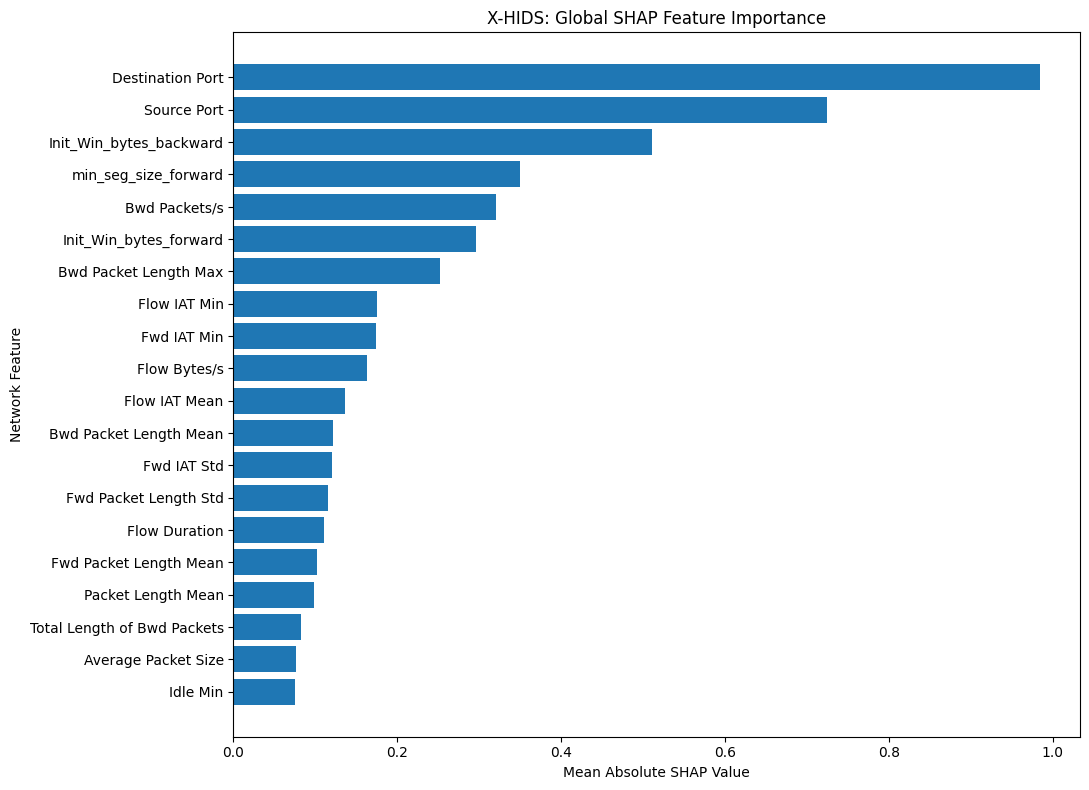


Selecting individual attack explanation...
Actual class: PortScan
Predicted class: PortScan
Prediction confidence: 0.999988

Generating individual SHAP explanation...

Generating individual explanation chart...


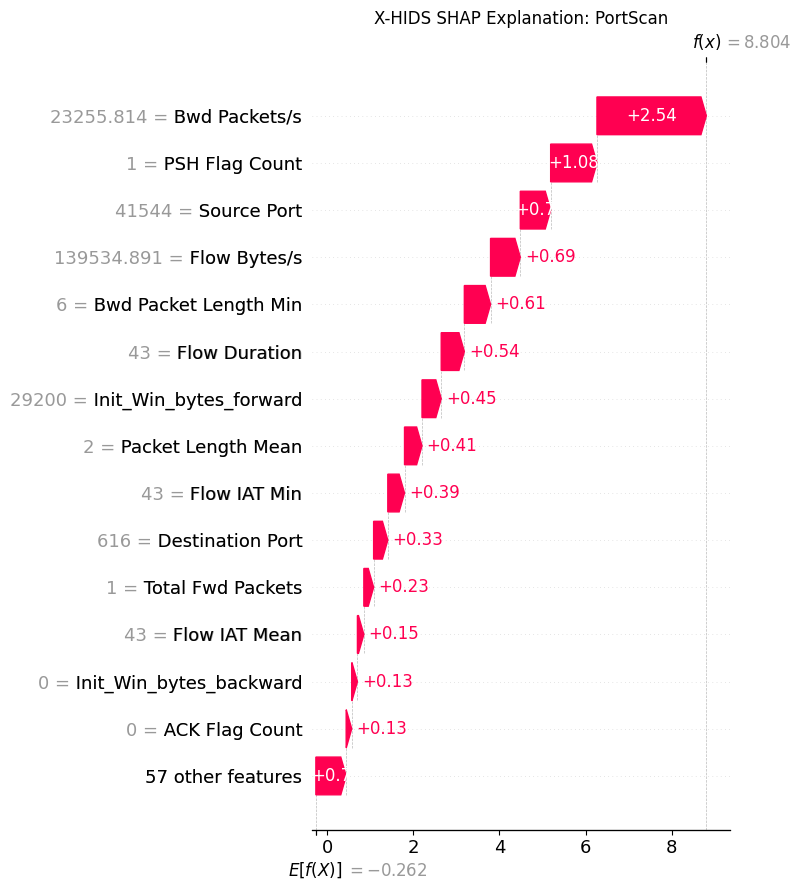


SHAP EXPLAINABILITY COMPLETED

Saved files:
1. shap_global_feature_importance.csv
2. shap_global_feature_importance.png
3. shap_individual_explanation.csv
4. shap_individual_explanation.png
5. shap_explanation_metadata.json

Individual explanation:
Actual: PortScan
Predicted: PortScan
Confidence: 100.0 %


In [ ]:

import os
import json
import shap
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = "/content/drive/MyDrive/X-HIDS"

print("=" * 65)
print("X-HIDS: SHAP EXPLAINABLE AI")
print("=" * 65)

# --------------------------------------------------
# 1. LOAD XGBOOST MODEL
# --------------------------------------------------

print("\nLoading XGBoost model...")

xgb_bundle = joblib.load(
    f"{BASE}/models/xgboost_baseline.joblib"
)

xgb_model = xgb_bundle["model"]
label_encoder = xgb_bundle["label_encoder"]
features = list(xgb_bundle["features"])

# --------------------------------------------------
# 2. LOAD VALIDATION SAMPLE
# --------------------------------------------------

print("Loading validation sample...")

validation_df = pd.read_parquet(
    f"{BASE}/experiments/model_samples/validation_sample.parquet"
)

X = validation_df[features].copy()
y = validation_df["Label_Clean"].astype(str).values

# Apply the same training-only imputation
medians = joblib.load(
    f"{BASE}/preprocessing/training_feature_medians.joblib"
)

X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(medians).astype(np.float64)

# --------------------------------------------------
# 3. SELECT A REPRESENTATIVE EXPLANATION SAMPLE
# --------------------------------------------------

print("\nSelecting SHAP sample...")

# Fixed seed for reproducibility
rng = np.random.default_rng(42)

sample_size = min(500, len(X))

sample_indices = rng.choice(
    len(X),
    size=sample_size,
    replace=False
)

X_shap = X.iloc[sample_indices].copy()

print("SHAP sample records:", len(X_shap))
print("Features:", len(features))

# --------------------------------------------------
# 4. CREATE SHAP EXPLAINER
# --------------------------------------------------

print("\nInitializing TreeExplainer...")

explainer = shap.TreeExplainer(xgb_model)

print("Calculating SHAP values...")
print("This may take a few minutes on CPU.")

shap_output = explainer(X_shap)

raw_values = shap_output.values

# Support different SHAP output formats
if isinstance(raw_values, list):
    shap_values = np.stack(raw_values, axis=-1)
else:
    shap_values = np.asarray(raw_values)

# Normalize dimensions to:
# samples x features x classes

if shap_values.ndim == 3:

    if shap_values.shape[0] == len(features):
        shap_values = np.transpose(
            shap_values, (1, 0, 2)
        )

    elif shap_values.shape[0] == len(label_encoder.classes_):
        shap_values = np.transpose(
            shap_values, (1, 2, 0)
        )

    if shap_values.shape[:2] != (
        len(X_shap), len(features)
    ):
        raise ValueError(
            f"Unexpected SHAP shape: {shap_values.shape}"
        )

elif shap_values.ndim == 2:

    if shap_values.shape != (len(X_shap), len(features)):
        raise ValueError(
            f"Unexpected SHAP shape: {shap_values.shape}"
        )

else:
    raise ValueError(
        f"Unsupported SHAP output dimensions: {shap_values.shape}"
    )

print("SHAP output shape:", shap_values.shape)

# --------------------------------------------------
# 5. GLOBAL FEATURE IMPORTANCE
# --------------------------------------------------

print("\nCalculating global feature importance...")

if shap_values.ndim == 3:
    global_importance = np.mean(
        np.abs(shap_values),
        axis=(0, 2)
    )
else:
    global_importance = np.mean(
        np.abs(shap_values),
        axis=0
    )

importance_df = pd.DataFrame({
    "Feature": features,
    "Mean_Absolute_SHAP": global_importance
})

importance_df = importance_df.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

importance_df.to_csv(
    f"{BASE}/results/shap_global_feature_importance.csv",
    index=False
)

print("\nTOP 20 IMPORTANT FEATURES")
print(importance_df.head(20).to_string(index=False))

# --------------------------------------------------
# 6. GLOBAL FEATURE IMPORTANCE CHART
# --------------------------------------------------

print("\nGenerating global SHAP chart...")

top_features = importance_df.head(20).sort_values(
    "Mean_Absolute_SHAP"
)

plt.figure(figsize=(11, 8))

plt.barh(
    top_features["Feature"],
    top_features["Mean_Absolute_SHAP"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Network Feature")
plt.title("X-HIDS: Global SHAP Feature Importance")
plt.tight_layout()

global_plot_path = (
    f"{BASE}/results/shap_global_feature_importance.png"
)

plt.savefig(global_plot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# --------------------------------------------------
# 7. SELECT AN INDIVIDUAL ATTACK FOR EXPLANATION
# --------------------------------------------------

print("\nSelecting individual attack explanation...")

predicted_probabilities = xgb_model.predict_proba(X_shap)

predicted_indices = np.argmax(
    predicted_probabilities,
    axis=1
)

predicted_labels = label_encoder.inverse_transform(
    predicted_indices
)

actual_sample_labels = y[sample_indices]

correct_attack_indices = np.where(
    (predicted_labels != "BENIGN") &
    (predicted_labels == actual_sample_labels)
)[0]

if len(correct_attack_indices) > 0:

    # Select the most confident correctly classified attack
    local_row = correct_attack_indices[
        np.argmax(
            np.max(
                predicted_probabilities[
                    correct_attack_indices
                ],
                axis=1
            )
        )
    ]

else:

    # Fallback: select the most confident predicted attack
    attack_indices = [
        i for i, label in enumerate(label_encoder.classes_)
        if label != "BENIGN"
    ]

    attack_probability = predicted_probabilities[
        :, attack_indices
    ].sum(axis=1)

    local_row = int(np.argmax(attack_probability))

actual_label = actual_sample_labels[local_row]
predicted_label = predicted_labels[local_row]

predicted_class_index = predicted_indices[local_row]

confidence = float(
    predicted_probabilities[
        local_row, predicted_class_index
    ]
)

print("Actual class:", actual_label)
print("Predicted class:", predicted_label)
print("Prediction confidence:", round(confidence, 6))

# --------------------------------------------------
# 8. GENERATE INDIVIDUAL SHAP EXPLANATION
# --------------------------------------------------

print("\nGenerating individual SHAP explanation...")

if shap_values.ndim == 3:

    local_values = shap_values[
        local_row, :, predicted_class_index
    ]

    base_values = np.asarray(
        shap_output.base_values
    )

    if base_values.ndim == 2:
        local_base_value = float(
            base_values[local_row, predicted_class_index]
        )
    elif base_values.ndim == 1:
        local_base_value = float(
            base_values[local_row]
        )
    else:
        local_base_value = float(base_values)

else:

    local_values = shap_values[local_row]

    base_values = np.asarray(
        shap_output.base_values
    )

    if base_values.ndim == 0:
        local_base_value = float(base_values)
    else:
        local_base_value = float(base_values[local_row])

local_explanation = shap.Explanation(
    values=local_values,
    base_values=local_base_value,
    data=X_shap.iloc[local_row].values,
    feature_names=features
)

# Save local explanation data
local_df = pd.DataFrame({
    "Feature": features,
    "Feature_Value": X_shap.iloc[local_row].values,
    "SHAP_Value": local_values
})

local_df["Absolute_SHAP"] = np.abs(
    local_df["SHAP_Value"]
)

local_df = local_df.sort_values(
    "Absolute_SHAP",
    ascending=False
)

local_df.to_csv(
    f"{BASE}/results/shap_individual_explanation.csv",
    index=False
)

# --------------------------------------------------
# 9. INDIVIDUAL WATERFALL CHART
# --------------------------------------------------

print("\nGenerating individual explanation chart...")

shap.plots.waterfall(
    local_explanation,
    max_display=15,
    show=False
)

plt.title(
    f"X-HIDS SHAP Explanation: {predicted_label}"
)

plt.tight_layout()

local_plot_path = (
    f"{BASE}/results/shap_individual_explanation.png"
)

plt.savefig(
    local_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# --------------------------------------------------
# 10. SAVE SHAP METADATA
# --------------------------------------------------

metadata = {
    "method": "SHAP TreeExplainer",
    "model": "XGBoost",
    "explanation_output": "Raw model output (margin)",
    "sample_records": int(len(X_shap)),
    "feature_count": int(len(features)),
    "actual_class": str(actual_label),
    "predicted_class": str(predicted_label),
    "prediction_confidence": confidence,
    "random_seed": 42,
    "global_importance_file": "shap_global_feature_importance.csv",
    "individual_explanation_file": "shap_individual_explanation.csv"
}

with open(
    f"{BASE}/results/shap_explanation_metadata.json",
    "w"
) as f:
    json.dump(metadata, f, indent=4)

print("\n" + "=" * 65)
print("SHAP EXPLAINABILITY COMPLETED")
print("=" * 65)

print("\nSaved files:")
print("1. shap_global_feature_importance.csv")
print("2. shap_global_feature_importance.png")
print("3. shap_individual_explanation.csv")
print("4. shap_individual_explanation.png")
print("5. shap_explanation_metadata.json")

print("\nIndividual explanation:")
print("Actual:", actual_label)
print("Predicted:", predicted_label)
print("Confidence:", round(confidence * 100, 2), "%")


In [ ]:

import os
import json
import time
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
from xgboost import XGBClassifier

BASE = "/content/drive/MyDrive/X-HIDS"
DEVICE = torch.device("cpu")

HELD_OUT_ATTACK = "DoS Hulk"
SEED = 42

print("=" * 70)
print("X-HIDS: UNSEEN ATTACK-CATEGORY EXPERIMENT")
print("=" * 70)

# --------------------------------------------------
# 1. LOAD TRAINING AND VALIDATION SAMPLES
# --------------------------------------------------

print("\nLoading samples...")

train_df = pd.read_parquet(
    f"{BASE}/experiments/model_samples/train_sample.parquet"
)

val_df = pd.read_parquet(
    f"{BASE}/experiments/model_samples/validation_sample.parquet"
)

xgb_bundle = joblib.load(
    f"{BASE}/models/xgboost_baseline.joblib"
)

features = list(xgb_bundle["features"])

medians = joblib.load(
    f"{BASE}/preprocessing/training_feature_medians.joblib"
)

scaler = joblib.load(
    f"{BASE}/preprocessing/standard_scaler.joblib"
)

print("Training sample:", train_df.shape)
print("Validation sample:", val_df.shape)

# --------------------------------------------------
# 2. HOLD OUT DOS HULK FROM SUPERVISED TRAINING
# --------------------------------------------------

print("\nRemoving held-out attack from supervised training...")

train_df["Label_Clean"] = train_df["Label_Clean"].astype(str)
val_df["Label_Clean"] = val_df["Label_Clean"].astype(str)

train_known = train_df[
    train_df["Label_Clean"] != HELD_OUT_ATTACK
].copy()

heldout_train_count = int(
    (train_df["Label_Clean"] == HELD_OUT_ATTACK).sum()
)

if heldout_train_count == 0:
    raise ValueError("Held-out attack is missing from training sample.")

if HELD_OUT_ATTACK in train_known["Label_Clean"].unique():
    raise ValueError("Data leakage: held-out attack remains in training.")

print("Held-out category:", HELD_OUT_ATTACK)
print("Excluded training records:", heldout_train_count)
print("Remaining supervised training records:", len(train_known))
print("Remaining supervised classes:",
      train_known["Label_Clean"].nunique())

# --------------------------------------------------
# 3. PREPARE SUPERVISED TRAINING DATA
# --------------------------------------------------

X_train = train_known[features].copy()
y_train = train_known["Label_Clean"].values

X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_train = X_train.fillna(medians).astype(np.float64)

# --------------------------------------------------
# 4. TRAIN RANDOM FOREST WITHOUT DOS HULK
# --------------------------------------------------

print("\n" + "=" * 65)
print("TRAINING HELD-OUT RANDOM FOREST")
print("=" * 65)

rf_unseen = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="sqrt",
    bootstrap=True,
    max_samples=0.8,
    class_weight="balanced_subsample",
    random_state=SEED,
    n_jobs=2
)

start = time.time()
rf_unseen.fit(X_train, y_train)
rf_training_time = time.time() - start

print("Random Forest training completed.")
print("Training time:", round(rf_training_time, 2), "seconds")

# --------------------------------------------------
# 5. TRAIN XGBOOST WITHOUT DOS HULK
# --------------------------------------------------

print("\n" + "=" * 65)
print("TRAINING HELD-OUT XGBOOST")
print("=" * 65)

heldout_encoder = LabelEncoder()
y_train_encoded = heldout_encoder.fit_transform(y_train)

sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train_encoded
)

xgb_unseen = XGBClassifier(
    n_estimators=150,
    max_depth=8,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=2,
    reg_lambda=1,
    objective="multi:softprob",
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=2,
    random_state=SEED
)

start = time.time()

xgb_unseen.fit(
    X_train,
    y_train_encoded,
    sample_weight=sample_weights
)

xgb_training_time = time.time() - start

print("XGBoost training completed.")
print("Training time:", round(xgb_training_time, 2), "seconds")

# Save separate unseen-experiment models
joblib.dump(
    rf_unseen,
    f"{BASE}/models/unseen_holdout_dos_hulk_rf.joblib"
)

joblib.dump(
    {
        "model": xgb_unseen,
        "label_encoder": heldout_encoder,
        "features": features,
        "held_out_attack": HELD_OUT_ATTACK
    },
    f"{BASE}/models/unseen_holdout_dos_hulk_xgb.joblib"
)

# --------------------------------------------------
# 6. LOAD EXISTING ANOMALY DETECTORS
# --------------------------------------------------

print("\nLoading BENIGN-trained anomaly detectors...")

if_bundle = joblib.load(
    f"{BASE}/models/isolation_forest_baseline.joblib"
)

if_model = if_bundle["model"]
if_threshold = float(if_bundle["threshold"])

ae_checkpoint = torch.load(
    f"{BASE}/models/autoencoder_baseline.pth",
    map_location=DEVICE,
    weights_only=False
)

class Autoencoder(nn.Module):
    def __init__(self, input_features=71):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_features, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 16)
        )

        self.decoder = nn.Sequential(
            nn.Linear(16, 32),
            nn.ReLU(),
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, input_features)
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))


ae_model = Autoencoder(len(features)).to(DEVICE)

ae_model.load_state_dict(
    ae_checkpoint["model_state_dict"]
)

ae_model.eval()

ae_threshold = float(ae_checkpoint["threshold"])

# --------------------------------------------------
# 7. CALIBRATE COMBINED ANOMALY THRESHOLD
# USING TRAINING BENIGN RECORDS ONLY
# --------------------------------------------------

print("\nPreparing independent BENIGN calibration records...")

benign_train = train_df[
    train_df["Label_Clean"] == "BENIGN"
].copy()

benign_fit, benign_calibration = train_test_split(
    benign_train,
    test_size=0.20,
    random_state=SEED
)

X_cal = benign_calibration[features].copy()

X_cal = X_cal.replace([np.inf, -np.inf], np.nan)
X_cal = X_cal.fillna(medians).astype(np.float64)

X_cal_scaled = scaler.transform(
    X_cal.to_numpy()
)

# Isolation Forest calibration scores
cal_if_scores = if_model.score_samples(X_cal_scaled)

cal_if_severity = np.clip(
    (if_threshold - cal_if_scores) / 0.15,
    0,
    1
)

# Autoencoder calibration errors
cal_tensor = torch.tensor(
    X_cal_scaled,
    dtype=torch.float32,
    device=DEVICE
)

cal_ae_errors = []

with torch.no_grad():
    for start in range(0, len(cal_tensor), 2048):
        batch = cal_tensor[start:start + 2048]

        reconstructed = ae_model(batch)

        error = torch.mean(
            (batch - reconstructed) ** 2,
            dim=1
        )

        cal_ae_errors.extend(error.cpu().numpy())

cal_ae_errors = np.asarray(cal_ae_errors)

cal_ae_severity = np.clip(
    (cal_ae_errors - ae_threshold) /
    (ae_threshold * 0.5),
    0,
    1
)

# Combined anomaly-only risk score
cal_anomaly_score = 100 * (
    0.50 * cal_if_severity +
    0.50 * cal_ae_severity
)

# Strictly greater-than threshold handles tied scores conservatively
anomaly_threshold = float(
    np.quantile(cal_anomaly_score, 0.99, method="higher")
)

calibration_fpr = float(
    np.mean(cal_anomaly_score > anomaly_threshold)
)

print("BENIGN calibration records:", len(X_cal))
print("Combined anomaly threshold:", round(anomaly_threshold, 6))
print("Calibration false-positive rate:",
      round(calibration_fpr * 100, 4), "%")

# --------------------------------------------------
# 8. PREPARE VALIDATION DATA
# --------------------------------------------------

print("\nPreparing validation data...")

X_val = val_df[features].copy()

X_val = X_val.replace([np.inf, -np.inf], np.nan)
X_val = X_val.fillna(medians).astype(np.float64)

y_val = val_df["Label_Clean"].values

held_mask = (y_val == HELD_OUT_ATTACK)
benign_mask = (y_val == "BENIGN")
known_mask = ~held_mask

if held_mask.sum() == 0:
    raise ValueError("No held-out attack records in validation sample.")

# --------------------------------------------------
# 9. SUPERVISED CLASSIFICATION ON KNOWN CATEGORIES
# --------------------------------------------------

print("\nEvaluating supervised models on known categories...")

X_known = X_val.loc[known_mask]
y_known = y_val[known_mask]

rf_known_predictions = rf_unseen.predict(X_known)

xgb_known_encoded = xgb_unseen.predict(X_known).astype(int)

xgb_known_predictions = heldout_encoder.inverse_transform(
    xgb_known_encoded
)

rf_known_accuracy = accuracy_score(
    y_known, rf_known_predictions
)

xgb_known_accuracy = accuracy_score(
    y_known, xgb_known_predictions
)

rf_known_f1 = f1_score(
    y_known, rf_known_predictions,
    average="macro",
    zero_division=0
)

xgb_known_f1 = f1_score(
    y_known, xgb_known_predictions,
    average="macro",
    zero_division=0
)

print("\nKNOWN-CATEGORY RESULTS")
print("Random Forest accuracy:", round(rf_known_accuracy, 6))
print("Random Forest macro F1:", round(rf_known_f1, 6))
print("XGBoost accuracy:", round(xgb_known_accuracy, 6))
print("XGBoost macro F1:", round(xgb_known_f1, 6))

# --------------------------------------------------
# 10. EVALUATE UNSEEN CATEGORY USING ANOMALY DETECTION
# --------------------------------------------------

print("\nScoring validation traffic with anomaly detectors...")

X_val_scaled = scaler.transform(
    X_val.to_numpy()
)

val_if_scores = if_model.score_samples(X_val_scaled)

val_if_severity = np.clip(
    (if_threshold - val_if_scores) / 0.15,
    0,
    1
)

val_if_flags = (
    val_if_scores < if_threshold
).astype(int)

val_tensor = torch.tensor(
    X_val_scaled,
    dtype=torch.float32,
    device=DEVICE
)

val_ae_errors = []

with torch.no_grad():
    for start in range(0, len(val_tensor), 2048):
        batch = val_tensor[start:start + 2048]

        reconstructed = ae_model(batch)

        error = torch.mean(
            (batch - reconstructed) ** 2,
            dim=1
        )

        val_ae_errors.extend(error.cpu().numpy())

val_ae_errors = np.asarray(val_ae_errors)

val_ae_severity = np.clip(
    (val_ae_errors - ae_threshold) /
    (ae_threshold * 0.5),
    0,
    1
)

val_ae_flags = (
    val_ae_errors > ae_threshold
).astype(int)

# Combined anomaly-only score
combined_anomaly_score = 100 * (
    0.50 * val_if_severity +
    0.50 * val_ae_severity
)

combined_anomaly_flags = (
    combined_anomaly_score > anomaly_threshold
).astype(int)

# --------------------------------------------------
# 11. UNSEEN ATTACK EVALUATION
# --------------------------------------------------

held_if_detection = float(
    val_if_flags[held_mask].mean()
)

held_ae_detection = float(
    val_ae_flags[held_mask].mean()
)

held_combined_detection = float(
    combined_anomaly_flags[held_mask].mean()
)

benign_if_fpr = float(
    val_if_flags[benign_mask].mean()
)

benign_ae_fpr = float(
    val_ae_flags[benign_mask].mean()
)

benign_combined_fpr = float(
    combined_anomaly_flags[benign_mask].mean()
)

print("\n" + "=" * 70)
print("UNSEEN ATTACK-CATEGORY RESULTS")
print("=" * 70)

print("Held-out category:", HELD_OUT_ATTACK)
print("Held-out validation records:", int(held_mask.sum()))

print("\nDETECTION RATE ON UNSEEN ATTACK")
print("Isolation Forest:",
      round(held_if_detection * 100, 2), "%")

print("Autoencoder:",
      round(held_ae_detection * 100, 2), "%")

print("Combined anomaly detector:",
      round(held_combined_detection * 100, 2), "%")

print("\nFALSE-POSITIVE RATE ON BENIGN VALIDATION RECORDS")
print("Isolation Forest:",
      round(benign_if_fpr * 100, 2), "%")

print("Autoencoder:",
      round(benign_ae_fpr * 100, 2), "%")

print("Combined anomaly detector:",
      round(benign_combined_fpr * 100, 2), "%")

# --------------------------------------------------
# 12. INSPECT WHAT SUPERVISED MODELS PREDICT
# FOR THE UNSEEN CATEGORY
# --------------------------------------------------

X_held = X_val.loc[held_mask]

rf_held_predictions = rf_unseen.predict(X_held)

xgb_held_predictions = heldout_encoder.inverse_transform(
    xgb_unseen.predict(X_held).astype(int)
)

print("\nSUPERVISED PREDICTIONS FOR UNSEEN ATTACK")
print("\nRandom Forest:")
print(
    pd.Series(rf_held_predictions)
    .value_counts()
    .to_string()
)

print("\nXGBoost:")
print(
    pd.Series(xgb_held_predictions)
    .value_counts()
    .to_string()
)

# --------------------------------------------------
# 13. SAVE EXPERIMENT RESULTS
# --------------------------------------------------

experiment_results = pd.DataFrame({
    "Actual_Label": y_val,
    "Held_Out_Attack": held_mask.astype(int),
    "RF_Prediction": rf_unseen.predict(X_val),
    "XGB_Prediction": heldout_encoder.inverse_transform(
        xgb_unseen.predict(X_val).astype(int)
    ),
    "IsolationForest_Score": val_if_scores,
    "IsolationForest_Anomaly": val_if_flags,
    "Autoencoder_Error": val_ae_errors,
    "Autoencoder_Anomaly": val_ae_flags,
    "Combined_Anomaly_Score": combined_anomaly_score,
    "Combined_Anomaly_Detection": combined_anomaly_flags
})

experiment_results.to_csv(
    f"{BASE}/results/unseen_dos_hulk_predictions.csv",
    index=False
)

experiment_metrics = {
    "experiment": "Unseen Attack Category Detection",
    "held_out_attack": HELD_OUT_ATTACK,
    "training_excluded_records": heldout_train_count,
    "validation_heldout_records": int(held_mask.sum()),
    "benign_validation_records": int(benign_mask.sum()),
    "supervised_training_classes": int(len(heldout_encoder.classes_)),
    "random_forest_known_accuracy": float(rf_known_accuracy),
    "random_forest_known_macro_f1": float(rf_known_f1),
    "xgboost_known_accuracy": float(xgb_known_accuracy),
    "xgboost_known_macro_f1": float(xgb_known_f1),
    "isolation_forest_unseen_detection_rate": held_if_detection,
    "autoencoder_unseen_detection_rate": held_ae_detection,
    "combined_unseen_detection_rate": held_combined_detection,
    "isolation_forest_benign_fpr": benign_if_fpr,
    "autoencoder_benign_fpr": benign_ae_fpr,
    "combined_benign_fpr": benign_combined_fpr,
    "combined_anomaly_threshold": anomaly_threshold,
    "calibration_benign_records": int(len(X_cal)),
    "calibration_false_positive_rate": calibration_fpr,
    "random_forest_training_seconds": float(rf_training_time),
    "xgboost_training_seconds": float(xgb_training_time),
    "validation_protocol": "DoS Hulk excluded from supervised training; anomaly models trained on BENIGN only",
    "caveat": "Validation sample is enriched and results require final untouched test-set confirmation."
}

with open(
    f"{BASE}/results/unseen_dos_hulk_metrics.json",
    "w"
) as f:
    json.dump(experiment_metrics, f, indent=4)

# Save anomaly-only configuration
unseen_config = {
    "held_out_attack": HELD_OUT_ATTACK,
    "anomaly_weights": {
        "isolation_forest": 0.50,
        "autoencoder": 0.50
    },
    "combined_anomaly_threshold": anomaly_threshold,
    "threshold_method": "99th percentile of BENIGN training calibration scores",
    "calibration_false_positive_rate": calibration_fpr,
    "supervised_models_excluded_heldout_class": True
}

with open(
    f"{BASE}/models/unseen_attack_config.json",
    "w"
) as f:
    json.dump(unseen_config, f, indent=4)

print("\nSAVED FILES")
print("1. unseen_dos_hulk_predictions.csv")
print("2. unseen_dos_hulk_metrics.json")
print("3. unseen_attack_config.json")
print("4. unseen_holdout_dos_hulk_rf.joblib")
print("5. unseen_holdout_dos_hulk_xgb.joblib")

print("\n" + "=" * 70)
print("UNSEEN ATTACK EXPERIMENT COMPLETED")
print("=" * 70)


X-HIDS: UNSEEN ATTACK-CATEGORY EXPERIMENT

Loading samples...
Training sample: (117504, 73)
Validation sample: (28130, 73)

Removing held-out attack from supervised training...
Held-out category: DoS Hulk
Excluded training records: 20000
Remaining supervised training records: 97504
Remaining supervised classes: 14

TRAINING HELD-OUT RANDOM FOREST
Random Forest training completed.
Training time: 36.7 seconds

TRAINING HELD-OUT XGBOOST
XGBoost training completed.
Training time: 70.79 seconds

Loading BENIGN-trained anomaly detectors...

Preparing independent BENIGN calibration records...
BENIGN calibration records: 10000
Combined anomaly threshold: 19.960847
Calibration false-positive rate: 0.99 %

Preparing validation data...

Evaluating supervised models on known categories...

KNOWN-CATEGORY RESULTS
Random Forest accuracy: 0.99572
Random Forest macro F1: 0.920349
XGBoost accuracy: 0.996714
XGBoost macro F1: 0.974127

Scoring validation traffic with anomaly detectors...

UNSEEN ATTACK-

In [ ]:

# ============================================================
# X-HIDS PHASE 6.9.1
# CREATE INDEPENDENT STRATIFIED TEST SAMPLE
# ============================================================

import os
import json
import duckdb
import pandas as pd

BASE = "/content/drive/MyDrive/X-HIDS"

TEST_DIR = f"{BASE}/dataset/splits/test"
OUTPUT_DIR = f"{BASE}/experiments/model_samples"

os.makedirs(OUTPUT_DIR, exist_ok=True)

OUTPUT_FILE = f"{OUTPUT_DIR}/test_sample.parquet"
SUMMARY_FILE = f"{OUTPUT_DIR}/test_sample_summary.json"

print("=" * 65)
print("X-HIDS: INDEPENDENT TEST SAMPLE CREATION")
print("=" * 65)

# Sample quotas per class
# Rare classes will contribute all available records.
query = f"""
COPY (
    SELECT *
    FROM read_parquet('{TEST_DIR}/**/*.parquet', union_by_name=true)
    QUALIFY ROW_NUMBER() OVER (
        PARTITION BY Label_Clean
        ORDER BY hash(_row_id), _row_id
    ) <= CASE
        WHEN Label_Clean = 'BENIGN' THEN 10000
        WHEN Label_Clean IN (
            'DoS Hulk',
            'DDoS',
            'PortScan'
        ) THEN 5000
        ELSE 500
    END
) TO '{OUTPUT_FILE}'
(FORMAT PARQUET, COMPRESSION ZSTD);
"""

print("\nReading untouched test split...")
con = duckdb.connect()
con.execute(query)

print("Test sample created successfully.")

# Read sample summary
df = con.execute(f"""
    SELECT Label_Clean, COUNT(*) AS Records
    FROM read_parquet('{OUTPUT_FILE}')
    GROUP BY Label_Clean
    ORDER BY Records DESC
""").df()

total = int(df["Records"].sum())

summary = {
    "experiment": "X-HIDS Independent Test Sample",
    "source": "Original stratified test split",
    "sampling_method": "Deterministic per-class sampling",
    "randomization_method": "DuckDB hash of row ID",
    "total_records": total,
    "class_count": len(df),
    "class_distribution": {
        str(row["Label_Clean"]): int(row["Records"])
        for _, row in df.iterrows()
    },
    "output_file": OUTPUT_FILE
}

with open(SUMMARY_FILE, "w") as f:
    json.dump(summary, f, indent=4)

print("\n" + "=" * 65)
print("TEST SAMPLE SUMMARY")
print("=" * 65)

print(df.to_string(index=False))
print("\nTotal test sample records:", total)
print("Number of classes:", len(df))

print("\nSaved files:")
print("1.", OUTPUT_FILE)
print("2.", SUMMARY_FILE)

print("\nPHASE 6.9.1 COMPLETED")


X-HIDS: INDEPENDENT TEST SAMPLE CREATION

Reading untouched test split...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Test sample created successfully.

TEST SAMPLE SUMMARY
               Label_Clean  Records
                    BENIGN    10000
                      DDoS     5000
                  DoS Hulk     5000
                  PortScan     5000
               FTP-Patator      500
             DoS slowloris      500
               SSH-Patator      500
             DoS GoldenEye      500
          DoS Slowhttptest      500
                       Bot      295
  Web Attack - Brute Force      226
          Web Attack - XSS       98
              Infiltration        5
Web Attack - Sql Injection        3
                Heartbleed        1

Total test sample records: 28128
Number of classes: 15

Saved files:
1. /content/drive/MyDrive/X-HIDS/experiments/model_samples/test_sample.parquet
2. /content/drive/MyDrive/X-HIDS/experiments/model_samples/test_sample_summary.json

PHASE 6.9.1 COMPLETED


In [ ]:

# ============================================================
# X-HIDS PHASE 6.9.2
# INDEPENDENT TEST EVALUATION OF ALL MODELS
# ============================================================

import os
import json
import time
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

BASE = "/content/drive/MyDrive/X-HIDS"
DEVICE = torch.device("cpu")

RESULTS = f"{BASE}/results"
MODELS = f"{BASE}/models"

os.makedirs(RESULTS, exist_ok=True)

print("=" * 70)
print("X-HIDS: INDEPENDENT TEST EVALUATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. LOAD INDEPENDENT TEST SAMPLE
# ------------------------------------------------------------

test_path = (
    f"{BASE}/experiments/model_samples/test_sample.parquet"
)

df = pd.read_parquet(test_path)

print("\nTest sample loaded:", df.shape)

# ------------------------------------------------------------
# 2. LOAD SAVED MODELS AND PREPROCESSING OBJECTS
# ------------------------------------------------------------

print("\nLoading trained models...")

rf = joblib.load(f"{MODELS}/random_forest_baseline.joblib")

xgb_bundle = joblib.load(f"{MODELS}/xgboost_baseline.joblib")
xgb = xgb_bundle["model"]
label_encoder = xgb_bundle["label_encoder"]
features = xgb_bundle["features"]

if_bundle = joblib.load(
    f"{MODELS}/isolation_forest_baseline.joblib"
)

isolation_forest = if_bundle["model"]
if_threshold = float(if_bundle["threshold"])

medians = joblib.load(
    f"{BASE}/preprocessing/training_feature_medians.joblib"
)

scaler = joblib.load(
    f"{BASE}/preprocessing/standard_scaler.joblib"
)

print("Random Forest loaded.")
print("XGBoost loaded.")
print("Isolation Forest loaded.")
print("Training medians loaded.")
print("StandardScaler loaded.")

# ------------------------------------------------------------
# 3. PREPROCESS TEST FEATURES
# ------------------------------------------------------------

print("\nPreparing test features...")

X = df[features].copy()

X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(medians)

X = X.astype(np.float32)

X_scaled = scaler.transform(X).astype(np.float32)

y_true = df["Label_Clean"].astype(str).values
y_binary = (y_true != "BENIGN").astype(int)

print("Feature matrix:", X.shape)
print("Scaled matrix:", X_scaled.shape)
print("Missing values:", int(X.isna().sum().sum()))
print("Infinite values:", int(np.isinf(X.values).sum()))

# ------------------------------------------------------------
# 4. RANDOM FOREST EVALUATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RANDOM FOREST TEST EVALUATION")
print("=" * 70)

start = time.time()
rf_pred = rf.predict(X)
rf_probability = rf.predict_proba(X)
rf_time = time.time() - start

rf_attack_probability = 1 - rf.predict_proba(X)[:, list(rf.classes_).index("BENIGN")]

rf_accuracy = accuracy_score(y_true, rf_pred)
rf_precision = precision_score(
    y_true, rf_pred, average="macro", zero_division=0
)
rf_recall = recall_score(
    y_true, rf_pred, average="macro", zero_division=0
)
rf_f1 = f1_score(
    y_true, rf_pred, average="macro", zero_division=0
)

print("Accuracy:", round(rf_accuracy, 6))
print("Macro Precision:", round(rf_precision, 6))
print("Macro Recall:", round(rf_recall, 6))
print("Macro F1:", round(rf_f1, 6))
print("Inference time:", round(rf_time, 4), "seconds")

# ------------------------------------------------------------
# 5. XGBOOST EVALUATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("XGBOOST TEST EVALUATION")
print("=" * 70)

start = time.time()
xgb_encoded = xgb.predict(X)
xgb_probabilities = xgb.predict_proba(X)
xgb_time = time.time() - start

xgb_pred = label_encoder.inverse_transform(
    np.asarray(xgb_encoded, dtype=int)
)

xgb_benign_index = list(label_encoder.classes_).index("BENIGN")
xgb_attack_probability = 1 - xgb_probabilities[:, xgb_benign_index]

xgb_accuracy = accuracy_score(y_true, xgb_pred)
xgb_precision = precision_score(
    y_true, xgb_pred, average="macro", zero_division=0
)
xgb_recall = recall_score(
    y_true, xgb_pred, average="macro", zero_division=0
)
xgb_f1 = f1_score(
    y_true, xgb_pred, average="macro", zero_division=0
)

print("Accuracy:", round(xgb_accuracy, 6))
print("Macro Precision:", round(xgb_precision, 6))
print("Macro Recall:", round(xgb_recall, 6))
print("Macro F1:", round(xgb_f1, 6))
print("Inference time:", round(xgb_time, 4), "seconds")

# ------------------------------------------------------------
# 6. LOAD AND EVALUATE AUTOENCODER
# ------------------------------------------------------------

print("\nLoading Autoencoder...")

class Autoencoder(nn.Module):
    def __init__(self, input_dim=71):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 16)
        )

        self.decoder = nn.Sequential(
            nn.Linear(16, 32),
            nn.ReLU(),
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, input_dim)
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))


ae_checkpoint = torch.load(
    f"{MODELS}/autoencoder_baseline.pth",
    map_location=DEVICE,
    weights_only=False
)

autoencoder = Autoencoder(input_dim=len(features))
autoencoder.load_state_dict(ae_checkpoint["model_state_dict"])
autoencoder.to(DEVICE)
autoencoder.eval()

ae_threshold = float(ae_checkpoint["threshold"])

print("Autoencoder loaded.")
print("Autoencoder threshold:", ae_threshold)

# Reconstruction error in batches
print("\nCalculating Autoencoder reconstruction errors...")

start = time.time()

ae_errors = []

with torch.no_grad():
    for i in range(0, len(X_scaled), 4096):
        batch = torch.tensor(
            X_scaled[i:i+4096],
            dtype=torch.float32,
            device=DEVICE
        )

        reconstructed = autoencoder(batch)

        errors = torch.mean(
            (batch - reconstructed) ** 2,
            dim=1
        )

        ae_errors.extend(errors.cpu().numpy())

ae_errors = np.asarray(ae_errors)
ae_time = time.time() - start

ae_pred = (ae_errors > ae_threshold).astype(int)

# ------------------------------------------------------------
# 7. ISOLATION FOREST EVALUATION
# ------------------------------------------------------------

print("\nCalculating Isolation Forest anomaly scores...")

start = time.time()

if_scores = isolation_forest.decision_function(X_scaled)

if_time = time.time() - start

if_pred = (if_scores < if_threshold).astype(int)

# ------------------------------------------------------------
# 8. COMBINED ANOMALY DETECTOR
# ------------------------------------------------------------

if_severity = np.clip(
    (if_threshold - if_scores) / 0.15,
    0,
    1
)

ae_severity = np.clip(
    (ae_errors - ae_threshold) / (ae_threshold * 0.5),
    0,
    1
)

combined_anomaly_score = (
    100 * (0.5 * if_severity + 0.5 * ae_severity)
)

# Use the independent calibration threshold from Phase 6.8.
with open(
    f"{RESULTS}/unseen_dos_hulk_metrics.json", "r"
) as f:
    unseen_metrics = json.load(f)

combined_threshold = float(
    unseen_metrics["combined_anomaly_threshold"]
)

combined_anomaly_pred = (
    combined_anomaly_score > combined_threshold
).astype(int)

print("\nAnomaly threshold:", combined_threshold)

# ------------------------------------------------------------
# 9. ORIGINAL HYBRID DETECTOR
# ------------------------------------------------------------

hybrid_risk_score = (
    0.35 * xgb_attack_probability * 100
    + 0.15 * rf_attack_probability * 100
    + 0.25 * if_severity * 100
    + 0.25 * ae_severity * 100
)

hybrid_threshold = 40.0
hybrid_pred = (hybrid_risk_score >= hybrid_threshold).astype(int)

# ------------------------------------------------------------
# 10. BINARY METRIC FUNCTION
# ------------------------------------------------------------

def binary_metrics(actual, predicted):
    cm = confusion_matrix(actual, predicted, labels=[0, 1])

    tn, fp, fn, tp = cm.ravel()

    return {
        "accuracy": float(accuracy_score(actual, predicted)),
        "precision": float(precision_score(
            actual, predicted, zero_division=0
        )),
        "recall": float(recall_score(
            actual, predicted, zero_division=0
        )),
        "f1": float(f1_score(
            actual, predicted, zero_division=0
        )),
        "false_positive_rate": float(
            fp / (fp + tn) if (fp + tn) else 0
        ),
        "detection_rate": float(
            tp / (tp + fn) if (tp + fn) else 0
        ),
        "confusion_matrix": cm.tolist(),
        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp)
    }


# ------------------------------------------------------------
# 11. PRINT ANOMALY AND HYBRID RESULTS
# ------------------------------------------------------------

detectors = {
    "Isolation Forest": (if_pred, if_time),
    "Autoencoder": (ae_pred, ae_time),
    "Combined Anomaly Detector": (
        combined_anomaly_pred, None
    ),
    "Hybrid Detector": (hybrid_pred, None)
}

binary_results = {}

print("\n" + "=" * 70)
print("BINARY ATTACK DETECTION RESULTS")
print("=" * 70)

for name, (prediction, inference_time) in detectors.items():

    metrics = binary_metrics(y_binary, prediction)
    binary_results[name] = metrics

    print("\n", name)
    print("Accuracy:", round(metrics["accuracy"], 6))
    print("Precision:", round(metrics["precision"], 6))
    print("Recall / Detection Rate:", round(metrics["recall"], 6))
    print("F1:", round(metrics["f1"], 6))
    print(
        "False-positive rate:",
        round(metrics["false_positive_rate"], 6)
    )

    if inference_time is not None:
        print("Inference time:", round(inference_time, 4), "seconds")

# ------------------------------------------------------------
# 12. MULTICLASS CLASSIFICATION REPORTS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MULTICLASS CLASSIFICATION REPORTS")
print("=" * 70)

rf_report = classification_report(
    y_true, rf_pred, output_dict=True, zero_division=0
)

xgb_report = classification_report(
    y_true, xgb_pred, output_dict=True, zero_division=0
)

pd.DataFrame(rf_report).transpose().to_csv(
    f"{RESULTS}/independent_test_rf_classification_report.csv"
)

pd.DataFrame(xgb_report).transpose().to_csv(
    f"{RESULTS}/independent_test_xgb_classification_report.csv"
)

# ------------------------------------------------------------
# 13. SAVE PREDICTIONS AND CONFUSION MATRICES
# ------------------------------------------------------------

prediction_df = pd.DataFrame({
    "Actual_Label": y_true,
    "Actual_Binary": y_binary,
    "RF_Prediction": rf_pred,
    "XGB_Prediction": xgb_pred,
    "Isolation_Forest_Anomaly": if_pred,
    "Autoencoder_Anomaly": ae_pred,
    "Combined_Anomaly": combined_anomaly_pred,
    "IF_Score": if_scores,
    "AE_Reconstruction_Error": ae_errors,
    "Combined_Anomaly_Score": combined_anomaly_score,
    "Hybrid_Risk_Score": hybrid_risk_score,
    "Hybrid_Prediction": hybrid_pred
})

prediction_df.to_csv(
    f"{RESULTS}/independent_test_predictions.csv",
    index=False
)

pd.DataFrame(
    confusion_matrix(y_true, rf_pred)
).to_csv(
    f"{RESULTS}/independent_test_rf_confusion_matrix.csv",
    index=False
)

pd.DataFrame(
    confusion_matrix(y_true, xgb_pred)
).to_csv(
    f"{RESULTS}/independent_test_xgb_confusion_matrix.csv",
    index=False
)

# ------------------------------------------------------------
# 14. SAVE FINAL METRICS
# ------------------------------------------------------------

final_metrics = {
    "experiment": "X-HIDS Independent Test Evaluation",
    "test_records": int(len(df)),
    "number_of_classes": int(len(np.unique(y_true))),
    "test_sample_type": "Stratified class-enriched sample",
    "random_state": 42,
    "supervised_models": {
        "Random Forest": {
            "accuracy": float(rf_accuracy),
            "macro_precision": float(rf_precision),
            "macro_recall": float(rf_recall),
            "macro_f1": float(rf_f1),
            "inference_seconds": float(rf_time)
        },
        "XGBoost": {
            "accuracy": float(xgb_accuracy),
            "macro_precision": float(xgb_precision),
            "macro_recall": float(xgb_recall),
            "macro_f1": float(xgb_f1),
            "inference_seconds": float(xgb_time)
        }
    },
    "binary_detectors": binary_results,
    "thresholds": {
        "isolation_forest": if_threshold,
        "autoencoder": ae_threshold,
        "combined_anomaly": combined_threshold,
        "hybrid": hybrid_threshold
    }
}

metrics_path = f"{RESULTS}/independent_test_metrics.json"

with open(metrics_path, "w") as f:
    json.dump(final_metrics, f, indent=4)

print("\n" + "=" * 70)
print("INDEPENDENT TEST EVALUATION COMPLETED")
print("=" * 70)

print("\nSaved results:")
print("1. independent_test_metrics.json")
print("2. independent_test_predictions.csv")
print("3. independent_test_rf_classification_report.csv")
print("4. independent_test_xgb_classification_report.csv")
print("5. independent_test_rf_confusion_matrix.csv")
print("6. independent_test_xgb_confusion_matrix.csv")

print("\nIMPORTANT: These are independent test-sample results.")
print("The sample is stratified and class-enriched.")


X-HIDS: INDEPENDENT TEST EVALUATION

Test sample loaded: (28128, 73)

Loading trained models...
Random Forest loaded.
XGBoost loaded.
Isolation Forest loaded.
Training medians loaded.
StandardScaler loaded.

Preparing test features...
Feature matrix: (28128, 71)
Scaled matrix: (28128, 71)
Missing values: 78


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.


Infinite values: 0

RANDOM FOREST TEST EVALUATION


[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.4s
[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:    0.8s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.3s
[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:    0.7s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.4s
[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:    0.7s finished


Accuracy: 0.996871
Macro Precision: 0.975514
Macro Recall: 0.953676
Macro F1: 0.962366
Inference time: 1.5042 seconds

XGBOOST TEST EVALUATION
Accuracy: 0.997618
Macro Precision: 0.964212
Macro Recall: 0.977534
Macro F1: 0.970347
Inference time: 4.1608 seconds

Loading Autoencoder...
Autoencoder loaded.
Autoencoder threshold: 0.7852279865741749

Calculating Autoencoder reconstruction errors...

Calculating Isolation Forest anomaly scores...

Anomaly threshold: 19.96084749698639

BINARY ATTACK DETECTION RESULTS

 Isolation Forest
Accuracy: 0.355518
Precision: 0.0
Recall / Detection Rate: 0.0
F1: 0.0
False-positive rate: 0.0
Inference time: 0.4787 seconds

 Autoencoder
Accuracy: 0.523002
Precision: 0.98042
Recall / Detection Rate: 0.26517
F1: 0.417437
False-positive rate: 0.0096
Inference time: 0.1749 seconds

 Combined Anomaly Detector
Accuracy: 0.509812
Precision: 0.987421
Recall / Detection Rate: 0.242498
F1: 0.389371
False-positive rate: 0.0056

 Hybrid Detector
Accuracy: 0.998222
Pr

In [ ]:

# ============================================================
# X-HIDS PHASE 6.9.2
# VERIFY INDEPENDENT TEST RESULTS
# ============================================================

import os
import json
import pandas as pd

BASE = "/content/drive/MyDrive/X-HIDS"
RESULTS = f"{BASE}/results"

print("=" * 65)
print("X-HIDS: INDEPENDENT TEST RESULT VERIFICATION")
print("=" * 65)

# 1. Inspect complete metrics JSON
metrics_file = f"{RESULTS}/independent_test_metrics.json"

with open(metrics_file, "r") as f:
    metrics = json.load(f)

print("\nCOMPLETE SAVED METRICS")
print(json.dumps(metrics, indent=4))

# 2. Inspect Random Forest confusion matrix
rf_file = f"{RESULTS}/independent_test_rf_confusion_matrix.csv"

print("\n" + "=" * 65)
print("RANDOM FOREST CONFUSION MATRIX")
print("=" * 65)

if os.path.exists(rf_file):
    print(pd.read_csv(rf_file).to_string(index=False))

# 3. Inspect XGBoost confusion matrix
xgb_file = f"{RESULTS}/independent_test_xgb_confusion_matrix.csv"

print("\n" + "=" * 65)
print("XGBOOST CONFUSION MATRIX")
print("=" * 65)

if os.path.exists(xgb_file):
    print(pd.read_csv(xgb_file).to_string(index=False))

# 4. Check saved prediction file
pred_file = f"{RESULTS}/independent_test_predictions.csv"

print("\n" + "=" * 65)
print("PREDICTION FILE INSPECTION")
print("=" * 65)

if os.path.exists(pred_file):
    pred = pd.read_csv(pred_file)
    print("Prediction file shape:", pred.shape)
    print("Columns:", pred.columns.tolist())
    print("\nFirst 5 rows:")
    print(pred.head().to_string(index=False))

print("\nRESULT VERIFICATION COMPLETED")


X-HIDS: INDEPENDENT TEST RESULT VERIFICATION

COMPLETE SAVED METRICS
{
    "experiment": "X-HIDS Independent Test Evaluation",
    "test_records": 28128,
    "number_of_classes": 15,
    "test_sample_type": "Stratified class-enriched sample",
    "random_state": 42,
    "supervised_models": {
        "Random Forest": {
            "accuracy": 0.9968714448236633,
            "macro_precision": 0.9755137435097867,
            "macro_recall": 0.9536758550575872,
            "macro_f1": 0.9623659188808831,
            "inference_seconds": 1.504157304763794
        },
        "XGBoost": {
            "accuracy": 0.99761803185438,
            "macro_precision": 0.9642123309368393,
            "macro_recall": 0.9775343675877431,
            "macro_f1": 0.9703467817090812,
            "inference_seconds": 4.160755157470703
        }
    },
    "binary_detectors": {
        "Isolation Forest": {
            "accuracy": 0.35551763367463024,
            "precision": 0.0,
            "recall": 0.0

In [ ]:

# ============================================================
# X-HIDS: ISOLATION FOREST THRESHOLD DIAGNOSTIC
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd

BASE = "/content/drive/MyDrive/X-HIDS"
RESULTS = f"{BASE}/results"
MODELS = f"{BASE}/models"

pred = pd.read_csv(
    f"{RESULTS}/independent_test_predictions.csv"
)

bundle = joblib.load(
    f"{MODELS}/isolation_forest_baseline.joblib"
)

print("=" * 65)
print("ISOLATION FOREST DIAGNOSTIC")
print("=" * 65)

print("\nModel bundle keys:")
print(list(bundle.keys()))

threshold = bundle["threshold"]
print("\nSaved Isolation Forest threshold:", threshold)

scores = pred["IF_Score"].astype(float)

print("\nIF SCORE DISTRIBUTION")
print(scores.describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
))

print("\nThreshold comparison:")
print("Scores below threshold:", int((scores < threshold).sum()))
print("Scores equal to threshold:", int((scores == threshold).sum()))
print("Scores above threshold:", int((scores > threshold).sum()))

print("\nSaved anomaly flag counts:")
print(pred["Isolation_Forest_Anomaly"].value_counts(dropna=False))

print("\nReconstructed anomaly flags using score < threshold:")
reconstructed = (scores < threshold).astype(int)
print(reconstructed.value_counts())

print("\nAnomaly flags by actual class:")
check = pred.groupby("Actual_Binary").agg(
    Records=("IF_Score", "size"),
    Minimum_Score=("IF_Score", "min"),
    Maximum_Score=("IF_Score", "max"),
    Anomalies=("Isolation_Forest_Anomaly", "sum")
)
print(check)

print("\nAUTOENCODER AND COMBINED SCORE CHECK")
print("AE anomalies:", int(pred["Autoencoder_Anomaly"].sum()))
print("Combined anomalies:", int(pred["Combined_Anomaly"].sum()))

print("\nDIAGNOSTIC COMPLETED")


ISOLATION FOREST DIAGNOSTIC

Model bundle keys:
['model', 'threshold', 'features', 'threshold_method', 'scaler_path']

Saved Isolation Forest threshold: -0.6282147243193423

IF SCORE DISTRIBUTION
count    28128.000000
mean         0.072955
std          0.105153
min         -0.225690
1%          -0.153813
5%          -0.132247
25%         -0.011863
50%          0.129615
75%          0.151554
95%          0.170615
99%          0.175337
max          0.177461
Name: IF_Score, dtype: float64

Threshold comparison:
Scores below threshold: 0
Scores equal to threshold: 0
Scores above threshold: 28128

Saved anomaly flag counts:
Isolation_Forest_Anomaly
0    28128
Name: count, dtype: int64

Reconstructed anomaly flags using score < threshold:
IF_Score
0    28128
Name: count, dtype: int64

Anomaly flags by actual class:
               Records  Minimum_Score  Maximum_Score  Anomalies
Actual_Binary                                                  
0                10000      -0.225690       0.17746

In [ ]:

# ============================================================
# X-HIDS: ISOLATION FOREST CALIBRATION VERIFICATION
# ============================================================

import os
import joblib
import numpy as np
import pandas as pd

BASE = "/content/drive/MyDrive/X-HIDS"

bundle = joblib.load(
    f"{BASE}/models/isolation_forest_baseline.joblib"
)

model = bundle["model"]

train = pd.read_parquet(
    f"{BASE}/experiments/model_samples/train_sample.parquet"
)

benign = train[
    train["Label_Clean"] == "BENIGN"
].copy()

# Reproduce original 80/20 BENIGN calibration split
from sklearn.model_selection import train_test_split

fit_data, calibration_data = train_test_split(
    benign,
    test_size=0.20,
    random_state=42
)

features = bundle["features"]

X_cal = calibration_data[features].copy()

# Use the saved training medians
medians = joblib.load(
    f"{BASE}/preprocessing/training_feature_medians.joblib"
)

X_cal = X_cal.replace([np.inf, -np.inf], np.nan)
X_cal = X_cal.fillna(medians)

scaler = joblib.load(
    f"{BASE}/preprocessing/standard_scaler.joblib"
)

X_cal_scaled = scaler.transform(X_cal)

# Calculate both score conventions
raw_scores = model.score_samples(X_cal_scaled)
decision_scores = model.decision_function(X_cal_scaled)

print("=" * 65)
print("ISOLATION FOREST CALIBRATION VERIFICATION")
print("=" * 65)

print("\nSaved threshold:", bundle["threshold"])

print("\nRaw score_samples distribution:")
print(pd.Series(raw_scores).describe())

print("\nDecision_function distribution:")
print(pd.Series(decision_scores).describe())

print("\n1st percentile raw score_samples:")
print(np.quantile(raw_scores, 0.01))

print("\n1st percentile decision_function:")
print(np.quantile(decision_scores, 0.01))

print("\nOriginal threshold method:")
print(bundle["threshold_method"])

print("\nVERIFICATION COMPLETED")


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


ISOLATION FOREST CALIBRATION VERIFICATION

Saved threshold: -0.6282147243193423

Raw score_samples distribution:
count    10000.000000
mean        -0.379910
std          0.069019
min         -0.725474
25%         -0.395540
50%         -0.355165
75%         -0.334344
max         -0.322443
dtype: float64

Decision_function distribution:
count    10000.000000
mean         0.120090
std          0.069019
min         -0.225474
25%          0.104460
50%          0.144835
75%          0.165656
max          0.177557
dtype: float64

1st percentile raw score_samples:
-0.6282147243193423

1st percentile decision_function:
-0.12821472431934233

Original threshold method:
1st percentile of held-out BENIGN training scores

VERIFICATION COMPLETED


In [ ]:

# ============================================================
# X-HIDS: CORRECTED ISOLATION FOREST TEST EVALUATION
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

BASE = "/content/drive/MyDrive/X-HIDS"
RESULTS = f"{BASE}/results"
MODELS = f"{BASE}/models"

os.makedirs(RESULTS, exist_ok=True)

print("=" * 65)
print("X-HIDS: CORRECTED ISOLATION FOREST EVALUATION")
print("=" * 65)

# Load saved predictions and model
pred = pd.read_csv(
    f"{RESULTS}/independent_test_predictions.csv"
)

bundle = joblib.load(
    f"{MODELS}/isolation_forest_baseline.joblib"
)

model = bundle["model"]

# Load test sample and prepare features
test = pd.read_parquet(
    f"{BASE}/experiments/model_samples/test_sample.parquet"
)

features = bundle["features"]

medians = joblib.load(
    f"{BASE}/preprocessing/training_feature_medians.joblib"
)

scaler = joblib.load(
    f"{BASE}/preprocessing/standard_scaler.joblib"
)

X = test[features].copy()
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(medians)

X_scaled = scaler.transform(X)

# Use the same score convention as calibration
scores = model.score_samples(X_scaled)

# Original calibration threshold
original_threshold = float(bundle["threshold"])

# Apply original threshold to score_samples
# Do not recalibrate on test data
predictions = (scores < original_threshold).astype(int)

actual = test["Label_Clean"].ne("BENIGN").astype(int).to_numpy()

tn, fp, fn, tp = confusion_matrix(
    actual,
    predictions,
    labels=[0, 1]
).ravel()

metrics = {
    "experiment": "Corrected Isolation Forest Independent Test Evaluation",
    "score_function": "score_samples",
    "threshold": original_threshold,
    "accuracy": float(accuracy_score(actual, predictions)),
    "precision": float(precision_score(actual, predictions, zero_division=0)),
    "recall": float(recall_score(actual, predictions, zero_division=0)),
    "f1": float(f1_score(actual, predictions, zero_division=0)),
    "false_positive_rate": float(fp / (fp + tn)),
    "detection_rate": float(tp / (tp + fn)),
    "confusion_matrix": [[int(tn), int(fp)], [int(fn), int(tp)]],
    "true_negative": int(tn),
    "false_positive": int(fp),
    "false_negative": int(fn),
    "true_positive": int(tp)
}

# Save corrected predictions and metrics separately
pred["Isolation_Forest_Anomaly_Corrected"] = predictions
pred["Isolation_Forest_Score_Samples"] = scores

pred.to_csv(
    f"{RESULTS}/independent_test_predictions_corrected_if.csv",
    index=False
)

with open(
    f"{RESULTS}/corrected_isolation_forest_test_metrics.json",
    "w"
) as f:
    json.dump(metrics, f, indent=4)

print("\nCORRECTED ISOLATION FOREST RESULTS")
print(json.dumps(metrics, indent=4))

print("\nSaved:")
print("1. independent_test_predictions_corrected_if.csv")
print("2. corrected_isolation_forest_test_metrics.json")

print("\nCORRECTED EVALUATION COMPLETED")


X-HIDS: CORRECTED ISOLATION FOREST EVALUATION


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(



CORRECTED ISOLATION FOREST RESULTS
{
    "experiment": "Corrected Isolation Forest Independent Test Evaluation",
    "score_function": "score_samples",
    "threshold": -0.6282147243193423,
    "accuracy": 0.4109783845278726,
    "precision": 0.9519119351100811,
    "recall": 0.09063327449249779,
    "f1": 0.1655082099325073,
    "false_positive_rate": 0.0083,
    "detection_rate": 0.09063327449249779,
    "confusion_matrix": [
        [
            9917,
            83
        ],
        [
            16485,
            1643
        ]
    ],
    "true_negative": 9917,
    "false_positive": 83,
    "false_negative": 16485,
    "true_positive": 1643
}

Saved:
1. independent_test_predictions_corrected_if.csv
2. corrected_isolation_forest_test_metrics.json

CORRECTED EVALUATION COMPLETED


In [ ]:

# ============================================================
# X-HIDS PHASE 6.10
# FINAL EXPERIMENT RESULTS CONSOLIDATION
# ============================================================

import os
import json
import pandas as pd
from datetime import datetime

BASE = "/content/drive/MyDrive/X-HIDS"
RESULTS = f"{BASE}/results"
EXPERIMENTS = f"{BASE}/experiments"

os.makedirs(RESULTS, exist_ok=True)

print("=" * 65)
print("X-HIDS: FINAL RESULTS CONSOLIDATION")
print("=" * 65)

# Load original independent test metrics
with open(
    f"{RESULTS}/independent_test_metrics.json", "r"
) as f:
    original = json.load(f)

# Load corrected Isolation Forest metrics
with open(
    f"{RESULTS}/corrected_isolation_forest_test_metrics.json", "r"
) as f:
    corrected_if = json.load(f)

# Consolidate without modifying original results
final_results = {
    "project": "X-HIDS",
    "experiment": "Final Independent Test Results",
    "test_records": original["test_records"],
    "number_of_classes": original["number_of_classes"],
    "test_sample_type": original["test_sample_type"],
    "supervised_models": original["supervised_models"],
    "binary_detectors": original["binary_detectors"],
    "corrected_isolation_forest": corrected_if,
    "thresholds": original["thresholds"],
    "important_limitations": [
        "Test sample is stratified and class-enriched.",
        "Random row-level splitting may retain correlated flows across splits.",
        "Rare attack categories have very small test supports.",
        "Hybrid threshold was selected using validation data.",
        "Unseen attack evaluation was performed separately using DoS Hulk.",
        "Results do not guarantee detection of arbitrary real-world zero-day attacks."
    ],
    "evaluation_status": "Independent test evaluation completed; Isolation Forest score convention corrected."
}

output_json = f"{RESULTS}/x_hids_final_experimental_results.json"

with open(output_json, "w") as f:
    json.dump(final_results, f, indent=4)

# Create a readable comparison CSV
rows = []

for name, values in original["supervised_models"].items():
    rows.append({
        "Model": name,
        "Task": "Multiclass",
        "Accuracy": values["accuracy"],
        "Precision": values["macro_precision"],
        "Recall": values["macro_recall"],
        "F1": values["macro_f1"]
    })

for name, values in original["binary_detectors"].items():
    if name == "Isolation Forest":
        values = corrected_if

    rows.append({
        "Model": name,
        "Task": "Binary",
        "Accuracy": values["accuracy"],
        "Precision": values["precision"],
        "Recall": values["recall"],
        "F1": values["f1"]
    })

comparison = pd.DataFrame(rows)

output_csv = f"{RESULTS}/x_hids_final_model_comparison.csv"
comparison.to_csv(output_csv, index=False)

print("\nFINAL MODEL COMPARISON")
print(comparison.to_string(index=False))

print("\nSaved files:")
print(output_json)
print(output_csv)

print("\nPHASE 6.10 COMPLETED")


X-HIDS: FINAL RESULTS CONSOLIDATION

FINAL MODEL COMPARISON
                    Model       Task  Accuracy  Precision   Recall       F1
            Random Forest Multiclass  0.996871   0.975514 0.953676 0.962366
                  XGBoost Multiclass  0.997618   0.964212 0.977534 0.970347
         Isolation Forest     Binary  0.410978   0.951912 0.090633 0.165508
              Autoencoder     Binary  0.523002   0.980420 0.265170 0.417437
Combined Anomaly Detector     Binary  0.509812   0.987421 0.242498 0.389371
          Hybrid Detector     Binary  0.998222   0.999558 0.997683 0.998620

Saved files:
/content/drive/MyDrive/X-HIDS/results/x_hids_final_experimental_results.json
/content/drive/MyDrive/X-HIDS/results/x_hids_final_model_comparison.csv

PHASE 6.10 COMPLETED


In [ ]:

# ============================================================
# X-HIDS PHASE 7.1
# DASHBOARD ARTIFACT VERIFICATION
# ============================================================

import os
import json

BASE = "/content/drive/MyDrive/X-HIDS"

required_files = {
    "Random Forest model":
        "models/random_forest_baseline.joblib",

    "XGBoost model":
        "models/xgboost_baseline.joblib",

    "Isolation Forest model":
        "models/isolation_forest_baseline.joblib",

    "Autoencoder model":
        "models/autoencoder_baseline.pth",

    "Hybrid configuration":
        "models/hybrid_model_config.json",

    "Training medians":
        "preprocessing/training_feature_medians.joblib",

    "Standard scaler":
        "preprocessing/standard_scaler.joblib",

    "Feature configuration":
        "preprocessing/final_feature_configuration.json",

    "Final experimental results":
        "results/x_hids_final_experimental_results.json",

    "Model comparison":
        "results/x_hids_final_model_comparison.csv",

    "SHAP global importance":
        "results/shap_global_feature_importance.csv",

    "SHAP individual explanation":
        "results/shap_individual_explanation.csv",

    "SHAP explanation image":
        "results/shap_global_feature_importance.png",

    "Test predictions":
        "results/independent_test_predictions_corrected_if.csv"
}

print("=" * 65)
print("X-HIDS: DASHBOARD ARTIFACT VERIFICATION")
print("=" * 65)

passed = 0
missing = []

for name, relative_path in required_files.items():

    full_path = os.path.join(BASE, relative_path)

    if os.path.isfile(full_path):
        size_mb = os.path.getsize(full_path) / (1024 * 1024)

        print(f"[OK] {name}: {size_mb:.2f} MB")
        passed += 1
    else:
        print(f"[MISSING] {name}: {relative_path}")
        missing.append(relative_path)

print("\n" + "=" * 65)
print("VERIFICATION SUMMARY")
print("=" * 65)

print("Available files:", passed)
print("Missing files:", len(missing))

# Verify important dashboard configuration
config_path = f"{BASE}/models/hybrid_model_config.json"

if os.path.exists(config_path):
    print("\nHYBRID MODEL CONFIGURATION")
    with open(config_path, "r") as f:
        config = json.load(f)

    print(json.dumps(config, indent=4))

# Verify final feature count
feature_path = f"{BASE}/preprocessing/final_feature_configuration.json"

if os.path.exists(feature_path):
    print("\nFEATURE CONFIGURATION")
    with open(feature_path, "r") as f:
        feature_config = json.load(f)

    print(json.dumps(feature_config, indent=2)[:4000])

print("\n" + "=" * 65)

if len(missing) == 0:
    print("ALL REQUIRED DASHBOARD ARTIFACTS ARE AVAILABLE.")
else:
    print("SOME FILES ARE MISSING. REVIEW THE LIST ABOVE.")

print("PHASE 7.1 COMPLETED")


X-HIDS: DASHBOARD ARTIFACT VERIFICATION
[OK] Random Forest model: 4.26 MB
[OK] XGBoost model: 1.38 MB
[OK] Isolation Forest model: 0.36 MB
[OK] Autoencoder model: 0.06 MB
[OK] Hybrid configuration: 0.00 MB
[OK] Training medians: 0.00 MB
[OK] Standard scaler: 0.00 MB
[OK] Feature configuration: 0.00 MB
[OK] Final experimental results: 0.00 MB
[OK] Model comparison: 0.00 MB
[OK] SHAP global importance: 0.00 MB
[OK] SHAP individual explanation: 0.00 MB
[OK] SHAP explanation image: 0.24 MB
[OK] Test predictions: 2.96 MB

VERIFICATION SUMMARY
Available files: 14
Missing files: 0

HYBRID MODEL CONFIGURATION
{
    "project": "X-HIDS",
    "hybrid_risk_weights": {
        "xgboost": 0.35,
        "random_forest": 0.15,
        "isolation_forest": 0.25,
        "autoencoder": 0.25
    },
    "alert_threshold": 40.0,
    "risk_categories": {
        "Low": [
            0,
            25
        ],
        "Medium": [
            25,
            50
        ],
        "High": [
            50,
  

In [ ]:

import os
import shutil

from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/X-HIDS")
DASHBOARD = PROJECT / "dashboard"

# Create dashboard structure
folders = [
    "models",
    "preprocessing",
    "results",
    "assets"
]

for folder in folders:
    (DASHBOARD / folder).mkdir(parents=True, exist_ok=True)

# Model files required for dashboard inference
model_files = [
    "random_forest_baseline.joblib",
    "xgboost_baseline.joblib",
    "isolation_forest_baseline.joblib",
    "autoencoder_baseline.pth",
    "hybrid_model_config.json"
]

# Preprocessing files
preprocessing_files = [
    "training_feature_medians.joblib",
    "standard_scaler.joblib",
    "final_feature_configuration.json"
]

# Results and explanation files
result_files = [
    "x_hids_final_experimental_results.json",
    "x_hids_final_model_comparison.csv",
    "shap_global_feature_importance.csv",
    "shap_individual_explanation.csv",
    "shap_global_feature_importance.png",
    "independent_test_predictions_corrected_if.csv"
]

copy_groups = [
    ("models", model_files),
    ("preprocessing", preprocessing_files),
    ("results", result_files)
]

copied = 0
missing = []

for folder, files in copy_groups:
    for filename in files:
        source = PROJECT / folder / filename
        destination = DASHBOARD / folder / filename

        if source.exists():
            shutil.copy2(source, destination)
            print(f"[OK] Copied: {folder}/{filename}")
            copied += 1
        else:
            print(f"[MISSING] {folder}/{filename}")
            missing.append(str(source))

print("\n" + "=" * 55)
print("DASHBOARD PACKAGE PREPARATION")
print("=" * 55)
print("Files copied:", copied)
print("Missing files:", len(missing))
print("Dashboard location:", DASHBOARD)

if not missing:
    print("\nSUCCESS: Dashboard artifacts are ready.")
else:
    print("\nWARNING: Some files could not be copied.")


[OK] Copied: models/random_forest_baseline.joblib
[OK] Copied: models/xgboost_baseline.joblib
[OK] Copied: models/isolation_forest_baseline.joblib
[OK] Copied: models/autoencoder_baseline.pth
[OK] Copied: models/hybrid_model_config.json
[OK] Copied: preprocessing/training_feature_medians.joblib
[OK] Copied: preprocessing/standard_scaler.joblib
[OK] Copied: preprocessing/final_feature_configuration.json
[OK] Copied: results/x_hids_final_experimental_results.json
[OK] Copied: results/x_hids_final_model_comparison.csv
[OK] Copied: results/shap_global_feature_importance.csv
[OK] Copied: results/shap_individual_explanation.csv
[OK] Copied: results/shap_global_feature_importance.png
[OK] Copied: results/independent_test_predictions_corrected_if.csv

DASHBOARD PACKAGE PREPARATION
Files copied: 14
Missing files: 0
Dashboard location: /content/drive/MyDrive/X-HIDS/dashboard

SUCCESS: Dashboard artifacts are ready.


In [ ]:

from importlib.metadata import version, PackageNotFoundError

packages = [
    "streamlit",
    "pandas",
    "numpy",
    "scikit-learn",
    "xgboost",
    "torch",
    "plotly",
    "joblib",
    "matplotlib",
    "shap"
]

print("=" * 55)
print("X-HIDS DASHBOARD DEPENDENCY CHECK")
print("=" * 55)

for package in packages:
    try:
        print(f"[INSTALLED] {package}: {version(package)}")
    except PackageNotFoundError:
        print(f"[NOT INSTALLED] {package}")


X-HIDS DASHBOARD DEPENDENCY CHECK
[NOT INSTALLED] streamlit
[INSTALLED] pandas: 2.2.3
[INSTALLED] numpy: 2.4.6
[INSTALLED] scikit-learn: 1.6.1
[INSTALLED] xgboost: 3.4.1
[INSTALLED] torch: 2.14.1+cpu
[INSTALLED] plotly: 5.24.1
[INSTALLED] joblib: 1.6.0
[INSTALLED] matplotlib: 3.10.0
[INSTALLED] shap: 0.54.1


In [ ]:

!pip install -q streamlit

import streamlit
print("Streamlit installed successfully!")
print("Streamlit version:", streamlit.__version__)


Streamlit installed successfully!
Streamlit version: 1.67.0


In [ ]:

import joblib
import torch
import json
from pathlib import Path

DASHBOARD = Path("/content/drive/MyDrive/X-HIDS/dashboard")

print("=" * 60)
print("X-HIDS: MODEL STRUCTURE INSPECTION")
print("=" * 60)

# Inspect Joblib model bundles
model_files = [
    "random_forest_baseline.joblib",
    "xgboost_baseline.joblib",
    "isolation_forest_baseline.joblib"
]

for filename in model_files:
    path = DASHBOARD / "models" / filename
    obj = joblib.load(path)

    print(f"\n{filename}")
    print("Object type:", type(obj).__name__)

    if isinstance(obj, dict):
        print("Dictionary keys:", list(obj.keys()))
        for key, value in obj.items():
            print(f"  {key}: {type(value).__name__}")
    else:
        print("Attributes:", [
            name for name in ["n_features_in_", "classes_", "feature_names_in_"]
            if hasattr(obj, name)
        ])

# Inspect Autoencoder checkpoint
ae_path = DASHBOARD / "models" / "autoencoder_baseline.pth"
checkpoint = torch.load(ae_path, map_location="cpu", weights_only=False)

print("\nAutoencoder checkpoint")
print("Object type:", type(checkpoint).__name__)

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys()))
    for key, value in checkpoint.items():
        if isinstance(value, (str, int, float, list, tuple, dict)):
            print(f"  {key}: {str(value)[:300]}")
        else:
            print(f"  {key}: {type(value).__name__}")

# Inspect hybrid configuration
with open(DASHBOARD / "models" / "hybrid_model_config.json") as f:
    hybrid_config = json.load(f)

print("\nHybrid configuration keys:", list(hybrid_config.keys()))
print("Alert threshold:", hybrid_config.get("alert_threshold"))

print("\nMODEL INSPECTION COMPLETED")


X-HIDS: MODEL STRUCTURE INSPECTION

random_forest_baseline.joblib
Object type: RandomForestClassifier
Attributes: ['n_features_in_', 'classes_', 'feature_names_in_']

xgboost_baseline.joblib
Object type: dict
Dictionary keys: ['model', 'label_encoder', 'features']
  model: XGBClassifier
  label_encoder: LabelEncoder
  features: list

isolation_forest_baseline.joblib
Object type: dict
Dictionary keys: ['model', 'threshold', 'features', 'threshold_method', 'scaler_path']
  model: IsolationForest
  threshold: float
  features: list
  threshold_method: str
  scaler_path: str

Autoencoder checkpoint
Object type: dict
Checkpoint keys: ['model_state_dict', 'input_features', 'architecture', 'threshold', 'threshold_method', 'epochs', 'seed']
  model_state_dict: OrderedDict({'encoder.0.weight': tensor([[ 0.0222,  0.1678, -0.2056,  ...,  0.0483,  0.0269,  0.1580],
        [ 0.1722, -0.0906,  0.0031,  ...,  0.0488,  0.1828,  0.0378],
        [ 0.3231, -0.1186,  0.0087,  ...,  0.0297,  0.0846, -0.0

In [ ]:

import joblib
import json
from pathlib import Path

DASHBOARD = Path("/content/drive/MyDrive/X-HIDS/dashboard")

# Load feature configuration
with open(DASHBOARD / "preprocessing/final_feature_configuration.json") as f:
    feature_config = json.load(f)

features = feature_config["features"]

# Load models
rf = joblib.load(DASHBOARD / "models/random_forest_baseline.joblib")
xgb_bundle = joblib.load(DASHBOARD / "models/xgboost_baseline.joblib")
if_bundle = joblib.load(DASHBOARD / "models/isolation_forest_baseline.joblib")

print("=" * 60)
print("X-HIDS: FINAL MODEL COMPATIBILITY CHECK")
print("=" * 60)

print("\nFeature configuration:")
print("Expected features:", len(features))

print("\nRandom Forest:")
print("Input features:", rf.n_features_in_)
print("Feature order matches:", list(rf.feature_names_in_) == features)
print("Number of classes:", len(rf.classes_))
print("Classes:", list(rf.classes_))

print("\nXGBoost:")
print("Input features:", xgb_bundle["model"].n_features_in_)
print("Feature order matches:", xgb_bundle["features"] == features)
print("Number of classes:", len(xgb_bundle["label_encoder"].classes_))
print("Classes:", list(xgb_bundle["label_encoder"].classes_))

print("\nIsolation Forest:")
print("Input features:", if_bundle["model"].n_features_in_)
print("Feature order matches:", if_bundle["features"] == features)
print("Original threshold:", if_bundle["threshold"])

print("\n" + "=" * 60)
print("COMPATIBILITY CHECK COMPLETED")
print("=" * 60)


X-HIDS: FINAL MODEL COMPATIBILITY CHECK

Feature configuration:
Expected features: 71

Random Forest:
Input features: 71
Feature order matches: True
Number of classes: 15
Classes: ['BENIGN', 'Bot', 'DDoS', 'DoS GoldenEye', 'DoS Hulk', 'DoS Slowhttptest', 'DoS slowloris', 'FTP-Patator', 'Heartbleed', 'Infiltration', 'PortScan', 'SSH-Patator', 'Web Attack - Brute Force', 'Web Attack - Sql Injection', 'Web Attack - XSS']

XGBoost:
Input features: 71
Feature order matches: True
Number of classes: 15
Classes: ['BENIGN', 'Bot', 'DDoS', 'DoS GoldenEye', 'DoS Hulk', 'DoS Slowhttptest', 'DoS slowloris', 'FTP-Patator', 'Heartbleed', 'Infiltration', 'PortScan', 'SSH-Patator', 'Web Attack - Brute Force', 'Web Attack - Sql Injection', 'Web Attack - XSS']

Isolation Forest:
Input features: 71
Feature order matches: True
Original threshold: -0.6282147243193423

COMPATIBILITY CHECK COMPLETED


In [ ]:

from pathlib import Path

dashboard_path = Path(
    "/content/drive/MyDrive/X-HIDS/dashboard"
)

app_code = r'''
import streamlit as st
import pandas as pd
import json
from pathlib import Path
import plotly.express as px

# --------------------------------------------------
# PAGE CONFIGURATION
# --------------------------------------------------

st.set_page_config(
    page_title="X-HIDS | Cyber Command Center",
    page_icon="🛡️",
    layout="wide",
    initial_sidebar_state="expanded"
)

BASE = Path(__file__).resolve().parent
RESULTS = BASE / "results"

# --------------------------------------------------
# CUSTOM DESIGN
# --------------------------------------------------

st.markdown("""
<style>
.stApp {
    background-color: #07111b;
    color: #e5f4f7;
}
[data-testid="stSidebar"] {
    background-color: #0b1925;
}
h1, h2, h3 {
    color: #38e8c4 !important;
}
.metric-card {
    background: #102431;
    border: 1px solid #174a55;
    border-radius: 12px;
    padding: 18px;
}
div[data-testid="stMetric"] {
    background: #102431;
    border: 1px solid #174a55;
    padding: 14px;
    border-radius: 10px;
}
</style>
""", unsafe_allow_html=True)

# --------------------------------------------------
# LOAD EXPERIMENTAL RESULTS
# --------------------------------------------------

@st.cache_data
def load_results():
    path = RESULTS / "x_hids_final_experimental_results.json"

    if path.exists():
        with open(path, "r") as f:
            return json.load(f)

    return {}

results = load_results()

# --------------------------------------------------
# SIDEBAR
# --------------------------------------------------

st.sidebar.title("🛡️ X-HIDS")
st.sidebar.caption("Explainable Hybrid Intrusion Detection")

page = st.sidebar.radio(
    "NAVIGATION",
    [
        "Command Center",
        "CSV Detection",
        "Known Attack Detection",
        "Anomaly Detection",
        "Hybrid Risk Analysis",
        "Explainable AI",
        "Model Performance",
        "Alert History"
    ]
)

st.sidebar.divider()
st.sidebar.success("Research models packaged")
st.sidebar.caption("CIC-IDS2017 | 71 Features | 15 Classes")
st.sidebar.caption("Research prototype — not a live network sensor")

# --------------------------------------------------
# COMMAND CENTER
# --------------------------------------------------

if page == "Command Center":

    st.title("X-HIDS Cyber Command Center")
    st.caption(
        "Explainable Hybrid AI-Based Intrusion Detection "
        "for Known and Unseen Attack Categories"
    )

    st.markdown("---")

    c1, c2, c3, c4 = st.columns(4)

    c1.metric("Input Features", "71")
    c2.metric("Attack Classes", "14")
    c3.metric("Detection Models", "4")
    c4.metric("Hybrid Threshold", "40 / 100")

    st.subheader("System Architecture")

    st.markdown("""
    **Network Flow Data**
    ↓

    **Preprocessing**
    - Missing-value imputation
    - Feature alignment
    - Standardization for anomaly models

    ↓

    **AI Detection Layer**
    - Random Forest
    - XGBoost
    - Isolation Forest
    - Autoencoder

    ↓

    **Hybrid Risk Engine**
    - Supervised attack probabilities
    - Anomaly severity
    - Combined risk score

    ↓

    **Explainability and Response**
    - SHAP feature explanations
    - Threat severity
    - Recommended response
    """)

    st.subheader("Research Dataset")

    st.write("""
    Dataset: CIC-IDS2017

    Original cleaned dataset: 2,830,743 records.

    Training, validation and testing were separated
    using a stratified row-level split.

    Note: The test samples used in some experiments
    were class-enriched and do not represent natural
    real-world network traffic prevalence.
    """)

    st.info(
        "This dashboard is a research prototype. "
        "It analyzes uploaded network-flow records and "
        "does not independently capture live network packets."
    )

# --------------------------------------------------
# CSV DETECTION
# --------------------------------------------------

elif page == "CSV Detection":

    st.title("Network Traffic CSV Analysis")

    st.write(
        "Upload a CSV containing the 71 CIC-IDS2017 "
        "numerical input features."
    )

    uploaded = st.file_uploader(
        "Upload network traffic CSV",
        type=["csv"]
    )

    if uploaded is not None:

        try:
            df = pd.read_csv(uploaded)

            st.success("CSV uploaded successfully.")

            st.write("Dataset dimensions:", df.shape)
            st.dataframe(df.head(10), use_container_width=True)

            st.warning(
                "Prediction engine will be connected "
                "in the next implementation step."
            )

        except Exception as e:
            st.error(f"Unable to read CSV: {e}")

# --------------------------------------------------
# KNOWN ATTACK DETECTION
# --------------------------------------------------

elif page == "Known Attack Detection":

    st.title("Known Attack Classification")

    st.write("""
    Random Forest and XGBoost classify network traffic
    into the 15 CIC-IDS2017 labels.
    """)

    st.info(
        "Model inference will be connected in the next step."
    )

# --------------------------------------------------
# ANOMALY DETECTION
# --------------------------------------------------

elif page == "Anomaly Detection":

    st.title("Unsupervised Anomaly Detection")

    st.write("""
    Isolation Forest and Autoencoder identify unusual
    network traffic using benign-trained anomaly models.
    """)

    st.info(
        "Anomaly model inference will be connected in the next step."
    )

# --------------------------------------------------
# HYBRID RISK ANALYSIS
# --------------------------------------------------

elif page == "Hybrid Risk Analysis":

    st.title("Hybrid Threat Risk Engine")

    st.write("Hybrid risk weights:")

    st.json({
        "XGBoost": 0.35,
        "Random Forest": 0.15,
        "Isolation Forest": 0.25,
        "Autoencoder": 0.25
    })

    st.metric("Provisional Alert Threshold", "40 / 100")

    st.info(
        "Hybrid inference and severity recommendations "
        "will be connected in the next step."
    )

# --------------------------------------------------
# EXPLAINABLE AI
# --------------------------------------------------

elif page == "Explainable AI":

    st.title("Explainable Artificial Intelligence")

    shap_image = RESULTS / "shap_global_feature_importance.png"

    if shap_image.exists():
        st.subheader("Global SHAP Feature Importance")
        st.image(
            str(shap_image),
            use_container_width=True
        )
    else:
        st.warning("SHAP explanation image not found.")

    shap_csv = RESULTS / "shap_global_feature_importance.csv"

    if shap_csv.exists():
        st.subheader("Global Feature Importance Data")
        shap_df = pd.read_csv(shap_csv)
        st.dataframe(shap_df, use_container_width=True)

    st.caption(
        "SHAP results explain the XGBoost classifier, "
        "not the entire hybrid risk score. They do not "
        "establish causal relationships."
    )

# --------------------------------------------------
# MODEL PERFORMANCE
# --------------------------------------------------

elif page == "Model Performance":

    st.title("Experimental Model Performance")

    comparison_path = RESULTS / "x_hids_final_model_comparison.csv"

    if comparison_path.exists():

        comparison = pd.read_csv(comparison_path)

        st.dataframe(
            comparison,
            use_container_width=True
        )

        numeric_columns = [
            col for col in comparison.columns
            if "f1" in col.lower()
            or "accuracy" in col.lower()
        ]

        if numeric_columns:
            selected_metric = st.selectbox(
                "Select performance metric",
                numeric_columns
            )

            fig = px.bar(
                comparison,
                x=comparison.columns[0],
                y=selected_metric,
                title=f"Model Comparison — {selected_metric}"
            )

            fig.update_layout(
                template="plotly_dark",
                xaxis_title="Model",
                yaxis_title=selected_metric
            )

            st.plotly_chart(fig, use_container_width=True)

    else:
        st.warning("Model comparison file not found.")

# --------------------------------------------------
# ALERT HISTORY
# --------------------------------------------------

elif page == "Alert History":

    st.title("Alert History")

    st.info(
        "Alert history will be populated when the "
        "prediction engine is connected. Persistent "
        "database storage is not yet configured."
    )

    st.write(
        "Current version: alerts are not persisted "
        "between application restarts."
    )

# --------------------------------------------------
# FOOTER
# --------------------------------------------------

st.divider()

st.caption(
    "X-HIDS | MTech Research Project | CIC-IDS2017 | "
    "Explainable Hybrid AI Intrusion Detection"
)
'''

app_file = dashboard_path / "app.py"

with open(app_file, "w", encoding="utf-8") as f:
    f.write(app_code)

print("Dashboard application file created successfully!")
print("Location:", app_file)
print("File size:", round(app_file.stat().st_size / 1024, 2), "KB")
print("\nPhase 7.6 initial dashboard interface completed.")


Dashboard application file created successfully!
Location: /content/drive/MyDrive/X-HIDS/dashboard/app.py
File size: 8.88 KB

Phase 7.6 initial dashboard interface completed.


In [ ]:

import joblib
import json
from pathlib import Path

BASE = Path("/content/drive/MyDrive/X-HIDS/dashboard")

# Load training medians and scaler
medians = joblib.load(
    BASE / "preprocessing/training_feature_medians.joblib"
)

scaler = joblib.load(
    BASE / "preprocessing/standard_scaler.joblib"
)

# Load feature configuration
with open(BASE / "preprocessing/final_feature_configuration.json") as f:
    config = json.load(f)

features = config["features"]

print("=" * 60)
print("X-HIDS: PREPROCESSING ARTIFACT INSPECTION")
print("=" * 60)

print("\nTraining medians:")
print("Object type:", type(medians).__name__)

if hasattr(medians, "shape"):
    print("Shape:", medians.shape)
elif isinstance(medians, dict):
    print("Number of features:", len(medians))
    print("First 5 entries:", list(medians.items())[:5])
elif hasattr(medians, "index"):
    print("Number of features:", len(medians))
    print("First 5 entries:")
    print(medians.head())

print("\nStandard scaler:")
print("Object type:", type(scaler).__name__)
print("Number of input features:", scaler.n_features_in_)
print("Feature names available:", hasattr(scaler, "feature_names_in_"))

if hasattr(scaler, "feature_names_in_"):
    print(
        "Feature order matches:",
        list(scaler.feature_names_in_) == features
    )

print("\nFeature configuration:")
print("Number of features:", len(features))
print("First 10 features:", features[:10])

print("\n" + "=" * 60)
print("PREPROCESSING INSPECTION COMPLETED")
print("=" * 60)



X-HIDS: PREPROCESSING ARTIFACT INSPECTION

Training medians:
Object type: dict
Number of features: 2
First 5 entries: [('features', ['Source Port', 'Destination Port', 'Protocol', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count'

In [ ]:

import json
import shutil
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/X-HIDS")
DASHBOARD = PROJECT / "dashboard"

source = PROJECT / "preprocessing/data_cleaning_policy.json"
destination = DASHBOARD / "preprocessing/data_cleaning_policy.json"

if not source.exists():
    print("ERROR: Original data-cleaning policy was not found.")
else:
    shutil.copy2(source, destination)

    with open(destination, "r") as f:
        policy = json.load(f)

    print("=" * 60)
    print("X-HIDS: ORIGINAL DATA-CLEANING POLICY")
    print("=" * 60)

    print(json.dumps(policy, indent=4))

    print("\nPolicy copied successfully.")


X-HIDS: ORIGINAL DATA-CLEANING POLICY
{
    "project": "X-HIDS",
    "target_column": "Label_Clean",
    "original_selected_features": 79,
    "constant_features_to_remove": [
        "Bwd PSH Flags",
        "Bwd URG Flags",
        "Fwd Avg Bytes/Bulk",
        "Fwd Avg Packets/Bulk",
        "Fwd Avg Bulk Rate",
        "Bwd Avg Bytes/Bulk",
        "Bwd Avg Packets/Bulk",
        "Bwd Avg Bulk Rate"
    ],
    "expected_remaining_features": 71,
    "negative_to_missing": [
        "Flow Duration",
        "Flow Bytes/s",
        "Flow Packets/s",
        "Flow IAT Mean",
        "Flow IAT Max",
        "Flow IAT Min",
        "Fwd IAT Min",
        "Fwd Header Length",
        "Bwd Header Length",
        "min_seg_size_forward"
    ],
    "preserve_negative_sentinel": [
        "Init_Win_bytes_forward",
        "Init_Win_bytes_backward"
    ],
    "infinity_handling": "Replace positive and negative infinity with NaN",
    "missing_value_handling": "Use median imputation fitted only

In [ ]:
import torch
from pathlib import Path


checkpoint_path = Path(
    "/content/drive/MyDrive/X-HIDS/dashboard/models/autoencoder_baseline.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

state = checkpoint["model_state_dict"]

print("=" * 60)
print("X-HIDS: AUTOENCODER ARCHITECTURE VERIFICATION")
print("=" * 60)

print("\nArchitecture:", checkpoint["architecture"])
print("Input features:", len(checkpoint["input_features"]))
print("Saved threshold:", checkpoint["threshold"])

print("\nLearned layer parameters:")

for name, tensor in state.items():
    print(f"{name}: {tuple(tensor.shape)}")

print("\nFeature order matches dashboard configuration:",
      checkpoint["input_features"] ==
      __import__("json").load(open(
          "/content/drive/MyDrive/X-HIDS/dashboard/preprocessing/final_feature_configuration.json"
      ))["features"])

print("\nAUTOENCODER INSPECTION COMPLETED")


X-HIDS: AUTOENCODER ARCHITECTURE VERIFICATION

Architecture: 71-64-32-16-32-64-71
Input features: 71
Saved threshold: 0.7852279865741749

Learned layer parameters:
encoder.0.weight: (64, 71)
encoder.0.bias: (64,)
encoder.2.weight: (32, 64)
encoder.2.bias: (32,)
encoder.4.weight: (16, 32)
encoder.4.bias: (16,)
decoder.0.weight: (32, 16)
decoder.0.bias: (32,)
decoder.2.weight: (64, 32)
decoder.2.bias: (64,)
decoder.4.weight: (71, 64)
decoder.4.bias: (71,)

Feature order matches dashboard configuration: True

AUTOENCODER INSPECTION COMPLETED


In [ ]:

from pathlib import Path

DASHBOARD = Path("/content/drive/MyDrive/X-HIDS/dashboard")
predictor_code = r'''
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn


class XHIDSAutoencoder(nn.Module):
    """Architecture matching the trained X-HIDS checkpoint."""

    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(71, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 16)
        )

        self.decoder = nn.Sequential(
            nn.Linear(16, 32),
            nn.ReLU(),
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, 71)
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))


class XHIDSPredictor:
    """Loads trained X-HIDS models and predicts network-flow threats."""

    def __init__(self, base_dir=None):

        self.base_dir = Path(
            base_dir or Path(__file__).resolve().parent
        )

        self.model_dir = self.base_dir / "models"
        self.preprocessing_dir = self.base_dir / "preprocessing"

        # Load feature configuration
        with open(
            self.preprocessing_dir / "final_feature_configuration.json",
            "r"
        ) as f:
            feature_config = json.load(f)

        self.features = feature_config["features"]

        if len(self.features) != 71:
            raise ValueError("Expected exactly 71 input features.")

        # Load training-only medians
        median_bundle = joblib.load(
            self.preprocessing_dir / "training_feature_medians.joblib"
        )

        if isinstance(median_bundle, dict):
            median_features = median_bundle["features"]
            median_values = median_bundle["medians"]
        else:
            raise ValueError("Unexpected training median artifact format.")

        if median_features != self.features:
            raise ValueError("Training median feature order mismatch.")

        self.medians = np.asarray(
            median_values, dtype=np.float64
        )

        if len(self.medians) != 71:
            raise ValueError("Expected 71 training median values.")

        # Load scaler
        self.scaler = joblib.load(
            self.preprocessing_dir / "standard_scaler.joblib"
        )

        if self.scaler.n_features_in_ != 71:
            raise ValueError("Scaler feature count mismatch.")

        # Load Random Forest
        self.rf = joblib.load(
            self.model_dir / "random_forest_baseline.joblib"
        )

        if self.rf.n_features_in_ != 71:
            raise ValueError("Random Forest feature count mismatch.")

        # Load XGBoost bundle
        self.xgb_bundle = joblib.load(
            self.model_dir / "xgboost_baseline.joblib"
        )

        self.xgb = self.xgb_bundle["model"]
        self.label_encoder = self.xgb_bundle["label_encoder"]

        if self.xgb_bundle["features"] != self.features:
            raise ValueError("XGBoost feature order mismatch.")

        # Load Isolation Forest bundle
        self.if_bundle = joblib.load(
            self.model_dir / "isolation_forest_baseline.joblib"
        )

        self.isolation_forest = self.if_bundle["model"]
        self.if_threshold = float(self.if_bundle["threshold"])

        if self.if_bundle["features"] != self.features:
            raise ValueError("Isolation Forest feature order mismatch.")

        # Load Autoencoder checkpoint
        checkpoint = torch.load(
            self.model_dir / "autoencoder_baseline.pth",
            map_location="cpu",
            weights_only=False
        )

        if checkpoint["input_features"] != self.features:
            raise ValueError("Autoencoder feature order mismatch.")

        self.autoencoder = XHIDSAutoencoder()

        self.autoencoder.load_state_dict(
            checkpoint["model_state_dict"]
        )

        self.autoencoder.eval()

        self.ae_threshold = float(checkpoint["threshold"])

        # Load hybrid configuration
        with open(
            self.model_dir / "hybrid_model_config.json",
            "r"
        ) as f:
            self.hybrid_config = json.load(f)

        self.weights = self.hybrid_config["hybrid_risk_weights"]
        self.alert_threshold = float(
            self.hybrid_config["alert_threshold"]
        )

        # Original data-cleaning policy
        with open(
            self.preprocessing_dir / "data_cleaning_policy.json",
            "r"
        ) as f:
            self.cleaning_policy = json.load(f)

        self.negative_to_missing = set(
            self.cleaning_policy["negative_to_missing"]
        )

        self.preserve_negative_sentinel = set(
            self.cleaning_policy["preserve_negative_sentinel"]
        )

        # Check the expected weight configuration
        expected_weights = {
            "xgboost": 0.35,
            "random_forest": 0.15,
            "isolation_forest": 0.25,
            "autoencoder": 0.25
        }

        for name, expected in expected_weights.items():
            if not np.isclose(self.weights[name], expected):
                raise ValueError(
                    f"Unexpected hybrid weight for {name}"
                )

        if not np.isclose(sum(self.weights.values()), 1.0):
            raise ValueError("Hybrid weights must sum to 1.")

        print("X-HIDS prediction engine loaded successfully.")

    def preprocess(self, uploaded_df):
        """Apply the original X-HIDS feature and cleaning policy."""

        if not isinstance(uploaded_df, pd.DataFrame):
            raise TypeError("Input must be a pandas DataFrame.")

        if uploaded_df.empty:
            raise ValueError("Uploaded CSV contains no records.")

        if uploaded_df.columns.duplicated().any():
            raise ValueError("CSV contains duplicate column names.")

        missing_features = [
            feature for feature in self.features
            if feature not in uploaded_df.columns
        ]

        if missing_features:
            raise ValueError(
                "Missing required features: "
                + ", ".join(missing_features)
            )

        # Select only the original 71 features in training order
        X = uploaded_df[self.features].copy()

        # Convert non-numeric values to missing values
        for column in self.features:
            X[column] = pd.to_numeric(
                X[column], errors="coerce"
            )

        # Replace positive and negative infinity
        X = X.replace([np.inf, -np.inf], np.nan)

        # Apply the original negative-value cleaning policy
        for column in self.negative_to_missing:
            if column in X.columns:
                X.loc[X[column] < 0, column] = np.nan

        # Training-only median imputation
        X = X.fillna(
            pd.Series(self.medians, index=self.features)
        )

        X = X.astype(np.float64)

        if not np.isfinite(X.to_numpy()).all():
            raise ValueError(
                "Non-finite values remain after preprocessing."
            )

        return X

    def predict(self, uploaded_df):
        """Run all four models and calculate the hybrid risk score."""

        X = self.preprocess(uploaded_df)

        # Unscaled input for supervised models
        rf_predictions = self.rf.predict(X)

        rf_probabilities = self.rf.predict_proba(X)
        rf_classes = list(self.rf.classes_)

        xgb_predictions_encoded = self.xgb.predict(X)
        xgb_predictions = self.label_encoder.inverse_transform(
            np.asarray(xgb_predictions_encoded, dtype=int)
        )

        xgb_probabilities = self.xgb.predict_proba(X)
        xgb_classes = list(self.label_encoder.classes_)

        # Probability of an attack (anything other than BENIGN)
        if "BENIGN" not in rf_classes:
            raise ValueError("BENIGN class missing from Random Forest.")

        if "BENIGN" not in xgb_classes:
            raise ValueError("BENIGN class missing from XGBoost.")

        rf_benign_index = rf_classes.index("BENIGN")
        xgb_benign_index = xgb_classes.index("BENIGN")

        rf_attack_probability = (
            1.0 - rf_probabilities[:, rf_benign_index]
        )

        xgb_attack_probability = (
            1.0 - xgb_probabilities[:, xgb_benign_index]
        )

        # Scaled input for anomaly models
        X_scaled = self.scaler.transform(X)

        # Isolation Forest: consistently use score_samples()
        if_scores = self.isolation_forest.score_samples(X_scaled)

        if_anomaly = if_scores < self.if_threshold

        # Autoencoder reconstruction errors
        input_tensor = torch.tensor(
            X_scaled,
            dtype=torch.float32
        )

        with torch.no_grad():
            reconstructed = self.autoencoder(input_tensor)

            ae_errors = torch.mean(
                (input_tensor - reconstructed) ** 2,
                dim=1
            ).numpy()

        ae_anomaly = ae_errors > self.ae_threshold

        # Original anomaly severity calculations
        if_severity = np.clip(
            (self.if_threshold - if_scores) / 0.15,
            0,
            1
        )

        ae_severity = np.clip(
            (ae_errors - self.ae_threshold)
            / (self.ae_threshold * 0.5),
            0,
            1
        )

        # Original hybrid formula
        hybrid_risk = 100.0 * (
            self.weights["xgboost"] * xgb_attack_probability
            + self.weights["random_forest"] * rf_attack_probability
            + self.weights["isolation_forest"] * if_severity
            + self.weights["autoencoder"] * ae_severity
        )

        hybrid_risk = np.clip(hybrid_risk, 0, 100)

        hybrid_prediction = (
            hybrid_risk >= self.alert_threshold
        )

        # Severity categories
        risk_category = np.select(
            [
                hybrid_risk < 25,
                hybrid_risk < 50,
                hybrid_risk < 75
            ],
            [
                "Low",
                "Medium",
                "High"
            ],
            default="Critical"
        )

        # Recommended actions
        recommendations = []

        for category in risk_category:
            if category == "Critical":
                recommendations.append(
                    "Urgent investigation; consider isolating the affected host."
                )
            elif category == "High":
                recommendations.append(
                    "Prioritize investigation and review related network flows."
                )
            elif category == "Medium":
                recommendations.append(
                    "Monitor traffic and investigate suspicious patterns."
                )
            else:
                recommendations.append(
                    "No immediate action; continue routine monitoring."
                )

        # Combined output
        results = pd.DataFrame({
            "RF_Prediction": rf_predictions,
            "RF_Attack_Probability": rf_attack_probability,
            "XGB_Prediction": xgb_predictions,
            "XGB_Attack_Probability": xgb_attack_probability,
            "IF_Score": if_scores,
            "IF_Anomaly": if_anomaly,
            "AE_Reconstruction_Error": ae_errors,
            "AE_Anomaly": ae_anomaly,
            "IF_Severity": if_severity,
            "AE_Severity": ae_severity,
            "Hybrid_Risk_Score": hybrid_risk,
            "Hybrid_Prediction": hybrid_prediction,
            "Risk_Category": risk_category,
            "Recommended_Action": recommendations
        })

        return results
'''

predictor_file = DASHBOARD / "predictor.py"

with open(predictor_file, "w", encoding="utf-8") as f:
    f.write(predictor_code)

print("=" * 60)
print("X-HIDS PREDICTION ENGINE CREATION")
print("=" * 60)
print("File:", predictor_file)
print("Size:", round(predictor_file.stat().st_size / 1024, 2), "KB")
print("Created successfully.")


X-HIDS PREDICTION ENGINE CREATION
File: /content/drive/MyDrive/X-HIDS/dashboard/predictor.py
Size: 11.38 KB
Created successfully.


In [ ]:

import sys
import pandas as pd
from pathlib import Path

DASHBOARD = Path("/content/drive/MyDrive/X-HIDS/dashboard")

if str(DASHBOARD) not in sys.path:
    sys.path.insert(0, str(DASHBOARD))

from predictor import XHIDSPredictor

print("Loading X-HIDS models...")

engine = XHIDSPredictor(DASHBOARD)

# Use a real, untouched independent test sample
test_path = (
    Path("/content/drive/MyDrive/X-HIDS/experiments")
    / "model_samples/test_sample.parquet"
)

test_df = pd.read_parquet(test_path)

# Select 100 actual records and remove the target label
sample = test_df.drop(
    columns=["Label_Clean", "_row_id"],
    errors="ignore"
).head(100)

print("\nTesting 100 independent test records...")

predictions = engine.predict(sample)

print("\n" + "=" * 60)
print("X-HIDS PREDICTION ENGINE TEST RESULTS")
print("=" * 60)

print("Records tested:", len(predictions))
print("Output columns:", len(predictions.columns))

print("\nPrediction preview:")
print(predictions.head(10).to_string(index=False))

print("\nHybrid risk summary:")
print(predictions["Hybrid_Risk_Score"].describe())

print("\nRisk category counts:")
print(predictions["Risk_Category"].value_counts())

print("\nHybrid alerts:", int(predictions["Hybrid_Prediction"].sum()))

print("\nSUCCESS: Prediction engine test completed.")


Loading X-HIDS models...
X-HIDS prediction engine loaded successfully.

Testing 100 independent test records...

X-HIDS PREDICTION ENGINE TEST RESULTS
Records tested: 100
Output columns: 14

Prediction preview:
RF_Prediction  RF_Attack_Probability XGB_Prediction  XGB_Attack_Probability  IF_Score  IF_Anomaly  AE_Reconstruction_Error  AE_Anomaly  IF_Severity  AE_Severity  Hybrid_Risk_Score  Hybrid_Prediction Risk_Category                                          Recommended_Action
         DDoS               1.000000           DDoS                0.999988 -0.638975        True                 1.028673        True     0.071734     0.620062          67.294498               True          High  Prioritize investigation and review related network flows.
         DDoS               1.000000           DDoS                0.999991 -0.509005       False                 0.225745       False     0.000000     0.000000          49.999698               True        Medium        Monitor traffic and inv

[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:    0.0s finished
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [ ]:

from pathlib import Path

DASHBOARD = Path("/content/drive/MyDrive/X-HIDS/dashboard")

app_code = r'''
import sys
from pathlib import Path

import streamlit as st
import pandas as pd
import numpy as np
import plotly.express as px

# --------------------------------------------------
# CONFIGURATION
# --------------------------------------------------

st.set_page_config(
    page_title="X-HIDS | Cyber Command Center",
    page_icon="🛡️",
    layout="wide",
    initial_sidebar_state="expanded"
)

BASE = Path(__file__).resolve().parent
RESULTS = BASE / "results"

if str(BASE) not in sys.path:
    sys.path.insert(0, str(BASE))

from predictor import XHIDSPredictor

# --------------------------------------------------
# CUSTOM THEME
# --------------------------------------------------

st.markdown("""
<style>
.stApp {
    background-color: #07111b;
    color: #e5f4f7;
}
[data-testid="stSidebar"] {
    background-color: #0b1925;
}
h1, h2, h3 {
    color: #38e8c4 !important;
}
div[data-testid="stMetric"] {
    background: #102431;
    border: 1px solid #174a55;
    padding: 14px;
    border-radius: 10px;
}
.stButton button {
    background-color: #087e75;
    color: white;
    border-radius: 8px;
}
</style>
""", unsafe_allow_html=True)

# --------------------------------------------------
# SESSION STATE
# --------------------------------------------------

if "last_predictions" not in st.session_state:
    st.session_state.last_predictions = None

if "alert_history" not in st.session_state:
    st.session_state.alert_history = []

if "last_filename" not in st.session_state:
    st.session_state.last_filename = None

# --------------------------------------------------
# LOAD MODELS
# --------------------------------------------------

@st.cache_resource
def load_engine():
    return XHIDSPredictor(BASE)

# --------------------------------------------------
# SIDEBAR
# --------------------------------------------------

st.sidebar.title("🛡️ X-HIDS")
st.sidebar.caption("Explainable Hybrid Intrusion Detection")

page = st.sidebar.radio(
    "NAVIGATION",
    [
        "Command Center",
        "CSV Detection",
        "Known Attack Detection",
        "Anomaly Detection",
        "Hybrid Risk Analysis",
        "Explainable AI",
        "Model Performance",
        "Alert History"
    ]
)

st.sidebar.divider()
st.sidebar.success("Research models packaged")
st.sidebar.caption("CIC-IDS2017 | 71 Features | 15 Classes")
st.sidebar.caption("Research prototype — uploaded flow analysis")

# --------------------------------------------------
# COMMAND CENTER
# --------------------------------------------------

if page == "Command Center":

    st.title("X-HIDS Cyber Command Center")

    st.caption(
        "Explainable Hybrid AI-Based Intrusion Detection "
        "for Known and Unseen Attack Categories"
    )

    st.divider()

    c1, c2, c3, c4 = st.columns(4)

    c1.metric("Input Features", "71")
    c2.metric("Attack Classes", "14")
    c3.metric("Detection Models", "4")
    c4.metric("Alert Threshold", "40 / 100")

    st.subheader("System Architecture")

    st.markdown("""
    **Network Flow CSV**

    ↓

    **Preprocessing**
    - Feature validation and alignment
    - Original negative-value cleaning
    - Training-median imputation
    - Standardization for anomaly models

    ↓

    **AI Detection Layer**
    - Random Forest
    - XGBoost
    - Isolation Forest
    - Autoencoder

    ↓

    **Hybrid Risk Engine**
    - Supervised attack probabilities
    - Anomaly severity
    - Combined risk score

    ↓

    **Explainability and Response**
    - SHAP explanations
    - Threat severity
    - Response recommendations
    """)

    st.subheader("Current Session")

    total_alerts = len(st.session_state.alert_history)

    st.metric("Generated Alerts", total_alerts)

    st.info(
        "This is an offline research prototype. "
        "It analyzes uploaded network-flow CSV files and "
        "does not capture live network packets."
    )

# --------------------------------------------------
# CSV DETECTION
# --------------------------------------------------

elif page == "CSV Detection":

    st.title("Network Traffic Detection")

    st.write(
        "Upload a CSV containing all 71 required numerical "
        "network-flow features."
    )

    uploaded = st.file_uploader(
        "Upload network traffic CSV",
        type=["csv"],
        key="traffic_csv"
    )

    if uploaded is not None:

        try:
            input_df = pd.read_csv(uploaded)

            st.success("CSV uploaded successfully.")

            st.write("Input records:", len(input_df))
            st.write("Input columns:", len(input_df.columns))

            st.subheader("Uploaded Data Preview")
            st.dataframe(
                input_df.head(10),
                use_container_width=True
            )

            if st.button(
                "Run X-HIDS Detection",
                type="primary"
            ):

                try:
                    with st.spinner(
                        "Loading models and analyzing network traffic..."
                    ):
                        engine = load_engine()
                        predictions = engine.predict(input_df)

                    st.session_state.last_predictions = predictions
                    st.session_state.last_filename = uploaded.name

                    alerts = predictions[
                        predictions["Hybrid_Prediction"]
                    ].copy()

                    if len(alerts):
                        history = alerts.copy()
                        history.insert(
                            0, "Source_File", uploaded.name
                        )

                        st.session_state.alert_history.extend(
                            history.to_dict("records")
                        )

                    st.success(
                        f"Analysis completed: {len(predictions)} records processed."
                    )

                except Exception as e:
                    st.error(f"Detection failed: {e}")

            if st.session_state.last_predictions is not None:

                predictions = st.session_state.last_predictions

                st.divider()
                st.subheader("Detection Summary")

                total = len(predictions)
                alerts = int(
                    predictions["Hybrid_Prediction"].sum()
                )
                benign = total - alerts

                a, b, c, d = st.columns(4)

                a.metric("Records Analyzed", total)
                b.metric("Hybrid Alerts", alerts)
                c.metric("Below Alert Threshold", benign)
                d.metric(
                    "Alert Rate",
                    f"{alerts / max(total, 1) * 100:.2f}%"
                )

                st.subheader("Hybrid Risk Distribution")

                fig = px.histogram(
                    predictions,
                    x="Hybrid_Risk_Score",
                    nbins=25,
                    title="Distribution of Hybrid Risk Scores"
                )

                fig.update_layout(
                    template="plotly_dark",
                    xaxis_title="Risk Score",
                    yaxis_title="Number of Records"
                )

                st.plotly_chart(
                    fig,
                    use_container_width=True
                )

                st.subheader("Detection Results")

                st.dataframe(
                    predictions,
                    use_container_width=True
                )

                csv_data = predictions.to_csv(
                    index=False
                ).encode("utf-8")

                st.download_button(
                    "Download Detection Results",
                    data=csv_data,
                    file_name="x_hids_detection_results.csv",
                    mime="text/csv"
                )

        except Exception as e:
            st.error(f"Unable to read uploaded CSV: {e}")

# --------------------------------------------------
# KNOWN ATTACK DETECTION
# --------------------------------------------------

elif page == "Known Attack Detection":

    st.title("Known Attack Classification")

    predictions = st.session_state.last_predictions

    if predictions is None:
        st.info("Upload and analyze a CSV first.")
    else:

        st.subheader("Random Forest Classification")

        rf_counts = predictions[
            "RF_Prediction"
        ].value_counts().reset_index()

        rf_counts.columns = ["Attack Class", "Records"]

        st.dataframe(rf_counts, use_container_width=True)

        st.plotly_chart(
            px.bar(
                rf_counts,
                x="Attack Class",
                y="Records",
                title="Random Forest Predictions"
            ).update_layout(template="plotly_dark"),
            use_container_width=True
        )

        st.subheader("XGBoost Classification")

        xgb_counts = predictions[
            "XGB_Prediction"
        ].value_counts().reset_index()

        xgb_counts.columns = ["Attack Class", "Records"]

        st.dataframe(xgb_counts, use_container_width=True)

        st.plotly_chart(
            px.bar(
                xgb_counts,
                x="Attack Class",
                y="Records",
                title="XGBoost Predictions"
            ).update_layout(template="plotly_dark"),
            use_container_width=True
        )

# --------------------------------------------------
# ANOMALY DETECTION
# --------------------------------------------------

elif page == "Anomaly Detection":

    st.title("Unsupervised Anomaly Detection")

    predictions = st.session_state.last_predictions

    if predictions is None:
        st.info("Upload and analyze a CSV first.")
    else:

        c1, c2 = st.columns(2)

        c1.metric(
            "Isolation Forest Anomalies",
            int(predictions["IF_Anomaly"].sum())
        )

        c2.metric(
            "Autoencoder Anomalies",
            int(predictions["AE_Anomaly"].sum())
        )

        anomaly_summary = pd.DataFrame({
            "Detector": [
                "Isolation Forest",
                "Autoencoder"
            ],
            "Anomalies": [
                int(predictions["IF_Anomaly"].sum()),
                int(predictions["AE_Anomaly"].sum())
            ]
        })

        st.plotly_chart(
            px.bar(
                anomaly_summary,
                x="Detector",
                y="Anomalies",
                title="Anomaly Detector Comparison"
            ).update_layout(template="plotly_dark"),
            use_container_width=True
        )

        st.subheader("Anomaly Scores")

        st.dataframe(
            predictions[
                [
                    "IF_Score",
                    "IF_Anomaly",
                    "AE_Reconstruction_Error",
                    "AE_Anomaly"
                ]
            ],
            use_container_width=True
        )

        st.caption(
            "Anomaly outputs indicate deviations from benign-trained "
            "patterns. An anomaly is not automatically a confirmed attack."
        )

# --------------------------------------------------
# HYBRID RISK ANALYSIS
# --------------------------------------------------

elif page == "Hybrid Risk Analysis":

    st.title("Hybrid Threat Risk Engine")

    predictions = st.session_state.last_predictions

    st.write("Original research risk weights:")

    st.json({
        "XGBoost": 0.35,
        "Random Forest": 0.15,
        "Isolation Forest": 0.25,
        "Autoencoder": 0.25
    })

    st.metric("Provisional Alert Threshold", "40 / 100")

    if predictions is None:
        st.info("Upload and analyze a CSV first.")
    else:

        st.subheader("Risk Severity Distribution")

        risk_counts = (
            predictions["Risk_Category"]
            .value_counts()
            .reindex(
                ["Low", "Medium", "High", "Critical"],
                fill_value=0
            )
            .reset_index()
        )

        risk_counts.columns = ["Severity", "Records"]

        st.plotly_chart(
            px.bar(
                risk_counts,
                x="Severity",
                y="Records",
                title="Hybrid Risk Categories"
            ).update_layout(template="plotly_dark"),
            use_container_width=True
        )

        st.subheader("Highest-Risk Records")

        top_risks = predictions.sort_values(
            "Hybrid_Risk_Score",
            ascending=False
        ).head(20)

        st.dataframe(
            top_risks,
            use_container_width=True
        )

        st.caption(
            "The hybrid alert threshold was selected using validation data. "
            "Risk scores are model outputs, not calibrated probabilities."
        )

# --------------------------------------------------
# EXPLAINABLE AI
# --------------------------------------------------

elif page == "Explainable AI":

    st.title("Explainable Artificial Intelligence")

    shap_image = (
        RESULTS / "shap_global_feature_importance.png"
    )

    if shap_image.exists():
        st.subheader("Global SHAP Feature Importance")

        st.image(
            str(shap_image),
            use_container_width=True
        )

    shap_csv = (
        RESULTS / "shap_global_feature_importance.csv"
    )

    if shap_csv.exists():
        st.subheader("Global Feature Importance Data")

        shap_df = pd.read_csv(shap_csv)

        st.dataframe(
            shap_df,
            use_container_width=True
        )

    individual_csv = (
        RESULTS / "shap_individual_explanation.csv"
    )

    if individual_csv.exists():
        st.subheader("Individual XGBoost Explanation")

        individual_df = pd.read_csv(individual_csv)

        st.dataframe(
            individual_df,
            use_container_width=True
        )

    st.caption(
        "SHAP explains the XGBoost classifier, not the complete "
        "hybrid risk score. SHAP values do not establish causality."
    )

# --------------------------------------------------
# MODEL PERFORMANCE
# --------------------------------------------------

elif page == "Model Performance":

    st.title("Experimental Model Performance")

    comparison_path = (
        RESULTS / "x_hids_final_model_comparison.csv"
    )

    if comparison_path.exists():

        comparison = pd.read_csv(comparison_path)

        st.dataframe(
            comparison,
            use_container_width=True
        )

        numeric_columns = comparison.select_dtypes(
            include=np.number
        ).columns.tolist()

        if numeric_columns:

            selected_metric = st.selectbox(
                "Select performance metric",
                numeric_columns
            )

            fig = px.bar(
                comparison,
                x=comparison.columns[0],
                y=selected_metric,
                title=f"Model Comparison — {selected_metric}"
            )

            fig.update_layout(
                template="plotly_dark",
                xaxis_title="Model",
                yaxis_title=selected_metric
            )

            st.plotly_chart(
                fig,
                use_container_width=True
            )

    else:
        st.warning("Model comparison file not found.")

    st.caption(
        "Multiclass classification metrics and binary anomaly/hybrid "
        "metrics use different evaluation definitions. Interpret them "
        "separately."
    )

# --------------------------------------------------
# ALERT HISTORY
# --------------------------------------------------

elif page == "Alert History":

    st.title("Alert History")

    history = st.session_state.alert_history

    if history:

        history_df = pd.DataFrame(history)

        st.metric("Session Alerts", len(history_df))

        st.dataframe(
            history_df,
            use_container_width=True
        )

        st.download_button(
            "Download Alert History",
            data=history_df.to_csv(index=False).encode("utf-8"),
            file_name="x_hids_alert_history.csv",
            mime="text/csv"
        )

        if st.button("Clear Session Alert History"):
            st.session_state.alert_history = []
            st.rerun()

    else:
        st.info(
            "No alerts generated in this session. "
            "Run CSV detection to populate alert history."
        )

    st.caption(
        "This version stores alerts in Streamlit session state. "
        "History is not persistent across application restarts."
    )

# --------------------------------------------------
# FOOTER
# --------------------------------------------------

st.divider()

st.caption(
    "X-HIDS | MTech Research Project | CIC-IDS2017 | "
    "Explainable Hybrid AI Intrusion Detection"
)
'''

app_file = DASHBOARD / "app.py"

with open(app_file, "w", encoding="utf-8") as f:
    f.write(app_code)

print("=" * 60)
print("X-HIDS STREAMLIT DASHBOARD UPDATE")
print("=" * 60)
print("Application:", app_file)
print("File size:", round(app_file.stat().st_size / 1024, 2), "KB")
print("Actual prediction engine connected.")
print("CSV detection interface configured.")
print("Hybrid risk analysis configured.")
print("SHAP and performance sections configured.")
print("Session alert history configured.")
print("\nPHASE 7.11 COMPLETED")


X-HIDS STREAMLIT DASHBOARD UPDATE
Application: /content/drive/MyDrive/X-HIDS/dashboard/app.py
File size: 16.55 KB
Actual prediction engine connected.
CSV detection interface configured.
Hybrid risk analysis configured.
SHAP and performance sections configured.
Session alert history configured.

PHASE 7.11 COMPLETED


In [ ]:

import ast
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/X-HIDS/dashboard")

print("=" * 60)
print("X-HIDS: DASHBOARD PRE-LAUNCH CHECK")
print("=" * 60)

# 1. Verify Python syntax
for filename in ["app.py", "predictor.py"]:
    path = BASE / filename

    with open(path, "r", encoding="utf-8") as f:
        source = f.read()

    ast.parse(source)

    print(f"[OK] {filename}: Python syntax valid")

# 2. Read independent test sample
test_path = (
    Path("/content/drive/MyDrive/X-HIDS/experiments")
    / "model_samples/test_sample.parquet"
)

test_df = pd.read_parquet(test_path)

# 3. Select 100 randomly sampled records
sample = test_df.sample(
    n=100,
    random_state=42
)

# 4. Remove target and internal row identifier
upload_df = sample.drop(
    columns=["Label_Clean", "_row_id"],
    errors="ignore"
)

# 5. Save a CSV suitable for dashboard upload
test_folder = BASE / "test_data"
test_folder.mkdir(exist_ok=True)

csv_path = test_folder / "demo_test_traffic.csv"

upload_df.to_csv(csv_path, index=False)

print("\nTest CSV created:")
print("Location:", csv_path)
print("Records:", len(upload_df))
print("Features:", len(upload_df.columns))

# 6. Verify all expected features
import json

with open(BASE / "preprocessing/final_feature_configuration.json") as f:
    config = json.load(f)

expected = config["features"]

missing = [col for col in expected if col not in upload_df.columns]

print("\nFeature validation:")
print("Expected features:", len(expected))
print("Missing features:", len(missing))

if missing:
    print("Missing:", missing)
    raise ValueError("Test CSV is missing required features.")

print("\n" + "=" * 60)
print("PRE-LAUNCH CHECK PASSED")
print("=" * 60)


X-HIDS: DASHBOARD PRE-LAUNCH CHECK
[OK] app.py: Python syntax valid
[OK] predictor.py: Python syntax valid

Test CSV created:
Location: /content/drive/MyDrive/X-HIDS/dashboard/test_data/demo_test_traffic.csv
Records: 100
Features: 71

Feature validation:
Expected features: 71
Missing features: 0

PRE-LAUNCH CHECK PASSED


In [ ]:

%cd /content/drive/MyDrive/X-HIDS/dashboard

!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 > streamlit.log 2>&1 &


/content/drive/MyDrive/X-HIDS/dashboard


In [ ]:

import time
from pathlib import Path

time.sleep(5)

log_path = Path(
    "/content/drive/MyDrive/X-HIDS/dashboard/streamlit.log"
)

print("=" * 50)
print("X-HIDS STREAMLIT SERVER STATUS")
print("=" * 50)

if log_path.exists():
    print(log_path.read_text()[-4000:])
else:
    print("Streamlit log file not found.")


X-HIDS STREAMLIT SERVER STATUS


2026-11-17 19:47:38.437 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.145.145.181:8501




In [ ]:
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦
added 22 packages in 3s
⠦
⠦3 packages are looking for funding
⠦  run `npm fund` for details
⠦

In [ ]:
!lt --port 8501

your url is: https://red-pants-chew.loca.lt
^C


In [ ]:

from pathlib import Path

app_path = Path(
    "/content/drive/MyDrive/X-HIDS/dashboard/app.py"
)

lines = app_path.read_text(encoding="utf-8").splitlines()

print("SEARCHING FOR DASHBOARD CSS...")
print("=" * 50)

for i, line in enumerate(lines):
    if "<style>" in line or ".stApp" in line:
        print(f"\nFound CSS near line {i+1}:")
        print("\n".join(lines[max(0, i-3):min(len(lines), i+15)]))


SEARCHING FOR DASHBOARD CSS...

Found CSS near line 34:
# --------------------------------------------------

st.markdown("""
<style>
.stApp {
    background-color: #07111b;
    color: #e5f4f7;
}
[data-testid="stSidebar"] {
    background-color: #0b1925;
}
h1, h2, h3 {
    color: #38e8c4 !important;
}
div[data-testid="stMetric"] {
    background: #102431;
    border: 1px solid #174a55;
    padding: 14px;

Found CSS near line 35:

st.markdown("""
<style>
.stApp {
    background-color: #07111b;
    color: #e5f4f7;
}
[data-testid="stSidebar"] {
    background-color: #0b1925;
}
h1, h2, h3 {
    color: #38e8c4 !important;
}
div[data-testid="stMetric"] {
    background: #102431;
    border: 1px solid #174a55;
    padding: 14px;
    border-radius: 10px;


In [ ]:
from pathlib import Path

app_path = Path(
    "/content/drive/MyDrive/X-HIDS/dashboard/app.py"
)

lines = app_path.read_text(encoding="utf-8").splitlines()

print("COMPLETE CSS SECTION")
print("=" * 50)

for i in range(30, min(75, len(lines))):
    print(f"{i+1}: {lines[i]}")

COMPLETE CSS SECTION
31: # --------------------------------------------------
32: 
33: st.markdown("""
34: <style>
35: .stApp {
36:     background-color: #07111b;
37:     color: #e5f4f7;
38: }
39: [data-testid="stSidebar"] {
40:     background-color: #0b1925;
41: }
42: h1, h2, h3 {
43:     color: #38e8c4 !important;
44: }
45: div[data-testid="stMetric"] {
46:     background: #102431;
47:     border: 1px solid #174a55;
48:     padding: 14px;
49:     border-radius: 10px;
50: }
51: .stButton button {
52:     background-color: #087e75;
53:     color: white;
54:     border-radius: 8px;
55: }
56: </style>
57: """, unsafe_allow_html=True)
58: 
59: # --------------------------------------------------
60: # SESSION STATE
61: # --------------------------------------------------
62: 
63: if "last_predictions" not in st.session_state:
64:     st.session_state.last_predictions = None
65: 
66: if "alert_history" not in st.session_state:
67:     st.session_state.alert_history = []
68: 
69: if "last_f

In [ ]:

import subprocess
import os
import signal
import time
from pathlib import Path

dashboard = Path(
    "/content/drive/MyDrive/X-HIDS/dashboard"
)

# Stop the existing Streamlit app process
try:
    processes = subprocess.check_output(
        ["pgrep", "-f", "streamlit run app.py"],
        text=True
    ).splitlines()

    for item in processes:
        pid = int(item.strip())
        if pid != os.getpid():
            try:
                os.kill(pid, signal.SIGTERM)
            except ProcessLookupError:
                pass

except subprocess.CalledProcessError:
    pass

time.sleep(3)

# Start Streamlit again
log_file = open(dashboard / "streamlit.log", "w")

process = subprocess.Popen(
    [
        "streamlit", "run", "app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0"
    ],
    cwd=str(dashboard),
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

time.sleep(5)

print("Streamlit restart initiated.")
print("Process ID:", process.pid)
print("\nSERVER LOG:")
print((dashboard / "streamlit.log").read_text()[-2500:])


Streamlit restart initiated.
Process ID: 32231

SERVER LOG:


2026-11-17 19:54:02.453 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.145.145.181:8501




In [ ]:
import requests

try:
    response = requests.get(
        "http://127.0.0.1:8501",
        timeout=10
    )
    print("Streamlit status:", response.status_code)
    print("Application is responding.")
except Exception as e:
    print("Streamlit is not responding:")
    print(e)

Streamlit status: 200
Application is responding.


In [ ]:
!lt --port 8501


your url is: https://grumpy-streets-double.loca.lt
^C


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

BASE = Path("/content/drive/MyDrive/X-HIDS/dashboard")

files = [
    "app.py",
    "predictor.py",
    "models",
    "preprocessing",
    "results",
    "test_data/demo_test_traffic.csv"
]

print("X-HIDS DASHBOARD FILE CHECK")
print("=" * 45)

for item in files:
    path = BASE / item
    print(
        "[OK]" if path.exists() else "[MISSING]",
        item
    )

X-HIDS DASHBOARD FILE CHECK
[OK] app.py
[OK] predictor.py
[OK] models
[OK] preprocessing
[OK] results
[OK] test_data/demo_test_traffic.csv


In [ ]:
import requests

try:
    response = requests.get(
        "http://127.0.0.1:8501",
        timeout=10
    )
    print("Streamlit status:", response.status_code)

    if response.status_code == 200:
        print("Dashboard server is running.")
    else:
        print("Dashboard server needs attention.")

except Exception as e:
    print("Dashboard server is not responding.")
    print(e)

Dashboard server is not responding.
HTTPConnectionPool(host='127.0.0.1', port=8501): Max retries exceeded with url: / (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x78c00af42e40>: Failed to establish a new connection: [Errno 111] Connection refused'))


In [ ]:
!pip install -q streamlit==1.67.0

import streamlit

print("Streamlit installed successfully!")
print("Version:", streamlit.__version__)

Streamlit installed successfully!
Version: 1.67.0


In [ ]:
import subprocess
import time
from pathlib import Path

BASE = Path("/content/drive/MyDrive/X-HIDS/dashboard")

print("Starting X-HIDS dashboard...")

log_file = open(BASE / "streamlit.log", "w")

process = subprocess.Popen(
    [
        "streamlit",
        "run",
        "app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0"
    ],
    cwd=str(BASE),
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

time.sleep(8)

print("\nProcess ID:", process.pid)
print("\nSERVER LOG:")
print((BASE / "streamlit.log").read_text()[-3000:])

Starting X-HIDS dashboard...

Process ID: 2360

SERVER LOG:


2026-11-18 05:39:50.987 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.75.235.164:8501




In [ ]:
import requests

response = requests.get(
    "http://127.0.0.1:8501",
    timeout=10
)

print("HTTP Status:", response.status_code)
print("Dashboard server:", "RUNNING" if response.status_code == 200 else "CHECK REQUIRED")

HTTP Status: 200
Dashboard server: RUNNING


In [ ]:
from google.colab.output import eval_js

dashboard_url = eval_js(
    "google.colab.kernel.proxyPort(8501)"
)

print("YOUR X-HIDS DASHBOARD LINK:")
print(dashboard_url)

YOUR X-HIDS DASHBOARD LINK:
https://8501-m-s-use1d3-18an6ea88uwex-d.us-east1.prod.r.colab.dev


In [ ]:
import requests
from pathlib import Path

print("=" * 50)
print("X-HIDS DASHBOARD DIAGNOSTIC")
print("=" * 50)

# Check local Streamlit response
r = requests.get("http://127.0.0.1:8501", timeout=15)

print("Local status:", r.status_code)
print("Response size:", len(r.text))
print("Streamlit HTML detected:", "streamlit" in r.text.lower())

# Check server log
log = Path(
    "/content/drive/MyDrive/X-HIDS/dashboard/streamlit.log"
)

print("\nLATEST SERVER LOG:")
if log.exists():
    print(log.read_text()[-4000:])
else:
    print("Log file not found.")

X-HIDS DASHBOARD DIAGNOSTIC
Local status: 200
Response size: 7863
Streamlit HTML detected: True

LATEST SERVER LOG:
s.internal:8007
2026-11-18 05:49:12.028 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-use1d3-18an6ea88uwex-d.us-east1.prod.r.colab.dev, host=m-s-use1d3-18an6ea88uwex.us-east1-d.c.codatalab-user-runtimes.internal:8007
2026-11-18 05:49:16.537 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-use1d3-18an6ea88uwex-d.us-east1.prod.r.colab.dev, host=m-s-use1d3-18an6ea88uwex.us-east1-d.c.codatalab-user-runtimes.internal:8007
2026-11-18 05:49:20.880 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-use1d3-18an6ea88uwex-d.us-east1.prod.r.colab.dev, host=m-s-use1d3-18an6ea88uwex.us-east1-d.c.codatalab-user-runtimes.internal:8007
2026-11-18 05:49:24.296 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-use

In [ ]:

import subprocess
import time
import os
import signal
from pathlib import Path

BASE = Path("/content/drive/MyDrive/X-HIDS/dashboard")

# Stop existing Streamlit processes
try:
    pids = subprocess.check_output(
        ["pgrep", "-f", "streamlit run app.py"],
        text=True
    ).splitlines()

    for p in pids:
        pid = int(p)
        try:
            os.kill(pid, signal.SIGTERM)
        except ProcessLookupError:
            pass

except subprocess.CalledProcessError:
    pass

time.sleep(3)

# Start Streamlit with Colab proxy-compatible settings
log_file = open(BASE / "streamlit.log", "w")

process = subprocess.Popen(
    [
        "streamlit",
        "run",
        "app.py",
        "--server.port=8501",
        "--server.address=0.0.0.0",
        "--server.enableCORS=false",
        "--server.enableXsrfProtection=false",
        "--server.enableWebsocketCompression=false"
    ],
    cwd=str(BASE),
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

time.sleep(8)

print("New Streamlit process:", process.pid)
print("\nSERVER LOG:")
print((BASE / "streamlit.log").read_text()[-2500:])


New Streamlit process: 5135

SERVER LOG:





In [ ]:

from pathlib import Path
import shutil

BASE = Path("/content/drive/MyDrive/X-HIDS/dashboard")
app_path = BASE / "app.py"

# Create a backup first
backup_path = BASE / "app_before_readability_fix.py"
shutil.copy2(app_path, backup_path)

source = app_path.read_text(encoding="utf-8")

marker = "# XHIDS_READABILITY_OVERRIDE"

if marker in source:
    print("Readability CSS is already installed.")
else:
    css = r'''
# XHIDS_READABILITY_OVERRIDE
st.markdown("""
<style>
/* Main background and general text */
.stApp,
[data-testid="stAppViewContainer"] {
    background-color: #07111b !important;
    color: #e5f4f7 !important;
}

.stMarkdown,
.stMarkdown p,
.stMarkdown li,
.stMarkdown span,
.stText,
label,
.stCaption,
[data-testid="stWidgetLabel"],
[data-testid="stMarkdownContainer"] p {
    color: #e5f4f7 !important;
}

/* Headings */
h1, h2, h3, h4 {
    color: #38e8c4 !important;
}

/* Sidebar */
[data-testid="stSidebar"] {
    background-color: #0b1925 !important;
}

[data-testid="stSidebar"] * {
    color: #e5f4f7 !important;
}

/* Metrics */
[data-testid="stMetric"] {
    background: #102431 !important;
    border: 1px solid #174a55 !important;
    padding: 14px !important;
    border-radius: 10px !important;
}

[data-testid="stMetricValue"] {
    color: #38e8c4 !important;
}

[data-testid="stMetricLabel"],
[data-testid="stMetricDelta"] {
    color: #d2e5eb !important;
}

/* Input fields and dropdowns */
input, textarea,
[data-baseweb="select"] > div,
[data-baseweb="input"] > div {
    background-color: #102431 !important;
    color: #ffffff !important;
}

/* Buttons */
.stButton button {
    background-color: #087e75 !important;
    color: #ffffff !important;
    border: 1px solid #38e8c4 !important;
    border-radius: 8px !important;
}

/* Tables and dataframes */
[data-testid="stDataFrame"],
[data-testid="stTable"] {
    color: #e5f4f7 !important;
}

/* Links */
a {
    color: #38e8c4 !important;
}
</style>
""", unsafe_allow_html=True)

'''

    session_marker = "# SESSION STATE"

    if session_marker not in source:
        raise ValueError("Could not find SESSION STATE section. No changes made.")

    source = source.replace(
        session_marker,
        css + session_marker,
        1
    )

    app_path.write_text(source, encoding="utf-8")
    print("Readability CSS added successfully.")

print("Backup:", backup_path)
print("Dashboard file:", app_path)
print("File size:", app_path.stat().st_size, "bytes")


Readability CSS added successfully.
Backup: /content/drive/MyDrive/X-HIDS/dashboard/app_before_readability_fix.py
Dashboard file: /content/drive/MyDrive/X-HIDS/dashboard/app.py
File size: 18500 bytes


In [ ]:
from pathlib import Path
import shutil
import re

BASE = Path("/content/drive/MyDrive/X-HIDS/dashboard")
app_path = BASE / "app.py"

source = app_path.read_text(encoding="utf-8")

# Backup current version
backup_path = BASE / "app_before_contrast_fix.py"
shutil.copy2(app_path, backup_path)

# Remove old readability override - Using single quotes around the raw string to prevent breaking on triple-quotes
pattern = (
    r"\n?# XHIDS_READABILITY_OVERRIDE\s*"
    r'st\.markdown\("""[\s\S]*?""",\s*unsafe_allow_html=True\)\s*'
)

source, count = re.subn(pattern, "\n", source, count=1)

if count == 0:
    raise ValueError(
        "Could not find the old readability CSS. "
        "No changes were saved."
    )

# Add controlled contrast CSS
css = r'''
# XHIDS_READABILITY_OVERRIDE
st.markdown("""
<style>
/* Main dashboard */
.stApp,
[data-testid="stAppViewContainer"] {
    background-color: #07111b;
    color: #dce9f0;
}

/* Normal text */
.stMarkdown p,
.stMarkdown li,
[data-testid="stMarkdownContainer"] p,
[data-testid="stWidgetLabel"] {
    color: #dce9f0;
}

/* Headings */
h1, h2, h3, h4 {
    color: #38e8c4 !important;
}

/* Sidebar */
[data-testid="stSidebar"] {
    background-color: #0b1925;
}

[data-testid="stSidebar"] p,
[data-testid="stSidebar"] label,
[data-testid="stSidebar"] span {
    color: #dce9f0;
}

/* Metrics */
[data-testid="stMetric"] {
    background-color: #102431;
    border: 1px solid #24505b;
    padding: 14px;
    border-radius: 10px;
}

[data-testid="stMetricValue"] {
    color: #38e8c4 !important;
}

[data-testid="stMetricLabel"],
[data-testid="stMetricDelta"] {
    color: #dce9f0 !important;
}

/* Inputs */
input, textarea {
    background-color: #102431 !important;
    color: #ffffff !important;
}

/* Select boxes */
[data-baseweb="select"] > div,
[data-baseweb="input"] > div {
    background-color: #102431;
    color: #ffffff;
}

/* Buttons: readable text and dark background */
.stButton > button {
    background-color: #087e75 !important;
    color: #ffffff !important;
    border: 1px solid #38e8c4 !important;
    border-radius: 8px;
}

.stButton > button p,
.stButton > button span {
    color: #ffffff !important;
}

/* Data tables */
[data-testid="stDataFrame"],
[data-testid="stTable"] {
    background-color: #102431;
}

/* Links */
a {
    color: #38e8c4;
}

/* Code and preformatted output */
.stCode,
pre {
    background-color: #102431;
    color: #e5f4f7;
}
</style>
""", unsafe_allow_html=True)

'''

session_marker = "# SESSION STATE"

if session_marker not in source:
    raise ValueError("SESSION STATE marker not found. No changes saved.")

source = source.replace(session_marker, css + session_marker, 1)

app_path.write_text(source, encoding="utf-8")

print("Contrast CSS updated successfully.")
print("Backup:", backup_path)
print("Dashboard:", app_path)
print("File size:", app_path.stat().st_size, "bytes")

Contrast CSS updated successfully.
Backup: /content/drive/MyDrive/X-HIDS/dashboard/app_before_contrast_fix.py
Dashboard: /content/drive/MyDrive/X-HIDS/dashboard/app.py
File size: 18659 bytes


In [ ]:

from pathlib import Path

app_path = Path("/content/drive/MyDrive/X-HIDS/dashboard/app.py")
source = app_path.read_text(encoding="utf-8")

keywords = [
    "Research models packaged",
    "Run Detection",
    "st.dataframe",
    "st.data_editor",
    "st.success",
    "st.warning",
    "st.info",
    "st.metric"
]

for keyword in keywords:
    print("\n" + "=" * 65)
    print("SEARCH:", keyword)
    print("=" * 65)

    positions = []
    start = 0

    while True:
        pos = source.find(keyword, start)
        if pos == -1:
            break
        positions.append(pos)
        start = pos + len(keyword)

    if not positions:
        print("Not found")
        continue

    for pos in positions[:3]:
        line_number = source[:pos].count("\n") + 1
        print(f"\nFound near line {line_number}:")
        print(source[max(0, pos-500):pos+900])



SEARCH: Research models packaged

Found near line 201:
-------------------
# SIDEBAR
# --------------------------------------------------

st.sidebar.title("🛡️ X-HIDS")
st.sidebar.caption("Explainable Hybrid Intrusion Detection")

page = st.sidebar.radio(
    "NAVIGATION",
    [
        "Command Center",
        "CSV Detection",
        "Known Attack Detection",
        "Anomaly Detection",
        "Hybrid Risk Analysis",
        "Explainable AI",
        "Model Performance",
        "Alert History"
    ]
)

st.sidebar.divider()
st.sidebar.success("Research models packaged")
st.sidebar.caption("CIC-IDS2017 | 71 Features | 15 Classes")
st.sidebar.caption("Research prototype — uploaded flow analysis")

# --------------------------------------------------
# COMMAND CENTER
# --------------------------------------------------

if page == "Command Center":

    st.title("X-HIDS Cyber Command Center")

    st.caption(
        "Explainable Hybrid AI-Based Intrusion Detection "
        "for Kn

In [ ]:

from pathlib import Path
import shutil

BASE = Path("/content/drive/MyDrive/X-HIDS/dashboard")
app_path = BASE / "app.py"

source = app_path.read_text(encoding="utf-8")

# Backup current file
backup = BASE / "app_before_targeted_contrast_fix_v2.py"
shutil.copy2(app_path, backup)

# Remove previous readability CSS block safely
marker = "# XHIDS_READABILITY_OVERRIDE"
start = source.find(marker)

if start == -1:
    raise ValueError("Readability override marker not found.")

block_start = source.rfind("st.markdown(", 0, start)
block_end = source.find('""", unsafe_allow_html=True)', start)

if block_start == -1 or block_end == -1:
    raise ValueError("Could not safely locate the old CSS block.")

block_end += len('""", unsafe_allow_html=True)')
source = source[:block_start] + source[block_end:]

# Update sidebar success message
old_sidebar = 'st.sidebar.success("Research models packaged")'

new_sidebar = '''st.sidebar.markdown("""
<div style="
    background-color: #12332f;
    color: #b9f5df;
    border: 1px solid #278b70;
    border-radius: 8px;
    padding: 12px;
    font-weight: 600;
">
    ✓ Research models packaged
</div>
""", unsafe_allow_html=True)'''

if old_sidebar not in source:
    raise ValueError("Sidebar success message not found.")

source = source.replace(old_sidebar, new_sidebar, 1)

# Update detection results table
old_table = '''st.dataframe(
                    predictions,
                    use_container_width=True
                )'''

new_table = '''styled_predictions = (
                    predictions.style
                    .set_properties(**{
                        "background-color": "#102431",
                        "color": "#e5f4f7",
                        "border-color": "#31505e"
                    })
                    .set_table_styles([
                        {
                            "selector": "th",
                            "props": [
                                ("background-color", "#087e75"),
                                ("color", "#ffffff"),
                                ("font-weight", "bold")
                            ]
                        }
                    ])
                )

                st.dataframe(
                    styled_predictions,
                    use_container_width=True
                )'''

if old_table not in source:
    raise ValueError("Detection results table not found.")

source = source.replace(old_table, new_table, 1)

# Validate before saving
compile(source, str(app_path), "exec")

app_path.write_text(source, encoding="utf-8")

print("Targeted contrast repair completed.")
print("Sidebar card: updated")
print("Detection table: updated")
print("Python syntax: VALID")
print("Backup:", backup)


Targeted contrast repair completed.
Sidebar card: updated
Detection table: updated
Python syntax: VALID
Backup: /content/drive/MyDrive/X-HIDS/dashboard/app_before_targeted_contrast_fix_v2.py


In [ ]:

from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/X-HIDS")

print("=" * 65)
print("X-HIDS PROJECT STRUCTURE")
print("=" * 65)

for path in sorted(PROJECT.rglob("*")):
    if path.is_file():
        relative = path.relative_to(PROJECT)
        size_mb = path.stat().st_size / (1024 * 1024)

        print(f"{relative}  |  {size_mb:.2f} MB")

print("\nTotal project size:")
total = sum(
    p.stat().st_size
    for p in PROJECT.rglob("*")
    if p.is_file()
)
print(f"{total / (1024 * 1024):.2f} MB")


X-HIDS PROJECT STRUCTURE
X-HIDS_Main_Research_Notebook.ipynb  |  0.69 MB
dashboard/__pycache__/predictor.cpython-313.pyc  |  0.01 MB
dashboard/app.py  |  0.02 MB
dashboard/app_before_contrast_fix.py  |  0.02 MB
dashboard/app_before_readability_fix.py  |  0.02 MB
dashboard/app_before_targeted_contrast_fix_v2.py  |  0.02 MB
dashboard/models/autoencoder_baseline.pth  |  0.06 MB
dashboard/models/hybrid_model_config.json  |  0.00 MB
dashboard/models/isolation_forest_baseline.joblib  |  0.36 MB
dashboard/models/random_forest_baseline.joblib  |  4.26 MB
dashboard/models/xgboost_baseline.joblib  |  1.38 MB
dashboard/predictor.py  |  0.01 MB
dashboard/preprocessing/data_cleaning_policy.json  |  0.00 MB
dashboard/preprocessing/final_feature_configuration.json  |  0.00 MB
dashboard/preprocessing/standard_scaler.joblib  |  0.00 MB
dashboard/preprocessing/training_feature_medians.joblib  |  0.00 MB
dashboard/results/independent_test_predictions_corrected_if.csv  |  2.96 MB
dashboard/results/shap_gl

In [ ]:
import os

PROJECT = "/content/drive/MyDrive/X-HIDS"

print("X-HIDS FOLDER SIZE SUMMARY")
print("=" * 50)

for folder in sorted(os.listdir(PROJECT)):
    path = os.path.join(PROJECT, folder)

    if os.path.isdir(path):
        total = 0

        for root, dirs, files in os.walk(path):
            for file in files:
                try:
                    total += os.path.getsize(os.path.join(root, file))
                except:
                    pass

        print(f"{folder:25s} {total / (1024**2):10.2f} MB")

X-HIDS FOLDER SIZE SUMMARY
backups                         0.00 MB
dashboard                       9.41 MB
dataset                      3900.49 MB
diagrams                        0.00 MB
experiments                    22.95 MB
logs                            0.00 MB
models                         26.93 MB
notebooks                       0.00 MB
preprocessing                   0.01 MB
reports                         0.00 MB
results                        11.07 MB


In [ ]:
import os

PROJECT = "/content/drive/MyDrive/X-HIDS"

folders = ["dashboard", "models", "preprocessing"]

for folder in folders:
    path = os.path.join(PROJECT, folder)

    print("\n" + "=" * 60)
    print(f"{folder.upper()} FILES")
    print("=" * 60)

    for root, dirs, files in os.walk(path):
        dirs[:] = [d for d in dirs if d != "__pycache__"]

        for file in sorted(files):
            full_path = os.path.join(root, file)
            size = os.path.getsize(full_path) / (1024 * 1024)
            relative = os.path.relpath(full_path, PROJECT)
            print(f"{relative:65s} {size:8.2f} MB")


DASHBOARD FILES
dashboard/app.py                                                      0.02 MB
dashboard/app_before_contrast_fix.py                                  0.02 MB
dashboard/app_before_readability_fix.py                               0.02 MB
dashboard/app_before_targeted_contrast_fix_v2.py                      0.02 MB
dashboard/predictor.py                                                0.01 MB
dashboard/streamlit.log                                               0.01 MB
dashboard/models/autoencoder_baseline.pth                             0.06 MB
dashboard/models/hybrid_model_config.json                             0.00 MB
dashboard/models/isolation_forest_baseline.joblib                     0.36 MB
dashboard/models/random_forest_baseline.joblib                        4.26 MB
dashboard/models/xgboost_baseline.joblib                              1.38 MB
dashboard/preprocessing/data_cleaning_policy.json                     0.00 MB
dashboard/preprocessing/final_feature_configura

In [ ]:
import os

path = "/content/drive/MyDrive/X-HIDS/dashboard/predictor.py"

with open(path, "r") as f:
    lines = f.readlines()

print("PREDICTOR FILE PATH REFERENCES")
print("=" * 60)

for i, line in enumerate(lines, 1):
    if any(word in line.lower() for word in [
        "models", "preprocessing", "results", "joblib",
        ".pth", ".json", "os.path", "pathlib"
    ]):
        print(f"{i}: {line.rstrip()}")

PREDICTOR FILE PATH REFERENCES
3: from pathlib import Path
5: import joblib
39:     """Loads trained X-HIDS models and predicts network-flow threats."""
47:         self.model_dir = self.base_dir / "models"
48:         self.preprocessing_dir = self.base_dir / "preprocessing"
52:             self.preprocessing_dir / "final_feature_configuration.json",
63:         median_bundle = joblib.load(
64:             self.preprocessing_dir / "training_feature_medians.joblib"
84:         self.scaler = joblib.load(
85:             self.preprocessing_dir / "standard_scaler.joblib"
92:         self.rf = joblib.load(
93:             self.model_dir / "random_forest_baseline.joblib"
100:         self.xgb_bundle = joblib.load(
101:             self.model_dir / "xgboost_baseline.joblib"
111:         self.if_bundle = joblib.load(
112:             self.model_dir / "isolation_forest_baseline.joblib"
123:             self.model_dir / "autoencoder_baseline.pth",
143:             self.model_dir / "hybrid_model_

In [ ]:
import ast
import os

PROJECT = "/content/drive/MyDrive/X-HIDS"

files = [
    os.path.join(PROJECT, "dashboard", "app.py"),
    os.path.join(PROJECT, "dashboard", "predictor.py")
]

print("X-HIDS IMPORTED LIBRARIES")
print("=" * 50)

imports = set()

for file in files:
    with open(file, "r") as f:
        tree = ast.parse(f.read())

    for node in ast.walk(tree):
        if isinstance(node, ast.Import):
            for name in node.names:
                imports.add(name.name.split(".")[0])

        elif isinstance(node, ast.ImportFrom) and node.module:
            imports.add(node.module.split(".")[0])

for name in sorted(imports):
    print(name)

X-HIDS IMPORTED LIBRARIES
joblib
json
numpy
pandas
pathlib
plotly
predictor
streamlit
sys
torch


In [ ]:
from pathlib import Path

dashboard = Path("/content/drive/MyDrive/X-HIDS/dashboard")

requirements = """streamlit
pandas
numpy
scikit-learn
xgboost
joblib
torch
plotly
"""

(dashboard / "requirements.txt").write_text(requirements)

print("requirements.txt created successfully!")
print()
print((dashboard / "requirements.txt").read_text())

requirements.txt created successfully!

streamlit
pandas
numpy
scikit-learn
xgboost
joblib
torch
plotly



In [ ]:
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/X-HIDS")

gitignore = """# Dataset files
dataset/

# Temporary experiments and samples
experiments/
logs/
backups/

# Python temporary files
__pycache__/
*.py[cod]
.ipynb_checkpoints/

# Streamlit logs
*.log
dashboard/streamlit.log

# Temporary tunnel and runtime files
*.pid
*.tmp

# Environment and secrets
.env
.venv/
venv/

# Local operating system files
.DS_Store
Thumbs.db
"""

(PROJECT / ".gitignore").write_text(gitignore)

print(".gitignore created successfully!")
print("=" * 50)
print((PROJECT / ".gitignore").read_text())


.gitignore created successfully!
# Dataset files
dataset/

# Temporary experiments and samples
experiments/
logs/
backups/

# Python temporary files
__pycache__/
*.py[cod]
.ipynb_checkpoints/

# Streamlit logs
*.log
dashboard/streamlit.log

# Temporary tunnel and runtime files
*.pid
*.tmp

# Environment and secrets
.env
.venv/
venv/

# Local operating system files
.DS_Store
Thumbs.db



In [ ]:
import os
import re
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/X-HIDS")

print("=" * 65)
print("X-HIDS GITHUB PRE-UPLOAD CHECK")
print("=" * 65)

# 1. Check essential dashboard files
required = [
    "dashboard/app.py",
    "dashboard/predictor.py",
    "dashboard/requirements.txt",
    "dashboard/models/autoencoder_baseline.pth",
    "dashboard/models/hybrid_model_config.json",
    "dashboard/models/isolation_forest_baseline.joblib",
    "dashboard/models/random_forest_baseline.joblib",
    "dashboard/models/xgboost_baseline.joblib",
    "dashboard/preprocessing/data_cleaning_policy.json",
    "dashboard/preprocessing/final_feature_configuration.json",
    "dashboard/preprocessing/standard_scaler.joblib",
    "dashboard/preprocessing/training_feature_medians.joblib",
    "dashboard/test_data/demo_test_traffic.csv",
    ".gitignore"
]

print("\n1. REQUIRED FILES")
missing = []

for item in required:
    exists = (PROJECT / item).is_file()
    print(f"[{'OK' if exists else 'MISSING'}] {item}")
    if not exists:
        missing.append(item)

# 2. Check excluded folders
print("\n2. EXCLUDED FOLDERS")
for folder in ["dataset", "experiments", "logs", "backups"]:
    path = PROJECT / folder
    print(f"[{'OK' if path.exists() else 'NOT FOUND'}] {folder}/")

# 3. Find files larger than 100 MB
print("\n3. FILES LARGER THAN 100 MB")
large_files = []

for root, dirs, files in os.walk(PROJECT):
    dirs[:] = [d for d in dirs if d not in [
        ".git", "__pycache__", ".ipynb_checkpoints"
    ]]

    for filename in files:
        path = Path(root) / filename
        relative = path.relative_to(PROJECT)

        if any(part in ["dataset", "experiments", "logs", "backups"]
               for part in relative.parts):
            continue

        size = path.stat().st_size

        if size > 100 * 1024 * 1024:
            large_files.append((str(relative), size / (1024**2)))

if large_files:
    for name, size in large_files:
        print(f"[WARNING] {name}: {size:.2f} MB")
else:
    print("[OK] No files larger than 100 MB outside excluded folders.")

# 4. Basic scan for possible exposed credentials
print("\n4. POSSIBLE SECRET SCAN")

patterns = [
    re.compile(r"AKIA[0-9A-Z]{16}"),
    re.compile(r"(?i)(api[_-]?key|secret[_-]?key|password)\s*[:=]\s*['\"][^'\"]{8,}"),
    re.compile(r"(?i)-----BEGIN (RSA |EC |OPENSSH )?PRIVATE KEY-----")
]

extensions = {
    ".py", ".txt", ".json", ".yaml", ".yml",
    ".toml", ".ini", ".cfg", ".sh"
}

secret_matches = []

for root, dirs, files in os.walk(PROJECT):
    dirs[:] = [d for d in dirs if d not in [
        ".git", "__pycache__", ".ipynb_checkpoints"
    ]]

    for filename in files:
        path = Path(root) / filename
        relative = path.relative_to(PROJECT)

        if any(part in ["dataset", "experiments", "logs", "backups"]
               for part in relative.parts):
            continue

        if path.suffix.lower() not in extensions:
            continue

        try:
            content = path.read_text(errors="ignore")
            for line_number, line in enumerate(content.splitlines(), 1):
                if any(pattern.search(line) for pattern in patterns):
                    secret_matches.append((str(relative), line_number))
        except Exception:
            pass

if secret_matches:
    print("[WARNING] Possible credentials found. Review these locations:")
    for name, line in secret_matches:
        print(f"{name}: line {line} (value hidden)")
else:
    print("[OK] No obvious credentials detected.")

# 5. Summary
print("\n" + "=" * 65)
if missing:
    print("RESULT: REQUIRED FILES ARE MISSING.")
elif large_files or secret_matches:
    print("RESULT: REVIEW WARNINGS BEFORE UPLOADING.")
else:
    print("RESULT: INITIAL CHECK PASSED.")
print("=" * 65)

X-HIDS GITHUB PRE-UPLOAD CHECK

1. REQUIRED FILES
[OK] dashboard/app.py
[OK] dashboard/predictor.py
[OK] dashboard/requirements.txt
[OK] dashboard/models/autoencoder_baseline.pth
[OK] dashboard/models/hybrid_model_config.json
[OK] dashboard/models/isolation_forest_baseline.joblib
[OK] dashboard/models/random_forest_baseline.joblib
[OK] dashboard/models/xgboost_baseline.joblib
[OK] dashboard/preprocessing/data_cleaning_policy.json
[OK] dashboard/preprocessing/final_feature_configuration.json
[OK] dashboard/preprocessing/standard_scaler.joblib
[OK] dashboard/preprocessing/training_feature_medians.joblib
[OK] dashboard/test_data/demo_test_traffic.csv
[OK] .gitignore

2. EXCLUDED FOLDERS
[OK] dataset/
[OK] experiments/
[OK] logs/
[OK] backups/

3. FILES LARGER THAN 100 MB
[OK] No files larger than 100 MB outside excluded folders.

4. POSSIBLE SECRET SCAN
[OK] No obvious credentials detected.

RESULT: INITIAL CHECK PASSED.


In [ ]:
import os
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/X-HIDS")

excluded = {
    "dataset",
    "experiments",
    "logs",
    "backups",
    ".git",
    "__pycache__"
}

total = 0
file_count = 0

for root, dirs, files in os.walk(PROJECT):
    dirs[:] = [
        d for d in dirs
        if d not in excluded
    ]

    for filename in files:
        path = Path(root) / filename
        relative = path.relative_to(PROJECT)

        if any(part in excluded for part in relative.parts):
            continue

        if filename.endswith((".pyc", ".tmp", ".pid", ".log")):
            continue

        total += path.stat().st_size
        file_count += 1

print("=" * 55)
print("X-HIDS GITHUB UPLOAD ESTIMATE")
print("=" * 55)
print("Files:", file_count)
print(f"Estimated size: {total / (1024**2):.2f} MB")
print(f"Estimated size: {total / (1024**3):.3f} GB")


X-HIDS GITHUB UPLOAD ESTIMATE
Files: 75
Estimated size: 48.19 MB
Estimated size: 0.047 GB


In [1]:
from getpass import getpass
import os

# Enter your NEW token privately
token = getpass("Enter your new GitHub token (input is hidden): ")

# GitHub repository details
username = "Bhavya227"
repo = "XHIDS-cs"

# Configure Git identity
!git config --global user.name "Bhavya227"
!git config --global user.email "bhavyashah579@gmail.com"

# Store token temporarily for Git authentication
os.environ["GH_TOKEN"] = token

print("GitHub authentication details prepared.")
print("Token input was hidden.")
print("Repository:", username + "/" + repo)

Enter your new GitHub token (input is hidden): ··········
GitHub authentication details prepared.
Token input was hidden.
Repository: Bhavya227/XHIDS-cs


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os

PROJECT = "/content/drive/MyDrive/X-HIDS"

print("Checking X-HIDS project folder...")

if os.path.exists(PROJECT):
    print("SUCCESS: X-HIDS folder found!")
    print("Project location:", PROJECT)
    print("Folders:", os.listdir(PROJECT))
else:
    print("X-HIDS folder not found.")
    print("\nAvailable folders:")
    print(os.listdir("/content/drive/MyDrive"))

Checking X-HIDS project folder...
SUCCESS: X-HIDS folder found!
Project location: /content/drive/MyDrive/X-HIDS
Folders: ['X-HIDS_Main_Research_Notebook.ipynb', 'dataset', 'notebooks', 'models', 'preprocessing', 'results', 'experiments', 'logs', 'dashboard', 'reports', 'diagrams', 'backups', '.gitignore']


In [7]:
import os
import subprocess
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/X-HIDS")
git_path = PROJECT / ".git"

print("X-HIDS GIT DIAGNOSTIC")
print("=" * 50)

print("Project exists:", PROJECT.exists())
print(".git exists:", git_path.exists())
print(".git is directory:", git_path.is_dir())
print(".git is file:", git_path.is_file())

if git_path.exists():
    print("\n.git contents:")
    if git_path.is_dir():
        print(os.listdir(git_path)[:20])
    else:
        print(git_path.read_text(errors="ignore"))

result = subprocess.run(
    ["git", "-C", str(PROJECT), "status"],
    capture_output=True,
    text=True
)

print("\nGit status return code:", result.returncode)
print("Git output:", result.stdout)
print("Git error:", result.stderr)

X-HIDS GIT DIAGNOSTIC
Project exists: True
.git exists: False
.git is directory: False
.git is file: False

Git status return code: 128
Git output: 
Git error: fatal: not a git repository (or any parent up to mount point /content)
Stopping at filesystem boundary (GIT_DISCOVERY_ACROSS_FILESYSTEM not set).



In [8]:
import subprocess
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/X-HIDS")

def git_command(args):
    result = subprocess.run(
        ["git"] + args,
        cwd=str(PROJECT),
        capture_output=True,
        text=True
    )

    if result.returncode != 0:
        raise RuntimeError(result.stderr)

    return result.stdout.strip()

# Step 1: Initialize Git FIRST
print("Initializing Git...")
print(git_command(["init"]))

# Step 2: Set branch name
git_command(["branch", "-M", "main"])

# Step 3: Configure Git identity
git_command(["config", "user.name", "Bhavya227"])
git_command([
    "config", "user.email",
    "Bhavya227@users.noreply.github.com"
])

# Step 4: Configure GitHub remote
remote_url = "https://github.com/Bhavya227/XHIDS-cs.git"

remotes = git_command(["remote"])

if "origin" in remotes.split():
    git_command(["remote", "set-url", "origin", remote_url])
else:
    git_command(["remote", "add", "origin", remote_url])

# Step 5: Verify
print("\nGit repository initialized successfully!")
print("Branch:", git_command(["branch", "--show-current"]))
print("Remote:", git_command(["remote", "-v"]))
print("Project:", PROJECT)

Initializing Git...
Initialized empty Git repository in /content/drive/MyDrive/X-HIDS/.git/

Git repository initialized successfully!
Branch: main
Remote: origin	https://github.com/Bhavya227/XHIDS-cs.git (fetch)
origin	https://github.com/Bhavya227/XHIDS-cs.git (push)
Project: /content/drive/MyDrive/X-HIDS


In [9]:
import os
import subprocess
from getpass import getpass
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/X-HIDS")

# Enter the replacement token privately
token = getpass("Enter your NEW GitHub token (hidden): ")

# Create temporary authentication helper
helper = Path("/tmp/xhids_askpass.py")

helper.write_text("""
import os
import sys

prompt = sys.argv[1].lower()

if "username" in prompt:
    print("x-access-token")
else:
    print(os.environ["GH_TOKEN"])
""")

env = os.environ.copy()
env["GH_TOKEN"] = token
env["GIT_ASKPASS"] = str(helper)
env["GIT_TERMINAL_PROMPT"] = "0"

# Test repository access
result = subprocess.run(
    ["git", "ls-remote", "origin"],
    cwd=str(PROJECT),
    env=env,
    capture_output=True,
    text=True
)

if result.returncode == 0:
    print("\nSUCCESS: GitHub authentication verified!")
    print("Repository: Bhavya227/XHIDS-cs")
    print("Access: Confirmed")
    print("Git branch: main")
    print("\nReady for file staging.")
else:
    print("\nGitHub authentication failed.")
    print("Error:", result.stderr)

Enter your NEW GitHub token (hidden): ··········

SUCCESS: GitHub authentication verified!
Repository: Bhavya227/XHIDS-cs
Access: Confirmed
Git branch: main

Ready for file staging.


In [10]:
import subprocess
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/X-HIDS")

def git_run(args):
    result = subprocess.run(
        ["git"] + args,
        cwd=str(PROJECT),
        capture_output=True,
        text=True
    )
    if result.returncode != 0:
        raise RuntimeError(result.stderr)
    return result.stdout

# Stage all files according to .gitignore
git_run(["add", "-A"])

# Get staged file list
staged = git_run(["diff", "--cached", "--name-only"]).splitlines()

print("=" * 60)
print("X-HIDS STAGED FILES")
print("=" * 60)

for file in staged:
    print("[READY]", file)

print("\n" + "=" * 60)
print("STAGING SUMMARY")
print("=" * 60)

print("Total staged files:", len(staged))
print("\nFile size summary:")
print(git_run(["diff", "--cached", "--stat"]))

# Check excluded folders
print("\nEXCLUSION CHECK")

bad = [
    f for f in staged
    if f.startswith(("dataset/", "experiments/", "logs/", "backups/"))
]

if bad:
    print("WARNING: Excluded folders found!")
    for f in bad:
        print(f)
else:
    print("PASS: Dataset and temporary folders are excluded.")

print("\nNo upload or commit has happened yet.")

X-HIDS STAGED FILES
[READY] .gitignore
[READY] X-HIDS_Main_Research_Notebook.ipynb
[READY] dashboard/app.py
[READY] dashboard/app_before_contrast_fix.py
[READY] dashboard/app_before_readability_fix.py
[READY] dashboard/app_before_targeted_contrast_fix_v2.py
[READY] dashboard/models/autoencoder_baseline.pth
[READY] dashboard/models/hybrid_model_config.json
[READY] dashboard/models/isolation_forest_baseline.joblib
[READY] dashboard/models/random_forest_baseline.joblib
[READY] dashboard/models/xgboost_baseline.joblib
[READY] dashboard/predictor.py
[READY] dashboard/preprocessing/data_cleaning_policy.json
[READY] dashboard/preprocessing/final_feature_configuration.json
[READY] dashboard/preprocessing/standard_scaler.joblib
[READY] dashboard/preprocessing/training_feature_medians.joblib
[READY] dashboard/requirements.txt
[READY] dashboard/results/independent_test_predictions_corrected_if.csv
[READY] dashboard/results/shap_global_feature_importance.csv
[READY] dashboard/results/shap_global_f